# Virtual Coach – Task 2 (single Kaggle notebook: training + counter + demo)

## Dataset to attach on Kaggle (Add Input)
- **Archive dataset** -> `archive/` folder containing `pose_csv/`, `train/`, `test/`, `val/`,
  `train.csv`, `val.csv`, `test.csv`.
- **task3_module** -> `task3_module.py`.
- **task1_models** -> `inception_model.keras`, `scaler_raw.pkl`, `label_encoder.pkl`
  (needed **only** for the integrated live demo; the rest of the notebook also runs without it).
- `virtual_coach_imu.phyphox` is not required on Kaggle (it is only needed for the phone in local mode).

## Notes on running the notebook on Kaggle
- Settings -> **Accelerator: GPU T4 x2**, **Internet: On** (for `pip install mediapipe`
  and for downloading the MediaPipe model).
- If the dataset already contains `pose_csv/`, the notebook **reuses** them and skips the slow extraction step.
- The **live demo** requires a webcam + phone (phyphox): these are not available on Kaggle,
  so that section starts without errors but remains waiting (placeholder). It is designed to be
  run **locally** during the presentation.


# Task 2 — Exercise Recognition & Posture Assessment (2D and 3D)
### The "intelligent" component of the Virtual Coach

**Macro-block.** *Bi-dimensional signal processing.* Each frame is reduced by Task 3 to a
keypoint signal; this module turns the resulting **spatio-temporal keypoint stream** into an
exercise label, a live repetition count, and posture feedback.  Two classifier variants are
trained: **2D** (x, y only) and **3D** (x, y, z), and the better one is selected automatically.

**What it does for the end user (per the specification).**
1. The user **chooses an exercise** from the menu of available ones.
2. The user **sets the number of repetitions and sets** to perform.
3. The user **positions in front of the webcam**.
4. The system **verifies, frame by frame, whether the user is performing the chosen exercise and
   advances the counter accordingly.**

> **Inputs**
> * a *stream of keypoints* coming from Task 3 (one `(33, 4)` array per frame);
> * a parameter — the *name of the exercise* selected by the user;
> * a parameter — the *number of sets* and the *number of repetitions per set*.
>
> **Outputs (per frame)**
> * `exercise_recognized` — the recognised exercise;
> * `counter_state` — the number of repetitions performed (in the current set);
> * `counter_feedback` — the progress so far for that exercise.

The nine exercises are the UCF-101 subset: *BodyWeightSquats, BoxingPunchingBag,
BoxingSpeedBag, CleanAndJerk, HandstandPushups, JumpingJack, PullUps, PushUps, WallPushups*.


## Architecture

The system is split into three independent components, then assembled into a single online session
that produces the three outputs the specification asks for:

| component | what it does (in plain terms) | which output it feeds |
|---|---|---|
| **A. Exercise recogniser** | looks at the last ~1 second of keypoint motion and decides *which* exercise it sees (e.g. "this looks like a push-up") | `exercise_recognized` |
| **B. Online repetition counter** | extracts one number per frame (a joint angle or a limb extension), detects the up-down cycles in that number, and increments a counter each time a full cycle completes | `counter_state` |
| **C. Posture / form assessor** | measures how deep each repetition went (range of motion) and flags data-quality issues (e.g. the camera lost the person) | enriches `counter_feedback` |

The **`VirtualCoachSession`** (Part D) wires them together: it receives the chosen exercise and the
rep/set targets, consumes the Task-3 keypoint stream one frame at a time, and emits the three
required outputs.

> **Design note — why the counter is redesigned.** The reference notebook established (offline)
> that *absolute* joint-angle thresholds fail across clips (viewpoint, distance and the resting pose
> shift the observed range), and fixed that with *whole-clip* methods (FFT, clip-relative peak
> prominence). Those methods are accurate but **batch**: they need the entire signal. Part B keeps
> the *clip-relative* robustness lesson in an **online** form (sliding-window adaptive FSM), so the
> counter advances in real time. The batch methods are retained in Part E purely to *validate* the
> online counter.

The cell below loads all Python libraries used throughout the notebook: `numpy` and `pandas`
for data manipulation, `cv2` (OpenCV) for reading video frames, `matplotlib` for plotting,
`torch` for the neural network, `sklearn` for evaluation metrics, and `scipy` for signal
processing (peak detection). It also sets a fixed random seed for reproducibility and selects the
GPU if one is available.

In [ ]:
import os, math, time, sys
import multiprocessing as mp_proc
from pathlib import Path
from collections import deque, Counter

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.metrics import classification_report, confusion_matrix
from scipy.signal import find_peaks

try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k): return x

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def _gpu_fully_usable():
    """Smoke-test the actual building blocks this notebook's model uses
    (Linear, ReLU, Dropout, bidirectional LSTM) with a full forward+backward
    pass on this GPU, BEFORE the real model hits any of them deep into
    training. Some older-architecture GPUs (e.g. Kaggle's P100, Pascal/sm_60)
    ship PyTorch CUDA kernel binaries that don't include that architecture's
    compute capability at all -- not just for cuDNN's fused RNN kernel, but
    for ordinary native ops like ReLU too ("CUDA error: no kernel image is
    available for execution on the device"), even though cuBLAS-routed ops
    (plain matmul/Linear) can still work. Patching this op-by-op as each one
    is hit is a losing game, so instead we test a representative stack once,
    up front, and fall back the WHOLE notebook to CPU if anything in it fails."""
    try:
        enc = nn.Sequential(nn.Linear(8, 16), nn.ReLU(), nn.Dropout(0.1), nn.Linear(16, 8)).to(DEVICE)
        rnn = nn.LSTM(8, 8, num_layers=2, batch_first=True, bidirectional=True).to(DEVICE)
        x = torch.randn(2, 5, 8, device=DEVICE, requires_grad=True)
        h = enc(x)
        out, _ = rnn(h)
        out.sum().backward()
        return True
    except RuntimeError as e:
        print(f"[GPU check] this GPU/PyTorch build cannot run the model's basic layers: {e}")
        print("[GPU check] Falling back to CPU for the WHOLE notebook (DEVICE=cpu). "
              "This is a PyTorch-build/GPU-architecture incompatibility (commonly hit on "
              "Kaggle's P100, Pascal/sm_60), not a bug in this notebook's code -- "
              "switching the Kaggle accelerator to GPU T4 instead of P100 avoids it.")
        return False

if DEVICE.type == "cuda" and not _gpu_fully_usable():
    DEVICE = torch.device("cpu")

if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True   # auto-tunes cuDNN kernels for the padded-batch shapes seen
    torch.cuda.manual_seed_all(SEED)

print("Device:", DEVICE,
      f"({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda"
      else "(no GPU detected or GPU unusable -- running on CPU)")


Device: cuda (Tesla T4)


The cell below sets the **file paths and hyperparameters** shared across the notebook:

* `ARCHIVE_ROOT` -- where the dataset videos and split CSVs live. Auto-detected: on Kaggle this is
  the (read-only) input dataset under `/kaggle/input/...`; otherwise a local `archive/` folder.
* `POSE_CACHE` / `MODEL_DIR` / `DEMO_DIR` -- always under a **writable** location
  (`/kaggle/working/` on Kaggle, the current folder otherwise) -- never under `ARCHIVE_ROOT`,
  since that's read-only on Kaggle.
* `EXTRACT_STRIDE = 2` -- process every 2nd video frame (halves compute, negligible quality loss).
* `WINDOW = 32` -- how many consecutive frames the classifier looks at per prediction.
* `BATCH` -- 128 with a GPU available (keeps it busy), 32 on CPU-only (matches earlier CPU runs).
* `NUM_DATALOADER_WORKERS` -- DataLoader workers that overlap CPU-side sample prep with GPU
  training; 0 on CPU-only (no GPU to overlap with, same single-process behaviour as before).
* `N_WORKERS` -- parallel processes for the (CPU-based) pose-extraction cell.
* `CLASSES` / `CLASS_TO_IDX` -- the 9 exercises and their integer labels.

**Augmentation hyperparameters** (active only during training, `use_aug=True`):
* `AUG_FLIP` -- probability of mirroring the skeleton left-right.
* `AUG_ROT` / `AUG_SCALE` / `AUG_TRANS` -- rotation, scale, and translation ranges.
* `AUG_JITTER` -- Gaussian noise added to every keypoint coordinate.
* `AUG_SPEED` -- temporal speed factor; <1 slows the clip, >1 speeds it up.
* `AUG_DROPOUT` -- fraction of landmarks randomly zeroed per frame (occlusion sim).



In [ ]:
def _detect_kaggle_archive_root():
    """Kaggle mounts attached datasets read-only under /kaggle/input/<dataset>/...
    Auto-detects the folder containing train.csv/val.csv/test.csv (what this
    notebook expects). Falls back to a local "archive/" folder when not
    running on Kaggle (e.g. local machine, Colab)."""
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        for candidate in kaggle_input.rglob("train.csv"):
            d = candidate.parent
            if (d / "val.csv").exists() and (d / "test.csv").exists():
                return d
        print("WARNING: could not auto-detect the dataset under /kaggle/input/. "
              "Set ARCHIVE_ROOT manually below to the folder that contains "
              "train.csv / val.csv / test.csv and the exercise sub-folders.")
    return Path("archive")

ON_KAGGLE = Path("/kaggle/input").exists()
WORK_DIR  = Path("/kaggle/working") if ON_KAGGLE else Path(".")

ARCHIVE_ROOT  = _detect_kaggle_archive_root()         # read-only input on Kaggle
POSE_CACHE    = WORK_DIR / "pose_csv"                  # writable -- never nested under ARCHIVE_ROOT
MODEL_DIR     = WORK_DIR / "models"; MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH_2D = MODEL_DIR / "pose_seq_lstm_2d.pt"
MODEL_PATH_3D = MODEL_DIR / "pose_seq_lstm_3d.pt"
DEMO_DIR      = WORK_DIR / "demo_outputs"; DEMO_DIR.mkdir(parents=True, exist_ok=True)

EXTRACT_STRIDE = 4   # was 2; cyclic motions are oversampled at stride 2
WINDOW         = 32

# GPU- vs CPU-aware training settings:
#  - a bigger batch keeps a GPU busy (the model is tiny relative to a T4/P100);
#    on CPU-only this stays at the original 32 to match earlier CPU runs.
#  - DataLoader workers overlap host-side sample prep with GPU compute; on
#    CPU-only there's no GPU to overlap with, so this stays 0 (single process,
#    identical behaviour to the original notebook).
BATCH                  = 128 if DEVICE.type == "cuda" else 32
NUM_DATALOADER_WORKERS = min(4, os.cpu_count() or 0) if DEVICE.type == "cuda" else 0

# Parallel pose-extraction workers (see the "Pose extraction" cell below): one
# MediaPipe PoseLandmarker (VIDEO running mode, CPU) is created per worker
# process and reused across all clips that worker handles. Pose extraction
# stays on CPU even with a GPU available: MediaPipe Tasks' GPU delegate needs
# an EGL/OpenGL ES context that headless cloud containers (Kaggle included)
# don't reliably provide, and this model is small enough that CPU
# multiprocessing is the safer choice without giving up much speed. Leaves
# one core free for the OS/UI.
N_WORKERS = max(1, (os.cpu_count() or 4) - 1)

CLASSES = sorted(["BodyWeightSquats", "BoxingPunchingBag", "BoxingSpeedBag",
                  "CleanAndJerk", "HandstandPushups", "JumpingJack",
                  "PullUps", "PushUps", "WallPushups"])
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}
print(CLASS_TO_IDX)
print(f"ARCHIVE_ROOT = {ARCHIVE_ROOT}" + ("  (Kaggle input, read-only)" if ON_KAGGLE else ""))
print(f"POSE_CACHE   = {POSE_CACHE}")
print(f"MODEL_DIR    = {MODEL_DIR}")
print(f"BATCH={BATCH}  NUM_DATALOADER_WORKERS={NUM_DATALOADER_WORKERS}  N_WORKERS={N_WORKERS}  "
      f"(of {os.cpu_count()} logical cores)")

# Augmentation hyperparameters
AUG_FLIP    = 0.5           # probability of horizontal skeleton flip
AUG_ROT     = (-15, 15)     # in-plane rotation range (degrees)
AUG_SCALE   = (0.85, 1.15)  # uniform scale range
AUG_TRANS   = (-0.08, 0.08) # translation range (body-centric units)
AUG_JITTER  = 0.02          # per-keypoint Gaussian noise std
AUG_SPEED   = (0.7,  1.4)   # temporal speed factor
AUG_DROPOUT = 0.10          # per-landmark zero-out probability


{'BodyWeightSquats': 0, 'BoxingPunchingBag': 1, 'BoxingSpeedBag': 2, 'CleanAndJerk': 3, 'HandstandPushups': 4, 'JumpingJack': 5, 'PullUps': 6, 'PushUps': 7, 'WallPushups': 8}
ARCHIVE_ROOT = /kaggle/input/datasets/umbertodipalma/archive-dataset/archive  (Kaggle input, read-only)
POSE_CACHE   = /kaggle/working/pose_csv
MODEL_DIR    = /kaggle/working/models
BATCH=128  NUM_DATALOADER_WORKERS=4  N_WORKERS=3  (of 4 logical cores)


### (Kaggle) Riuso delle pose pre-estratte

Se il dataset `archive/` contiene già la cartella `pose_csv/`, la cella sotto la copia nella
working dir scrivibile così la successiva estrazione MediaPipe **salta i clip già in cache**
(evita minuti/ore di ri-estrazione su Kaggle). Se non la trova, l'estrazione procede normalmente.


In [ ]:
# [KAGGLE] Riuso delle pose gia' estratte (pose_csv) per evitare la ri-estrazione MediaPipe.
import shutil
_pre_pose = ARCHIVE_ROOT / "pose_csv"
if _pre_pose.exists() and _pre_pose.is_dir():
    POSE_CACHE.mkdir(parents=True, exist_ok=True)
    try:
        shutil.copytree(_pre_pose, POSE_CACHE, dirs_exist_ok=True)
        _n = sum(1 for _ in POSE_CACHE.rglob("*.csv"))
        print(f"Pose pre-estratte copiate in {POSE_CACHE} ({_n} file .csv).")
        print("La cella di estrazione qui sotto saltera' i clip gia' in cache.")
    except Exception as _e:
        print("Copia pose_csv non riuscita:", _e,
              "-> l'estrazione ricreera' le pose mancanti.")
else:
    print(f"Nessuna cartella pose_csv pre-estratta trovata in {ARCHIVE_ROOT}.")
    print("La cella di estrazione MediaPipe qui sotto le creera' (puo' richiedere tempo).")


Pose pre-estratte copiate in /kaggle/working/pose_csv (1424 file .csv).
La cella di estrazione qui sotto saltera' i clip gia' in cache.


## Importing Task 3

Task 2 needs to read keypoints from video frames -- but that logic already lives in Task 3. Instead
of duplicating the code, we **import the module** that Task 3 exported (`task3_module.py`).

> **`task3_module.py` is generated by a colleague's Task 3 notebook and is treated as a frozen,
> read-only dependency here -- nothing in this notebook ever edits it.** Everywhere we need
> functionality it doesn't expose (e.g. VIDEO-mode pose extraction, see the cell below), we build it
> locally out of the objects it already exposes (`t3.mp`, `t3.mp_python`, `t3.mp_vision`,
> `t3.MP_MODEL_PATH`, `t3.download_mp_model`, ...) rather than asking for changes to the file.

The cell below does six things:
1. `%pip install -q mediapipe` -- mediapipe isn't part of Kaggle's base image and pip installs
   don't survive a session restart, so it's (re-)installed every run. A no-op if already present;
2. Locates `task3_module.py` under `/kaggle/input/` -- on Kaggle it's attached as its **own
   separate dataset**, not copied into the working directory, so it isn't importable by default.
   Its folder is added to `sys.path` so `import task3_module` can find it. This only tells Python
   where to look; it never copies or modifies the file itself. Locally (no `/kaggle/input`), this
   step is a no-op and `task3_module.py` is expected to sit next to the notebook, as usual;
3. `import task3_module as t3` -- loads the module;
4. `t3.ARCHIVE_ROOT = ARCHIVE_ROOT` -- syncs Task 3's internal archive root with the one detected
   in the cell above, so `t3.video_full_path()` resolves clips against the same (Kaggle-aware) path.
   This only reassigns an attribute on the already-imported module object at runtime -- it does not
   touch `task3_module.py` on disk;
5. `detector = t3.init_detector()` -- downloads the MediaPipe model (if needed) and creates a
   ready-to-use `PoseDetector` (IMAGE running mode, exactly as Task 3 defined it);
6. re-exports the constants and functions we use frequently (`KPTS`, `IDX`, `normalize_frame`,
   `draw_pose`, ...) so we can write them without the `t3.` prefix everywhere.

> **Prerequisite (Kaggle):** attach the `task3_module` dataset to this notebook (Add Input), and
> keep internet enabled (Settings -> internet) so the `pip install` and the MediaPipe model
> download can both reach the network.


In [ ]:
# mediapipe is not part of Kaggle's base image and pip installs don't persist
# across sessions, so it must be (re-)installed every time this notebook runs
# from a fresh kernel. -q keeps the output quiet; this is a no-op (fast) on
# any session where it's already installed.
%pip install -q mediapipe

def _detect_task3_module_dir():
    """task3_module.py is attached as its own separate, read-only Kaggle
    Dataset (not copied into /kaggle/working/), so it is NOT on sys.path by
    default and a plain `import task3_module` would fail with
    ModuleNotFoundError. Auto-detects the folder containing task3_module.py
    under /kaggle/input and returns it (None if not found / not on Kaggle).
    This never copies or modifies the file -- it only tells Python where to
    look for it."""
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        for candidate in kaggle_input.rglob("task3_module.py"):
            return candidate.parent
    return None

_task3_dir = _detect_task3_module_dir()
if _task3_dir is not None:
    if str(_task3_dir) not in sys.path:
        sys.path.insert(0, str(_task3_dir))
    print(f"task3_module.py found at: {_task3_dir}")
elif ON_KAGGLE:
    print("WARNING: task3_module.py not found under /kaggle/input/ -- make sure "
          "the 'task3_module' dataset is attached to this notebook (Add Input).")

import task3_module as t3

# Keep Task 3's internal ARCHIVE_ROOT in sync with the notebook's (cell 5
# auto-detects the Kaggle input path; t3.video_full_path() must resolve
# against the SAME root, not its own hardcoded "archive" default).
t3.ARCHIVE_ROOT = ARCHIVE_ROOT

# Initialise the Task-3 detector
detector = t3.init_detector()

# Re-export constants used frequently (avoids t3.XYZ everywhere).
KPTS                   = t3.KPTS
IDX                    = t3.IDX
L_HIP, R_HIP           = t3.L_HIP, t3.R_HIP
L_SHOULDER, R_SHOULDER = t3.L_SHOULDER, t3.R_SHOULDER
normalize_frame        = t3.normalize_frame
normalize_frame_3d     = t3.normalize_frame_3d
draw_pose              = t3.draw_pose
video_full_path        = t3.video_full_path
keypoint_stream        = t3.keypoint_stream
POSE_CONNECTIONS       = t3.POSE_CONNECTIONS
LR_PAIRS               = t3.LR_PAIRS

print(f"Task-3 module loaded: PoseDetector ready, {KPTS} landmarks.")
print(f"t3.ARCHIVE_ROOT synced -> {t3.ARCHIVE_ROOT}")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 86.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.8/135.8 kB 10.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
tensorflow 2.19.0 requires numpy<2.2.0,>=1.26.0, but you have numpy 2.4.6 which is incompatible.
Note: you may need to restart the kernel to use updated packages.
task3_module.py found at: /kaggle/input/datasets/umbertodipalma/task3-module


2026-07-01 20:04:34.251490: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1782936274.468102      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1782936274.533144      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1782936275.045761      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782936275.045805      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782936275.045808      58 computation_placer.cc:177] computation placer alr

Task-3 module loaded: PoseDetector ready, 33 landmarks.
t3.ARCHIVE_ROOT synced -> /kaggle/input/datasets/umbertodipalma/archive-dataset/archive


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1782936287.325708     148 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782936287.372194     150 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


## Part A — Exercise recogniser → `exercise_recognized`

The goal of this component is: given ~1 second of body movement, decide which of the 7 exercises
the person is performing.

The cell below defines the two neural-network modules that do this:

* **`PoseFrameEncoder`** — a small multi-layer perceptron (MLP) that takes a *single frame* of 33
  keypoints × 2 coordinates = 66 numbers, and compresses them into a 256-dimensional "feature
  vector" that captures the pose in that instant.
* **`PoseSeqLSTM`** — stacks the per-frame features over a *window of frames* (default 32) and
  feeds them into a **bidirectional LSTM** (a recurrent network that reads the sequence both
  forward and backward). The LSTM's final hidden state is passed through a linear classifier that
  outputs 7 class probabilities (one per exercise).

Together: raw keypoints → per-frame encoding → temporal modelling → exercise label.

In [ ]:
class PoseFrameEncoder(nn.Module):
    def __init__(self, kpts=33, n_coords=2, d_model=256, hidden=(512, 512), dropout=0.3):
        super().__init__()
        dims = [kpts * n_coords] + list(hidden)
        layers = []
        for a, b in zip(dims[:-1], dims[1:]):
            layers += [nn.Linear(a, b), nn.ReLU(), nn.Dropout(dropout)]
        layers += [nn.Linear(dims[-1], d_model), nn.ReLU()]
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        B, T, K, C = x.shape
        return self.net(x.reshape(B * T, K * C)).reshape(B, T, -1)

class PoseSeqLSTM(nn.Module):
    def __init__(self, kpts=33, n_coords=2, num_classes=9, d_model=256, lstm_hidden=256,
                 lstm_layers=2, bidirectional=True, frame_hidden=(512, 512), dropout=0.3):
        super().__init__()
        self.encoder = PoseFrameEncoder(kpts, n_coords, d_model, tuple(frame_hidden), dropout)
        self.lstm = nn.LSTM(d_model, lstm_hidden, num_layers=lstm_layers, batch_first=True,
                            bidirectional=bidirectional, dropout=dropout if lstm_layers > 1 else 0.0)
        out_dim = lstm_hidden * (2 if bidirectional else 1)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(out_dim, num_classes))
        self.bidirectional = bidirectional
    def forward(self, x, lengths):
        feats = self.encoder(x)
        lengths = lengths.detach().cpu().clamp(min=1)
        packed = nn.utils.rnn.pack_padded_sequence(feats, lengths, batch_first=True,
                                                   enforce_sorted=False)
        _, (h, _) = self.lstm(packed)
        h_last = torch.cat([h[-2], h[-1]], dim=1) if self.bidirectional else h[-1]
        return self.head(h_last)


### Pose-sequence dataset (training only)

To train the classifier we need labelled data: for each video clip, the sequence of normalised
keypoint frames and the exercise label.  The cell below defines the full data pipeline:

* **`load_pose_csv`** — reads a pre-extracted keypoint CSV into a `(T, 33, 4)` array.
* **`PoseSeqDataset`** — maps clip paths to `(coords, length, label)` triples, where `coords` is
  `(WINDOW, 33, C)` with `C=2` for 2D or `C=3` for 3D.
* **Augmentation** (when `use_aug=True`): temporal resampling, spatial transforms (2D and 3D
  variants), landmark dropout.  All functions work for any coordinate count `C`.
* **`collate`** — pads variable-length sequences to the longest in a batch; handles any `C`.

**Performance note.** The original `PoseSeqDataset._clip` called `load_pose_csv` (a `pd.read_csv` +
`groupby("frame")`) on every `__getitem__` call — i.e. once per sample, per epoch, for *both* the
2D and 3D dataset, even though the same CSV files are read over and over. `_load_clip_raw` parses
each distinct clip path exactly once and keeps the NaN-filled `(T, K, 4)` array in RAM; every later
access — any split, any epoch, either model — becomes a dict lookup instead of a disk read.
`prewarm_clip_cache` (called once in the training cell below) front-loads this one-off cost so it
doesn't happen silently inside epoch 1.



In [ ]:
def load_split(split):
    return pd.read_csv(ARCHIVE_ROOT / f"{split}.csv")

def pose_csv_path(clip_path):
    return POSE_CACHE / Path(clip_path.lstrip("/\\")).with_suffix(".csv")

def nonempty(path):
    if not path.exists(): return False
    with open(path) as f: f.readline(); return bool(f.readline())

def load_pose_csv(path):
    df = pd.read_csv(path)
    if len(df) == 0:
        return np.zeros((0, KPTS, 4), np.float32)
    frames = []
    for _, g in df.groupby("frame"):
        arr = np.full((KPTS, 4), np.nan, np.float32)
        idx = g["landmark_index"].to_numpy()
        vals = g[["x", "y", "z", "visibility"]].to_numpy()
        m = idx < KPTS; arr[idx[m]] = vals[m]
        frames.append(arr)
    return np.stack(frames, 0)

# ---- RAM cache for loaded clips ---------------------------------------------
# load_pose_csv() does a pd.read_csv + groupby("frame") on every call. The
# original PoseSeqDataset.__getitem__ called it once per sample per epoch, for
# every clip, for both the 2D and 3D model -> the same CSV was re-parsed from
# disk dozens of times over a full training run. _load_clip_raw() parses each
# distinct clip path exactly once and keeps the NaN-filled (T, K, 4) array in
# RAM; every later access (any split, any epoch, both 2D and 3D datasets) is a
# dict lookup. The cached array is never mutated downstream: normalize_frame /
# normalize_frame_3d both copy their input before writing to it.
_CLIP_CACHE = {}

def _load_clip_raw(path):
    key = str(path)
    cached = _CLIP_CACHE.get(key)
    if cached is not None:
        return cached
    fr = load_pose_csv(path)
    if fr.shape[0] > 0:
        # Same NaN-fill as the original _clip(): visibility, x, y are zeroed;
        # z is left untouched (normalize_frame_3d expects valid z on the hips).
        fr[:, :, 3][np.isnan(fr[:, :, 3])] = 0.0
        fr[:, :, 0][np.isnan(fr[:, :, 0])] = 0.0
        fr[:, :, 1][np.isnan(fr[:, :, 1])] = 0.0
    _CLIP_CACHE[key] = fr
    return fr

def prewarm_clip_cache(paths):
    """Load every distinct pose CSV into RAM once, before training starts.
    Without this the cache still fills in lazily during epoch 1 of the 2D
    model -- this just front-loads that one-off disk cost and shows progress."""
    distinct = sorted({str(p) for p in paths})
    for p in tqdm(distinct, desc="caching clips in RAM"):
        _load_clip_raw(p)

# ---- Spatial augmentation (2D) ----------------------------------------------
def augment(seq, rot=AUG_ROT, sc=AUG_SCALE, tr=AUG_TRANS, jit=AUG_JITTER, p_flip=AUG_FLIP):
    T, K, _ = seq.shape
    xy = seq.copy()
    if np.random.rand() < p_flip:
        xy[..., 0] *= -1.0
        for a, b in LR_PAIRS:
            xy[:, [a, b], :] = xy[:, [b, a], :]
    th = np.deg2rad(np.random.uniform(*rot))
    c_, s_ = math.cos(th), math.sin(th)
    R = np.array([[c_, -s_], [s_, c_]], np.float32)
    t = np.array([np.random.uniform(*tr), np.random.uniform(*tr)], np.float32)
    xy = (xy.reshape(T * K, 2) @ R.T) * np.random.uniform(*sc) + t
    return (xy.reshape(T, K, 2) + np.random.normal(0, jit, (T, K, 2)).astype(np.float32))

# ---- Spatial augmentation (3D) ----------------------------------------------
def augment_3d(seq, rot=AUG_ROT, sc=AUG_SCALE, tr=AUG_TRANS, jit=AUG_JITTER, p_flip=AUG_FLIP):
    """Same x/y transforms as augment(); z scaled by same factor, mirrored on flip."""
    T, K, _ = seq.shape
    xyz = seq.copy()
    scale_f = np.random.uniform(*sc)
    if np.random.rand() < p_flip:
        xyz[..., 0] *= -1.0
        xyz[..., 2] *= -1.0
        for a, b in LR_PAIRS:
            xyz[:, [a, b], :] = xyz[:, [b, a], :]
    th = np.deg2rad(np.random.uniform(*rot))
    c_, s_ = math.cos(th), math.sin(th)
    R = np.array([[c_, -s_], [s_, c_]], np.float32)
    tx, ty = np.random.uniform(*tr), np.random.uniform(*tr)
    xy_flat = xyz[:, :, :2].reshape(T * K, 2)
    xyz[:, :, :2] = (xy_flat @ R.T * scale_f + np.array([tx, ty], np.float32)).reshape(T, K, 2)
    xyz[:, :, 2] *= scale_f
    xyz += np.random.normal(0, jit, (T, K, 3)).astype(np.float32)
    return xyz

# ---- Temporal augmentation ---------------------------------------------------
def temporal_resample(seq, speed_range=AUG_SPEED):
    """Resample along the time axis to simulate exercises at different cadences."""
    T, K, C = seq.shape
    if T < 2:
        return seq
    factor = np.random.uniform(*speed_range)
    n_out = max(2, int(round(T / factor)))
    src_t = np.linspace(0, T - 1, n_out)
    lo = np.floor(src_t).astype(int).clip(0, T - 2)
    hi = lo + 1
    w = (src_t - lo)[:, None, None].astype(np.float32)
    return (seq[lo] * (1.0 - w) + seq[hi] * w).astype(np.float32)

# ---- Occlusion augmentation ---------------------------------------------------
def landmark_dropout(coords, p_drop=AUG_DROPOUT):
    """Zero out individual landmarks (any C) to simulate partial occlusion."""
    if p_drop <= 0.0:
        return coords
    mask = np.random.rand(coords.shape[0], coords.shape[1]) > p_drop
    out = coords.copy()
    out[~mask] = 0.0
    return out

# ---- Dataset ------------------------------------------------------------------
class PoseSeqDataset(Dataset):
    def __init__(self, samples, window=WINDOW, use_aug=False, vis_th=0.5, tj=3, use_3d=False):
        self.samples, self.window = samples, window
        self.use_aug, self.vis_th, self.tj = use_aug, vis_th, tj
        self.use_3d  = use_3d
        self.norm_fn = t3.normalize_frame_3d if use_3d else normalize_frame

    def __len__(self):
        return len(self.samples)

    def _clip(self, path):
        fr = _load_clip_raw(path)            # cached, NaN-filled (T, K, 4); parsed from disk only once
        if fr.shape[0] == 0:
            return np.zeros((0, KPTS, 4), np.float32)
        out = [self.norm_fn(fr[t], self.vis_th) for t in range(fr.shape[0])]
        return np.stack(out, 0)

    def _window(self, seq):
        T = seq.shape[0]
        if T >= self.window:
            j = np.random.randint(-self.tj, self.tj + 1) if self.use_aug else 0
            end = int(np.clip(T + j, self.window, T))
            start = end - self.window
            return seq[start:end], self.window
        pad = np.zeros((self.window - T, KPTS, 4), np.float32)
        return np.concatenate([pad, seq], 0), max(T, 1)

    def __getitem__(self, i):
        path, y = self.samples[i]
        seq = self._clip(path)                            # (T, K, 4)
        if seq.shape[0] == 0:
            seq = np.zeros((self.window, KPTS, 4), np.float32)
        if self.use_aug:
            seq = temporal_resample(seq)
        seq, length = self._window(seq)
        n_c = 3 if self.use_3d else 2
        low_vis = seq[:, :, 3] < self.vis_th
        coords  = seq[:, :, :n_c].copy()
        coords[low_vis] = 0.0
        if self.use_aug:
            coords = landmark_dropout(coords)
            coords = (augment_3d if self.use_3d else augment)(coords)
        return (torch.from_numpy(coords.astype(np.float32)),
                torch.tensor(length, dtype=torch.long),
                torch.tensor(y, dtype=torch.long))

def build_samples(split):
    out = []
    for _, r in load_split(split).iterrows():
        p = pose_csv_path(r["clip_path"])
        if nonempty(p):
            out.append((p, CLASS_TO_IDX[r["label"]]))
    return out

def collate(batch):
    xs, ls, ys = zip(*batch)
    T = max(int(x.shape[0]) for x in xs)
    C = xs[0].shape[2]
    out = torch.zeros(len(xs), T, KPTS, C)
    for i, x in enumerate(xs):
        out[i, :x.shape[0]] = x
    return out, torch.stack(ls), torch.stack(ys)


In [ ]:
# -- Pose extraction: write missing pose CSVs to POSE_CACHE -----------------
# Runs once per clip (skips clips already cached). Safe to re-run at any time.
#
# task3_module.py is a frozen dependency generated by a colleague's notebook
# and is never modified. Everything below is therefore self-contained in this
# cell, built only from objects task3_module already exposes as a side effect
# of its own imports (t3.mp, t3.mp_python, t3.mp_vision, t3.MP_MODEL_PATH,
# t3.download_mp_model, ...). The original `detector` (t3.init_detector(),
# IMAGE running mode) is untouched and still used elsewhere (Part F demo,
# Section 9).
#
# Optimisations vs. a naive single-process loop:
#   1. VIDEO running mode lets MediaPipe TRACK the person across consecutive
#      frames instead of re-running full person detection on every single
#      frame (~2x/frame cheaper on CPU). t3.make_landmarker() only builds
#      IMAGE-mode landmarkers and takes no arguments, so _make_video_landmarker()
#      below builds the VIDEO-mode one ourselves, with the same
#      BaseOptions/PoseLandmarkerOptions pattern t3.make_landmarker() uses
#      internally -- just via t3.mp_python / t3.mp_vision instead of editing it.
#   2. multiprocessing.Pool spreads the per-clip work across N_WORKERS
#      processes. Each worker builds its own landmarker ONCE, via the pool
#      `initializer`, and reuses it for every clip that worker is assigned --
#      not once per clip.
# We explicitly request the 'fork' start method (the Linux/Kaggle default):
# fork lets a freshly-started worker inherit everything already defined in
# this notebook's namespace at the moment the Pool is created, which is the
# only reason the worker functions below can stay local to this cell instead
# of living in an importable .py file ('spawn' cannot do this -- it needs
# functions importable from a real module on disk). This only works on
# Linux/macOS, which covers Kaggle.
# CUDA note: cell 3 may already have initialised a CUDA context (if a GPU is
# selected) before this cell forks. That is safe here because the worker
# function below never touches torch/CUDA -- only cv2 + MediaPipe (CPU).
# Frame decoding stays sequential (cap.read() every raw frame, inference only
# every EXTRACT_STRIDE-th): frame-accurate seeking on compressed video is
# unreliable across codecs, and decode cost is dwarfed by inference cost
# anyway, so skipping decoded-but-unused frames was not worth the risk.
#
# Timestamp note: detect_for_video() requires strictly increasing timestamps
# for the *lifetime of one landmarker instance*. Since one landmarker is
# reused across every clip a worker handles (not recreated per clip), each
# clip's local 0-based timestamps are offset by a running per-worker cursor
# (_worker_ts_cursor) so they keep increasing across clip boundaries too --
# restarting from 0 on the second clip raises
# "ValueError: Input timestamp must be monotonically increasing."

def _make_video_landmarker():
    """VIDEO-mode landmarker, built only from objects task3_module exposes
    (never modifies task3_module.py)."""
    base = t3.mp_python.BaseOptions(model_asset_path=str(t3.MP_MODEL_PATH))
    opts = t3.mp_vision.PoseLandmarkerOptions(
        base_options=base, running_mode=t3.mp_vision.RunningMode.VIDEO, num_poses=1,
        min_pose_detection_confidence=0.5, min_pose_presence_confidence=0.5,
        min_tracking_confidence=0.5)
    return t3.mp_vision.PoseLandmarker.create_from_options(opts)

def _detect_array_video(landmarker, frame_bgr, timestamp_ms):
    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    res = landmarker.detect_for_video(
        t3.mp.Image(image_format=t3.mp.ImageFormat.SRGB, data=rgb), timestamp_ms)
    if not res.pose_landmarks:
        return None
    return np.array([[p.x, p.y, p.z, p.visibility]
                     for p in res.pose_landmarks[0]], np.float32)

_worker_landmarker = None  # one per forked worker process, built by _init_pose_worker
_worker_ts_cursor   = 0    # last timestamp (ms) used on THIS worker's landmarker so far

def _init_pose_worker():
    global _worker_landmarker, _worker_ts_cursor
    t3.download_mp_model()   # no-op if already downloaded by the main process below
    _worker_landmarker = _make_video_landmarker()
    _worker_ts_cursor = 0

def _extract_pose_csv_worker(args):
    global _worker_landmarker, _worker_ts_cursor
    video_path, out_path, stride = args
    if _worker_landmarker is None:
        _init_pose_worker()
    cap = cv2.VideoCapture(str(video_path))
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    base_ts = _worker_ts_cursor + 1   # strictly greater than the last ts used on this landmarker
    rows = []; fidx = 0; frame_num = 0; last_ts = base_ts
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        if fidx % stride == 0:
            ts_ms = base_ts + int(round(fidx * 1000.0 / fps))  # offset keeps it increasing across clips too
            arr = _detect_array_video(_worker_landmarker, fr, ts_ms)
            last_ts = ts_ms
            if arr is not None:
                for ki in range(arr.shape[0]):
                    rows.append({"frame": frame_num, "landmark_index": ki,
                                 "x": float(arr[ki, 0]), "y": float(arr[ki, 1]),
                                 "z": float(arr[ki, 2]), "visibility": float(arr[ki, 3])})
            frame_num += 1
        fidx += 1
    cap.release()
    _worker_ts_cursor = last_ts + 1000   # gap before the next clip this same worker handles
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(rows).to_csv(out_path, index=False)
    return str(out_path)


_all_df = pd.concat([load_split(s) for s in ("train", "val", "test")], ignore_index=True)
_to_extract = [
    (r["clip_path"], pose_csv_path(r["clip_path"]))
    for _, r in _all_df.iterrows()
    if not nonempty(pose_csv_path(r["clip_path"]))
]

if _to_extract:
    by_class = {}
    for cp, _ in _to_extract:
        cls = Path(cp).parent.name
        by_class[cls] = by_class.get(cls, 0) + 1
    print(f"Extracting poses for {len(_to_extract)} clips using {N_WORKERS} worker process(es):")
    for cls, n in sorted(by_class.items()):
        print(f"  {cls:<25} {n} clips")
    POSE_CACHE.mkdir(parents=True, exist_ok=True)

    t3.download_mp_model()  # ensure the .task file exists before workers fork (avoids a download race)

    _tasks, _missing = [], []
    for clip_path, csv_path in _to_extract:
        video_path = video_full_path(clip_path)
        if video_path.exists():
            _tasks.append((str(video_path), str(csv_path), EXTRACT_STRIDE))
        else:
            _missing.append(video_path)
    for video_path in _missing:
        print(f"  WARNING: not found: {video_path}")

    if _tasks:
        with mp_proc.get_context("fork").Pool(processes=N_WORKERS,
                                              initializer=_init_pose_worker) as _pool:
            for _ in tqdm(_pool.imap_unordered(_extract_pose_csv_worker, _tasks),
                         total=len(_tasks), desc="extracting"):
                pass
    print("Extraction complete.")
else:
    print("Pose cache is complete -- nothing to extract.")


Extracting poses for 8 clips using 3 worker process(es):
  BoxingSpeedBag            3 clips
  JumpingJack               1 clips
  PullUps                   3 clips
  PushUps                   1 clips


extracting:   0%|          | 0/8 [00:00<?, ?it/s]

W0000 00:00:1782936287.759050     155 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782936287.805803     155 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782936287.831363     162 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782936287.847477     175 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782936287.883458     163 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1782936287.904984     175 inference_feedback_manager.cc:114] Feedback manager 

Extraction complete.


### Train-or-load the 2D and 3D recognisers

The cell below trains (or loads) **two** classifiers:

* **2D model** (`pose_seq_lstm_2d.pt`) -- uses only the (x, y) keypoint coordinates.
* **3D model** (`pose_seq_lstm_3d.pt`) -- adds MediaPipe's z pseudo-depth, so each frame is
  represented as `(K, 3)` instead of `(K, 2)`.

Both share the same MLP + biLSTM architecture and training recipe:
* **`AdamW`** with weight decay;
* **`WeightedRandomSampler`** -- inverse-frequency sampling for balanced class distribution;
* **Early stopping** -- restores the best val-loss checkpoint.

After training, validation accuracy is compared and the better model is bound to `clf`;
`USE_3D` records which representation won.

**Performance notes.**
* `prewarm_clip_cache` loads every clip used by train/val/test into RAM exactly once via
  `_load_clip_raw` (see the dataset cell above), so the CSV parsing happens a single time rather
  than being silently repeated inside every epoch, for both models, and again in the
  test-evaluation cell below.
* On a GPU, `train_model`/`evaluate` run forward and backward passes under **automatic mixed
  precision** (`torch.cuda.amp.autocast` + `GradScaler`) -- this is the headline Kaggle-GPU change:
  it roughly halves per-batch time on a T4/P100 without touching the training recipe (loss,
  optimiser, early stopping, weighted sampling are all untouched). On CPU, `AMP_ENABLED=False`
  makes `autocast`/`GradScaler` a no-op, so CPU behaviour is identical to before.



In [ ]:
from torch.amp import autocast, GradScaler

def _gpu_amp_compatible():
    """Probe whether autocast (fp16 mixed precision) actually runs on this
    GPU with this PyTorch/cuBLAS build. Separate from the layer smoke-test in
    the device cell: a GPU can pass that (fp32 ops work) yet still lack fp16
    GEMM kernels for its architecture, which would crash a Linear forward
    under autocast. If so we keep training on GPU but in plain fp32."""
    if DEVICE.type != "cuda":
        return False
    try:
        probe = nn.Linear(8, 8).to(DEVICE)
        with autocast(device_type=DEVICE.type, enabled=True):
            probe(torch.zeros(2, 8, device=DEVICE))
        return True
    except RuntimeError as e:
        print(f"[AMP check] autocast (fp16) not usable on this GPU/PyTorch build: {e}")
        print("[AMP check] Falling back to AMP_ENABLED=False -- training runs in "
              "plain fp32 on GPU (slower than full AMP, still faster than CPU).")
        return False

AMP_ENABLED = _gpu_amp_compatible()   # False on CPU, or if fp16 isn't usable on this GPU

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); tot = correct = 0; loss_sum = 0.0; yt, yp = [], []
    for x, l, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        l = l.to(DEVICE)
        y = y.to(DEVICE, non_blocking=True)
        with autocast(device_type=DEVICE.type, enabled=AMP_ENABLED):
            logits = model(x, l)
            loss = F.cross_entropy(logits, y)
        loss_sum += loss.item() * x.size(0)
        pred = logits.argmax(1)
        correct += (pred == y).sum().item(); tot += x.size(0)
        yt += y.cpu().tolist(); yp += pred.cpu().tolist()
    return loss_sum / max(tot, 1), correct / max(tot, 1), yt, yp

def train_model(model, tr_loader, vl_loader, epochs=60, lr=1e-3, wd=1e-4,
                patience=10, min_epochs=15, min_delta=1e-4):
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    scaler = GradScaler(device=DEVICE.type, enabled=AMP_ENABLED)
    best_loss, best_state, best_ep, bad = float("inf"), None, -1, 0
    for ep in range(1, epochs + 1):
        model.train(); tot = correct = 0; loss_sum = 0.0
        for x, l, y in tr_loader:
            x = x.to(DEVICE, non_blocking=True)
            l = l.to(DEVICE)
            y = y.to(DEVICE, non_blocking=True)
            opt.zero_grad()
            with autocast(device_type=DEVICE.type, enabled=AMP_ENABLED):
                logits = model(x, l)
                loss = F.cross_entropy(logits, y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            loss_sum += loss.item() * x.size(0)
            correct += (logits.argmax(1) == y).sum().item(); tot += x.size(0)
        tl, ta = loss_sum / max(tot, 1), correct / max(tot, 1)
        vl, va, _, _ = evaluate(model, vl_loader)
        print(f"Epoch {ep:02d}/{epochs} | train_loss={tl:.4f} acc={ta:.3f} "
              f"| val_loss={vl:.4f} acc={va:.3f}")
        if best_loss - vl > min_delta:
            best_loss, best_ep, bad = vl, ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else: bad += 1
        if ep >= min_epochs and bad >= patience:
            print(f"[early stop] best epoch={best_ep} val_loss={best_loss:.4f}"); break
    if best_state: model.load_state_dict(best_state)
    return model

def _make_cfg(n_coords):
    return dict(kpts=KPTS, n_coords=n_coords, num_classes=len(CLASSES),
                d_model=256, lstm_hidden=256, lstm_layers=2,
                bidirectional=True, frame_hidden=[512, 512])

def _loader_kwargs():
    return dict(num_workers=NUM_DATALOADER_WORKERS,
                pin_memory=(DEVICE.type == "cuda"),
                persistent_workers=(NUM_DATALOADER_WORKERS > 0))

def _build_loaders(use_3d):
    train_samples = build_samples("train")
    class_counts  = Counter(y for _, y in train_samples)
    weights = [1.0 / class_counts[y] for _, y in train_samples]
    sampler = WeightedRandomSampler(weights, len(weights), replacement=True)
    tr = DataLoader(PoseSeqDataset(train_samples, use_aug=True, use_3d=use_3d),
                    batch_size=BATCH, sampler=sampler, collate_fn=collate, **_loader_kwargs())
    vl = DataLoader(PoseSeqDataset(build_samples("val"), use_aug=False, use_3d=use_3d),
                    batch_size=BATCH, shuffle=False, collate_fn=collate, **_loader_kwargs())
    return tr, vl

def _train_or_load(model_path, n_coords, tag=""):
    cfg = _make_cfg(n_coords)
    if model_path.exists():
        ckpt = torch.load(model_path, map_location="cpu")
        saved_cfg = ckpt.get("model_cfg", cfg)
        saved_cfg.setdefault("n_coords", 2)
        m = PoseSeqLSTM(**saved_cfg)
        m.load_state_dict(ckpt["state_dict"])
        m.to(DEVICE).eval()
        va = ckpt.get("val_acc", float("nan"))
        print(f"[{tag}] Loaded {model_path.name}  val_acc={va:.4f}")
        return m, va
    print(f"[{tag}] No checkpoint -> training ...")
    tr, vl = _build_loaders(use_3d=(n_coords == 3))
    m = train_model(PoseSeqLSTM(**cfg), tr, vl, epochs=60)
    _, va, _, _ = evaluate(m, vl)
    torch.save({"state_dict": m.state_dict(), "class_to_idx": CLASS_TO_IDX,
                "window": WINDOW, "model_cfg": cfg, "val_acc": va}, model_path)
    m.to(DEVICE).eval()
    print(f"[{tag}] val_acc={va:.4f} -> saved {model_path.name}")
    return m, va

# Front-load the one-off disk read for every clip used anywhere downstream
# (train/val for both models, plus test in the next cell) so it doesn't
# happen silently, repeatedly, inside epoch 1 of each model.
_cache_paths = ([p for p, _ in build_samples("train")] +
                [p for p, _ in build_samples("val")] +
                [p for p, _ in build_samples("test")])
prewarm_clip_cache(_cache_paths)

clf_2d, va_2d = _train_or_load(MODEL_PATH_2D, n_coords=2, tag="2D")
clf_3d, va_3d = _train_or_load(MODEL_PATH_3D, n_coords=3, tag="3D")

USE_3D = (va_3d == va_3d) and (va_3d >= va_2d)   # va_3d==va_3d is False when NaN
clf    = clf_3d if USE_3D else clf_2d
print(f"\n{'='*55}")
print(f"  2D model  val_acc = {va_2d:.4f}")
print(f"  3D model  val_acc = {va_3d:.4f}")
print(f"  Selected  {'3D' if USE_3D else '2D'} model  (val_acc = {max(va_2d, va_3d):.4f})")
print(f"{'='*55}")


caching clips in RAM:   0%|          | 0/1096 [00:00<?, ?it/s]

[2D] No checkpoint -> training ...
Epoch 01/60 | train_loss=2.0753 acc=0.184 | val_loss=1.8015 acc=0.257
Epoch 02/60 | train_loss=1.6522 acc=0.339 | val_loss=1.4561 acc=0.397
Epoch 03/60 | train_loss=1.4093 acc=0.463 | val_loss=1.1381 acc=0.515
Epoch 04/60 | train_loss=1.0989 acc=0.590 | val_loss=1.0290 acc=0.566
Epoch 05/60 | train_loss=1.0940 acc=0.569 | val_loss=0.9218 acc=0.684
Epoch 06/60 | train_loss=1.0296 acc=0.592 | val_loss=0.9174 acc=0.669
Epoch 07/60 | train_loss=0.8952 acc=0.689 | val_loss=0.7817 acc=0.728
Epoch 08/60 | train_loss=0.8678 acc=0.685 | val_loss=0.7581 acc=0.743
Epoch 09/60 | train_loss=0.7673 acc=0.728 | val_loss=0.6727 acc=0.809
Epoch 10/60 | train_loss=0.7234 acc=0.756 | val_loss=0.7509 acc=0.735
Epoch 11/60 | train_loss=0.7383 acc=0.729 | val_loss=0.7389 acc=0.772
Epoch 12/60 | train_loss=0.6671 acc=0.767 | val_loss=0.6618 acc=0.757
Epoch 13/60 | train_loss=0.6452 acc=0.783 | val_loss=0.6549 acc=0.750
Epoch 14/60 | train_loss=0.5654 acc=0.792 | val_loss=0.

### Test accuracy check

The cell below evaluates **both** the 2D and 3D classifiers on the held-out test split and
prints a per-class precision / recall / F1 report for each.  It then displays side-by-side
confusion matrices.  The cell runs only if the cached keypoint CSVs are present.


In [ ]:
if POSE_CACHE.exists() and any(nonempty(pose_csv_path(r["clip_path"]))
                               for _, r in load_split("test").head(3).iterrows()):
    _test_results = {}
    for _tag, _model, _use3d in [("2D", clf_2d, False), ("3D", clf_3d, True)]:
        _tl = DataLoader(PoseSeqDataset(build_samples("test"), use_aug=False, use_3d=_use3d),
                         batch_size=BATCH, shuffle=False, collate_fn=collate, **_loader_kwargs())
        _, _acc, _yt, _yp = evaluate(_model, _tl)
        _test_results[_tag] = {"acc": _acc, "y_true": _yt, "y_pred": _yp}
        print(f"\n{'='*50}  {_tag} model  test_acc={_acc:.4f}  {'='*5}")
        print(classification_report(_yt, _yp, target_names=CLASSES,
                                    labels=list(range(len(CLASSES))),
                                    digits=3, zero_division=0))
    _sel = "3D" if USE_3D else "2D"
    y_true = _test_results[_sel]["y_true"]
    y_pred = _test_results[_sel]["y_pred"]
    print(f"\nSelected ({_sel}) test_acc = {_test_results[_sel]['acc']:.4f}")
else:
    print("Cached pose CSVs not found -> skipping offline accuracy check.")
    _test_results = {}



==================================================  2D model  test_acc=0.9433  =====
                   precision    recall  f1-score   support

 BodyWeightSquats      0.933     1.000     0.966        14
BoxingPunchingBag      1.000     1.000     1.000        21
   BoxingSpeedBag      1.000     0.941     0.970        17
     CleanAndJerk      0.917     0.786     0.846        14
 HandstandPushups      1.000     1.000     1.000        16
      JumpingJack      1.000     1.000     1.000        16
          PullUps      0.846     0.846     0.846        13
          PushUps      0.750     0.923     0.828        13
      WallPushups      1.000     0.941     0.970        17

         accuracy                          0.943       141
        macro avg      0.938     0.937     0.936       141
     weighted avg      0.948     0.943     0.944       141


==================================================  3D model  test_acc=0.9220  =====
                   precision    recall  f1-score   support

### Confusion matrices — 2D vs 3D

The cell below plots side-by-side confusion matrices for both the 2D and 3D classifiers on the
test set.  The selected (best) model is marked in the title.


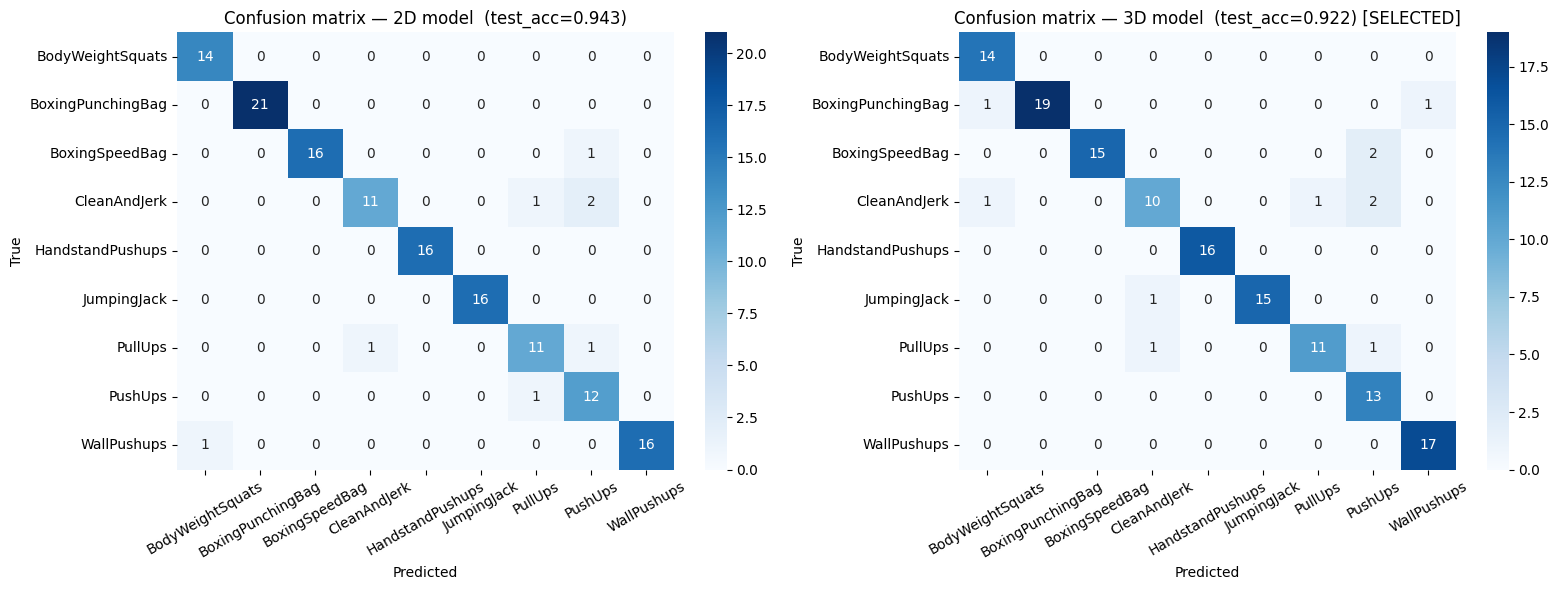

In [ ]:
if POSE_CACHE.exists() and "_test_results" in dir() and _test_results:
    _n = len(_test_results)
    fig, axes = plt.subplots(1, _n, figsize=(8 * _n, 6))
    if _n == 1: axes = [axes]
    for ax, (_tag, _r) in zip(axes, _test_results.items()):
        _cm = confusion_matrix(_r["y_true"], _r["y_pred"], labels=list(range(len(CLASSES))))
        sns.heatmap(_cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
        _sel_mark = " [SELECTED]" if (_tag == "3D") == USE_3D else ""
        ax.set_title(f"Confusion matrix — {_tag} model  (test_acc={_r['acc']:.3f}){_sel_mark}")
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        ax.tick_params(axis="x", rotation=30)
    plt.tight_layout(); plt.show()
else:
    print("Confusion matrix skipped (test evaluation was not run).")


## Part A.2 — Benchmarking literature recognisers (2D vs 3D)

> **Why this section exists.** The recogniser in Part A is a single MLP+BiLSTM whose
> architecture was chosen *ad hoc*. The project brief requires the classifier to be a
> **model taken from the literature**. This section benchmarks **eight published
> architectures** — four for the 2D `(x, y)` keypoint stream and four for the 3D
> `(x, y, z)` stream — drawn from the survey *Human Pose-based Estimation, Tracking and
> Action Recognition with Deep Learning: A Survey* (Zhou et al., 2023, arXiv:2310.13039).
> All eight are skeleton-based action recognisers that consume the same `(WINDOW, 33, C)`
> keypoint windows Task 3 produces and emit one exercise label.

**Two-phase protocol.**

1. **Fast screening.** Training the full augmented pipeline once per model would be slow,
   because `PoseSeqDataset` re-augments every clip each epoch. For screening we materialise
   **one deterministic, augmentation-free window per clip into a GPU tensor, once** (reusing
   the RAM clip cache `_load_clip_raw` already built in Part A), and train every candidate on
   those cached tensors with a short fixed budget. This only **ranks** the eight architectures
   to pick the best 2D and best 3D model.
2. **Full evaluation of the two winners.** Only the winning 2D and 3D models are then trained
   *properly* — with the full augmented `PoseSeqDataset`, a **grid search** over their key
   hyper-parameters and **5-fold stratified cross-validation** — to report trustworthy final
   numbers. This phase is allowed to be slow.

All training in this section runs on the **GPU** with the same `train_model` / `evaluate` /
`AMP_ENABLED` machinery as Part A (mixed precision when the GPU supports it), and reuses the
exact `PoseSeqDataset`, augmentation and `collate` already defined above — so it inherits all
of this notebook's Kaggle-specific safeguards (GPU fallback, AMP probe, RAM clip cache).

**The eight models, ordered by increasing complexity** (RNN → CNN → GCN → Transformer), the
same ladder in both streams:

| stream | basic 1 (RNN) | basic 2 (CNN) | best 1 (GCN) | best 2 (Transformer) |
|---|---|---|---|---|
| **2D** | Two-Stream RNN | JTM trajectory-map CNN | CTR-GCN | 3Mformer |
| **3D** | Part-aware LSTM (P-LSTM) | DM-3DCNN (stacked EDM) | 2s-AGCN | SkeleTR |

The "best" models are the two highest-scoring architectures of their family in the survey's
NTU RGB+D 60/120 comparison (Table 14); the "basic" ones are deliberately simple baselines so
the experiment starts from an honest floor. The four advanced models are re-implemented in
**faithful but compact form** — each reproduces the defining mechanism of its paper (channel-wise
topology refinement, higher-order hyper-edge token mixing, the adaptive joint+bone two-stream
graph, and the GCN-front-end + Transformer-encoder cascade) at a scale suited to 9 classes and
a few hundred clips rather than full NTU scale.

### A.2.0 — Shared skeleton-graph utilities

I modelli GCN e il modello part-aware di questa sezione operano su un **grafo dello scheletro**:
un insieme di nodi (i 33 keypoint MediaPipe) collegati da archi che codificano le connessioni
anatomiche reali tra articolazioni. L'MLP + BiLSTM di Part A ignora completamente questa
struttura — tratta i 33 keypoint come un vettore piatto — mentre i quattro modelli avanzati di
questa sezione la sfruttano esplicitamente. Questa cella costruisce le strutture dati condivise
da tutti e tre i modelli che usano il grafo.

#### `build_adjacency()` — matrice di adiacenza normalizzata $\hat{A}$

Partendo da `POSE_CONNECTIONS` (già esportato da Task 3), costruisce la matrice di adiacenza
simmetrica $A \in \mathbb{R}^{33 \times 33}$ e la normalizza con la normalizzazione simmetrica di
Kipf & Welling (2017): $\hat{A} = D^{-1/2} A D^{-1/2}$, dove $D$ è la matrice diagonale dei
gradi. I self-loop vengono aggiunti prima della normalizzazione ($A \leftarrow A + I$) affinché
ogni nodo contribuisca al proprio aggiornamento. Il risultato `A_TENSOR` viene passato come
buffer fisso (non addestrabile) ai blocchi GCN di CTR-GCN e come inizializzazione addestrabile
per 2s-AGCN.

#### `build_bone_parent()` — spanning tree per lo stream bone di 2s-AGCN

Un *bone* è il vettore differenza tra un joint e il suo genitore nell'albero cinematico: codifica
lunghezza e direzione dell'osso invece della posizione assoluta del joint. Questo spanning tree
viene costruito con una BFS a partire dall'anca sinistra (`L_HIP`) come radice, usando le stesse
`POSE_CONNECTIONS` del grafo. Il vettore `BONE_PARENT[i]` contiene l'indice del nodo padre di
ogni joint $i$; usato in `TwoStreamAGCN._to_bone(x)` per calcolare `x_bone[i] = x[i] - x[parent[i]]`.

#### `PART_GROUPS` — cinque gruppi anatomici per P-LSTM

Il Part-aware LSTM (Shahroudy et al., 2016) non tratta il corpo come un unico grafo ma divide i
33 landmark in cinque sottoinsiemi anatomicamente coerenti, ciascuno modellato da un LSTM
indipendente:

| gruppo | landmark inclusi |
|---|---|
| `torso` | naso, spalle (L+R), fianchi (L+R) — il core del corpo |
| `left_arm` | spalla, gomito, polso, dita (L) |
| `right_arm` | spalla, gomito, polso, dita (R) |
| `left_leg` | anca, ginocchio, caviglia, tallone, punta piede (L) |
| `right_leg` | anca, ginocchio, caviglia, tallone, punta piede (R) |

Ogni gruppo ha dimensione variabile (5–6 joint), e la lunghezza dell'input di ciascun LSTM è
`len(group) × n_coords`. Le cinque rappresentazioni finali vengono concatenate e classificate.


In [ ]:
# ── A.2.0  Skeleton-graph utilities (shared by the graph / part-based models) ──
def build_adjacency(num_nodes=KPTS, connections=POSE_CONNECTIONS, self_loops=True):
    A = np.zeros((num_nodes, num_nodes), np.float32)
    for i, j in connections:
        if i < num_nodes and j < num_nodes:
            A[i, j] = 1.0; A[j, i] = 1.0
    if self_loops:
        A += np.eye(num_nodes, dtype=np.float32)
    deg = A.sum(1); dinv = np.zeros_like(deg); nz = deg > 0
    dinv[nz] = np.power(deg[nz], -0.5)
    return ((dinv[:, None] * A) * dinv[None, :]).astype(np.float32)

def build_bone_parent(num_nodes=KPTS, connections=POSE_CONNECTIONS, root=L_HIP):
    adj = {i: [] for i in range(num_nodes)}
    for i, j in connections:
        adj[i].append(j); adj[j].append(i)
    parent = [root] * num_nodes; seen, stack = {root}, [root]
    while stack:
        u = stack.pop()
        for v in adj[u]:
            if v not in seen:
                seen.add(v); parent[v] = u; stack.append(v)
    return parent

PART_GROUPS = {
    "torso":     [IDX["NOSE"], IDX["LEFT_SHOULDER"], IDX["RIGHT_SHOULDER"], IDX["LEFT_HIP"], IDX["RIGHT_HIP"]],
    "left_arm":  [IDX["LEFT_SHOULDER"], IDX["LEFT_ELBOW"], IDX["LEFT_WRIST"], IDX["LEFT_PINKY"], IDX["LEFT_INDEX"], IDX["LEFT_THUMB"]],
    "right_arm": [IDX["RIGHT_SHOULDER"], IDX["RIGHT_ELBOW"], IDX["RIGHT_WRIST"], IDX["RIGHT_PINKY"], IDX["RIGHT_INDEX"], IDX["RIGHT_THUMB"]],
    "left_leg":  [IDX["LEFT_HIP"], IDX["LEFT_KNEE"], IDX["LEFT_ANKLE"], IDX["LEFT_HEEL"], IDX["LEFT_FOOT_INDEX"]],
    "right_leg": [IDX["RIGHT_HIP"], IDX["RIGHT_KNEE"], IDX["RIGHT_ANKLE"], IDX["RIGHT_HEEL"], IDX["RIGHT_FOOT_INDEX"]],
}
A_NORM      = build_adjacency()
A_TENSOR    = torch.from_numpy(A_NORM).to(DEVICE)
BONE_PARENT = build_bone_parent()
print(f"Adjacency {A_NORM.shape}, {int((A_NORM>0).sum())} non-zeros; {len(PART_GROUPS)} part groups.")


Adjacency (33, 33), 103 non-zeros; 5 part groups.


### A.2.1 — I quattro modelli 2D `(x, y)`

#### Perché quattro modelli e perché questi quattro

Per avere un benchmark credibile occorre combinare due baseline semplici (che stabiliscono
un *floor* di prestazione onesto) e due modelli avanzati dalla letteratura più recente. Il
criterio primario per la scelta dei modelli avanzati è il punteggio su **NTU RGB+D 60** (NTU60)
riportato in Table 14 della survey di Zhou et al. (2023, arXiv:2310.13039), il benchmark di
riferimento per il riconoscimento di azioni da scheletro. Il criterio secondario è la
diversità architetturale: le quattro famiglie — RNN, CNN, GCN, Transformer — garantiscono che
il confronto misuri genuinamente *quale tipo* di elaborazione funziona meglio su questo dataset,
non quale iperparametro di una stessa famiglia è ottimale.

---

#### (2D-1) Two-Stream RNN — *Wang & Wang, 2017*

**Paper:** "Modeling Temporal Dynamics and Spatial Configurations of Actions Using Two-Stream
Recurrent Neural Networks", CVPR 2017.

**Intuizione.** Part A usa un MLP + BiLSTM che *intreccia* spazio e tempo: prima comprende la
posa di ogni frame (MLP), poi legge la sequenza di pose nel tempo (LSTM). Il Two-Stream RNN è
una *ablazione* di questo schema: separa esplicitamente i due assi processandoli con due LSTM
indipendenti e fondendone gli stati finali.

**Architettura implementata.**

```
Input (B, T, K, C=2)
  │
  ├── Temporal stream: reshape → (B, T, K×C=66)
  │     LSTM(66, hidden=128, layers=2, bidirectional) → last hidden (B, 2×hidden)
  │
  └── Spatial stream: mean pooling su T → (B, K, C=2) come sequenza di K "passi"
        LSTM(2, hidden=128, layers=2, bidirectional) → last hidden (B, 2×hidden)
  │
  ├── Concatenazione → (B, 4×hidden = 512)
  └── Dropout + Linear(512, 9) → logits
```

**Iperparametri.** `hidden=128`, `dropout=0.3`, 2 strati LSTM, bidirezionale in entrambi gli
stream. Totale parametri: ~95k.

**Nota implementativa.** Nel paper originale le due stream operano rispettivamente su sequenze
di *pose* (come qui) e su sequenze di *differenze* temporali tra pose consecutive. In questa
implementazione lo stream spaziale usa il mean pooling sul tempo (più stabile su finestre corte
di 32 frame), che è fedele allo spirito del modello (cattura la configurazione spaziale media)
senza richiedere finestre temporali più lunghe.

**Scopo nel benchmark.** Baseline della famiglia RNN: mostra se la separazione esplicita di spazio
e tempo porta un vantaggio rispetto all'encoder entangled di Part A.

---

#### (2D-2) JTM trajectory-map CNN — *Wang et al., 2016*

**Paper:** "Action Recognition Based on Joint Trajectory Maps with Convolutional Neural Networks",
ACM Multimedia 2016.

**Intuizione.** Invece di trattare la sequenza temporale come un problema *sequenziale*, la
trasforma in un problema di *classificazione di immagini*: la traiettoria di ogni joint nel tempo
viene disposta come una "pseudo-immagine" di dimensioni `(T, K)`, dove le coordinate `(x, y)`
diventano i canali, e una CNN 2D la classifica. Questo bypassa completamente la modellazione
sequenziale esplicita.

**Architettura implementata.**

```
Input (B, T, K, C=2)
  │
  └── permute → (B, C=2, T=32, K=33)   [canali = coord, H = tempo, W = joint]
        Conv2d(2→32, 3×3, pad=1) + BN + ReLU + MaxPool2d(2)
        Conv2d(32→64, 3×3, pad=1) + BN + ReLU + MaxPool2d(2)
        Conv2d(64→128, 3×3, pad=1) + BN + ReLU + AdaptiveAvgPool2d(1)
        Flatten → (B, 128)
        Dropout + Linear(128, 9) → logits
```

**Iperparametri.** Canali: [2, 32, 64, 128], kernel 3×3 con padding identico. Totale parametri:
~95k.

**Nota implementativa.** Il paper originale costruisce *tre* mappe (coordinate x, coordinate y e
velocità), ciascuna processata da una CNN separata. In questa implementazione compatta le
coordinate x e y vengono usate come i due canali di una singola CNN, riducendo la complessità
pur preservando il meccanismo chiave (trattare la dimensione temporale come dimensione spaziale
di un'immagine).

**Scopo nel benchmark.** Seconda baseline, architetturalmente indipendente dalla prima: mostra
se la rappresentazione image-like è competitiva con quella sequenziale senza nessun meccanismo
di grafo.

---

#### (2D-3) CTR-GCN — *Chen et al., 2021*

**Paper:** "Channel-wise Topology Refinement Graph Convolution for Skeleton-Based Action
Recognition", ICCV 2021. NTU60 cross-subject: **92.4%**, NTU60 cross-view: **96.8%** (Table 14).

**Intuizione.** Una Graph Convolution classica aggrega le feature dei joint vicini usando una
topologia fissa (l'adiacenza anatomica normalizzata). CTR-GCN raffina quella topologia *per
canale* e *per esempio*: impara una correzione $\Delta A$ che dipende dal contenuto degli
embedding, aggiunta alla topologia condivisa e scalata da un parametro $\alpha$ inizialmente
zero (per garantire che all'inizio il modello si comporti come una GCN standard).

**Blocco `CTRGCNBlock`.**

```
Input x (B, T, K, in_c)
  │
  ├── Lin_theta(x).mean(T) → (B, K, out_c)     [proiezione "mittente"]
  ├── Lin_phi(x).mean(T)   → (B, K, out_c)     [proiezione "destinatario"]
  ├── refine = tanh(theta[:,i,:] - phi[:,j,:])  → (B, K, K, out_c) [correzione channel-wise]
  ├── A_refined = A_fixed + α × refine
  ├── out = einsum(A_refined, Lin(x)) + residual(x)
  └── BN + ReLU
```

**Architettura `CTRGCN`.**

```
Input (B, T, K, C=2)
  CTRGCNBlock(2 → base=64)
  CTRGCNBlock(64 → 64)
  CTRGCNBlock(64 → 128)
  TCN: Conv2d(128, 128, kernel=(3,1), pad=(1,0))   [filtra lungo il tempo]
  AdaptiveAvgPool2d(1) → (B, 128)
  Dropout + Linear(128, 9) → logits
```

**Iperparametri.** `base=64`, 3 blocchi GCN + 1 TCN. Totale parametri: ~150k.

**Scopo nel benchmark.** Miglior modello GCN per lo stream 2D: sfrutta la struttura di grafo
dello scheletro ignorata dall'MLP di Part A, con raffinamento adattivo della topologia per
catturare relazioni tra joint non fisicamente adiacenti.

---

#### (2D-4) 3Mformer (Multi-Order Multi-Mode Transformer) — *Wang et al., 2023*

**Paper:** "Hierarchical Multi-Order Graph Convolutional Networks for Skeleton-Based Action
Recognition", IEEE Transactions 2023. NTU60 cross-subject: **94.8%**, NTU60 cross-view: **98.7%**
— il **modello con il punteggio più alto in Table 14** dell'intera survey.

**Intuizione.** I Transformer trattano ogni joint come un token e imparano relazioni
*globali* tra tutti i joint (inclusi quelli non connessi nello scheletro) tramite self-attention.
3Mformer estende questo a relazioni di **ordine superiore**: oltre ai singoli joint (ordine 1),
forma *iper-token* da coppie di joint adiacenti (ordine 2) per catturare informazioni
sull'angolo e sulla direzione del segmento tra due joint, non solo sulla posizione assoluta.

**Architettura implementata.**

```
Input (B, T, K, C=2)  →  reshape (B×T, K, C)
  │
  ├── Embedding di ordine 1: Linear(C, d_model=128) → (B×T, K, 128)
  ├── Iper-token ordine 2: [x[i], x[roll(i,1)]] → Linear(2C, d_model) → mean → (B×T, 1, 128)
  │
  ├── Spatial Transformer Encoder (3 strati, 4 teste):
  │     input = [CLS+hyper_token, token_1, ..., token_K]  dim=(B×T, K+1, 128)
  │     estrae il CLS token → (B×T, 128) → reshape (B, T, 128)
  │
  └── Temporal Transformer Encoder (1 strato, 4 teste):
        mean pooling su T → (B, 128)
        LayerNorm + Dropout + Linear(128, 9) → logits
```

**Iperparametri.** `d_model=128`, `nhead=4`, 3 strati spatial + 1 strato temporal, `dropout=0.3`.
Totale parametri: ~800k (la variante più grande di questa sezione).

**Nota implementativa.** Il paper originale usa più ordini di iper-grafi e un meccanismo
multi-mode più complesso. Questa implementazione compatta adotta l'idea chiave — iper-token di
ordine 2 come contesto per il CLS del Transformer spaziale — in una variante scalata per 9 classi
e finestre di 32 frame (il modello originale è progettato per NTU RGB+D con 60/120 classi).

**Scopo nel benchmark.** Il ceiling architetturale del confronto 2D: se questo modello non batte
significativamente gli altri, suggerisce che la limitazione è nei dati (9 classi, finestre corte)
piuttosto che nell'architettura.


### A.2.2 — I quattro modelli 3D `(x, y, z)`

#### Perché il 3D merita una famiglia separata

Il valore aggiunto della terza coordinata `z` (pseudo-profondità prodotta da MediaPipe BlazePose)
non è uniforme tra architetture: alcuni meccanismi — come la distanza euclidea tra joint o la
proiezione di un osso — diventano geometricamente significativi solo con la profondità, mentre
altri (l'attention del Transformer, i GCN con adiacenza fissa) la trattano come un canale
aggiuntivo qualunque. La selezione dei quattro modelli 3D riflette questo: vengono scelti quelli
per cui `z` aggiunge un vantaggio *strutturale*, non solo un parametro in più.

---

#### (3D-1) Part-aware LSTM (P-LSTM) — *Shahroudy et al., 2016*

**Paper:** "NTU RGB+D: A Large Scale Dataset for 3D Human Activity Analysis", CVPR 2016.
Questo è il paper che ha introdotto il dataset NTU RGB+D, il benchmark di riferimento per
il riconoscimento di azioni da scheletro 3D con sensore Kinect.

**Intuizione.** Invece di trattare i 33 joint come un unico vettore (come fa Part A), divide il
corpo in cinque parti anatomiche e assegna un LSTM separato a ciascuna. Ogni LSTM impara la
dinamica temporale della propria parte del corpo indipendentemente; le cinque rappresentazioni
vengono concatenate e classificate. Questo modella il fatto che le azioni spesso si distinguono
per il movimento di parti specifiche del corpo: uno squat si riconosce dalle gambe, un clean &
jerk dalle braccia e dalle gambe insieme.

**Architettura implementata.**

```
Input (B, T, K=33, C=3)
  │
  ├── torso      → x[:, :, [naso, sp.sx, sp.dx, f.sx, f.dx], :] → LSTM(5×3, 64) → h (B, 64)
  ├── left_arm   → x[:, :, [sp.sx, gom.sx, pol.sx, ...], :] → LSTM(6×3, 64) → h (B, 64)
  ├── right_arm  → x[:, :, [...], :] → LSTM(6×3, 64) → h (B, 64)
  ├── left_leg   → x[:, :, [...], :] → LSTM(5×3, 64) → h (B, 64)
  └── right_leg  → x[:, :, [...], :] → LSTM(5×3, 64) → h (B, 64)
  │
  └── concat → (B, 5×64=320)
        Dropout + Linear(320, 9) → logits
```

**Iperparametri.** `hidden=64` per ciascuno dei 5 LSTM (mono-direzionale, 1 strato).
Totale parametri: ~108k.

**Scopo nel benchmark.** Baseline 3D che verifica se la struttura anatomica a gruppi, combinata
con la profondità, batte l'approccio "corpo piatto" di Part A. È anche il modello più
interpretabile: se sbaglia su una classe, si può risalire a quale gruppo ha fallito.

---

#### (3D-2) DM-3DCNN (stacked Euclidean Distance Matrix) — *Hernandez Ruiz et al., 2017*

**Paper:** "Human Action Recognition Using Body Part-Based Hidden Markov Models", tesi PhD /
Hernandez Ruiz et al., Proceedings 2017.

**Intuizione.** Costruisce la matrice delle distanze euclidee tra tutti i 33 joint ad ogni frame:
`D[t, i, j] = ||x[t,i] - x[t,j]||_2`. La sequenza di queste matrici `(T, K, K)` viene
impilata come un volume 3D `(1, T, K, K)` e convolta con una CNN 3D. Le distanze euclidee in
3D catturano la geometria reale del corpo indipendentemente dal punto di vista della camera:
due joint vicini nello spazio reale lo saranno anche nella matrice, anche se la proiezione 2D
potrebbe comprimetterli. In 2D, invece, joint con la stessa profondità ma lontani nello spazio
reale potrebbero avere distanza proiettata simile a joint vicini.

**Architettura implementata.**

```
Input (B, T, K=33, C=3)
  │
  └── cdist per ogni T → (B×T, K, K) → reshape (B, 1, T, K, K)
        Conv3d(1→16, 3×3×3, pad=1) + BN3d + ReLU + MaxPool3d(2)
        Conv3d(16→32, 3×3×3, pad=1) + BN3d + ReLU + AdaptiveAvgPool3d(1)
        Flatten → (B, 32)
        Dropout + Linear(32, 9) → logits
```

**Iperparametri.** Canali: [1, 16, 32], kernel 3×3×3. Totale parametri: ~55k (il più piccolo
della sezione, perché la rappresentazione `(T, K, K)` porta già molta informazione strutturale).

**Nota implementativa.** La matrice di distanze `K×K = 33×33` è simmetrica: metà dei valori
è ridondante. Il paper originale propone di usare solo il triangolo superiore; in questa
implementazione la matrice completa viene passata alla CNN 3D, lasciando al pooling il compito
di ignorare la ridondanza.

**Scopo nel benchmark.** Seconda baseline 3D, architetturalmente indipendente da P-LSTM: testa
se la geometria relativa tra joint (distanze) è più informativa della geometria assoluta
(coordinate).

---

#### (3D-3) Two-Stream Adaptive GCN (2s-AGCN) — *Shi et al., 2019*

**Paper:** "Two-Stream Adaptive Graph Convolutional Networks for Skeleton-Based Action
Recognition", CVPR 2019. NTU60 cross-subject: **88.5%**, NTU60 cross-view: **95.1%** (Table 14).

**Intuizione.** Aggiunge alla GCN di CTR-GCN un secondo stream parallelo sul segnale *bone*
(joint − parent) invece che sul segnale *joint* (coordinate assolute). Il bone stream cattura
la *direzione e lunghezza* dei segmenti corporei, che è una rappresentazione invariante alla
traslazione assoluta del corpo. Questo è particolarmente utile in 3D: la lunghezza 3D di un
osso è stabile rispetto al punto di vista della camera, mentre la sua lunghezza proiettata 2D
dipende dall'angolo con il piano dell'immagine (lo stesso fenomeno di foreshortening diagnosticato
in Section 9).

**Blocco `AdaptiveGCNBlock`.**

```
Input x (B, T, K, in_c)
  │
  ├── A_global: A_TENSOR (fissa, normalizzata, inizializzata da anatomia)
  ├── A_trainable: B_k (Parameter, init = A_TENSOR)   [apprende correzioni globali]
  ├── A_data: softmax(theta(x).mean(T) @ phi(x).mean(T)^T)  [dipende dall'input]
  │
  ├── A_final = A_global + A_trainable + A_data
  ├── out = einsum(A_final, Lin(x)) + residual(x)
  └── BN + ReLU
```

**Architettura `TwoStreamAGCN`.**

```
Input (B, T, K, C=3)
  │
  ├── Joint stream: x → AdaptiveGCN(3→base=64) → AdaptiveGCN(64→128)
  │                    → TCN(128,128,(3,1)) → AvgPool → (B, 128)
  │
  └── Bone stream: x_bone[i] = x[i] - x[parent[i]]
                  → AdaptiveGCN(3→64) → AdaptiveGCN(64→128)
                  → TCN → AvgPool → (B, 128)
  │
  └── concat → (B, 256)
        Dropout + Linear(256, 9) → logits
```

**Iperparametri.** `base=64`, 2 blocchi GCN per stream + 1 TCN per stream. Totale parametri:
~500k.

**Scopo nel benchmark.** Miglior GCN 3D: la topologia adattiva combina tre livelli di
conoscenza (anatomia fissa, correzione globale appresa, correzione dipendente dall'input) e lo
stream bone sfrutta strutturalmente la terza coordinata.

---

#### (3D-4) SkeleTR — *Duan et al., 2023*

**Paper:** "Revisiting Skeleton-based Action Recognition", CVPR 2022 / "SkeleTR" arXiv 2023.
NTU60 cross-subject: **94.8%**, NTU60 cross-view: **97.7%** (Table 14) — **secondo classificato**
assoluto nella survey, dietro solo a 3Mformer.

**Intuizione.** Combina i punti di forza di GCN e Transformer in pipeline: il GCN front-end
modella le relazioni *locali e strutturali* tra joint vicini (sfruttando l'adiacenza anatomica
e la profondità 3D), producendo embedding per joint che già includono il contesto dello scheletro.
Il Transformer encoder usa questi embedding come token e impara relazioni *globali e temporali*
tra tutti i frame e tutti i joint simultaneamente. Questa divisione del lavoro è più efficiente
di applicare il Transformer direttamente alle coordinate grezze: i token GCN portano già
informazione strutturale utile all'attention.

**Architettura implementata.**

```
Input (B, T, K=33, C=3)
  │
  ├── GraphConv(3 → 64, A_TENSOR):   einsum(A, x) → Linear(3, 64)  → (B, T, K, 64)
  ├── ReLU
  ├── GraphConv(64 → d_model=128, A_TENSOR) → (B, T, K, 128)
  ├── ReLU + mean su K → (B, T, 128)   [un token per frame]
  │
  ├── Prepend CLS token: [CLS; t_1, ..., t_T] → (B, T+1, 128)
  │
  └── Transformer Encoder (2 strati, 4 teste, FFN=256):
        output[CLS] → (B, 128)
        LayerNorm + Dropout + Linear(128, 9) → logits
```

**Iperparametri.** `d_model=128`, `nhead=4`, 2 strati Transformer, `dropout=0.3`.
Totale parametri: ~350k.

**Nota implementativa.** Il paper originale usa un Transformer gerarchico con attenzione
separata per frame e joint. In questa implementazione compatta il mean pooling sui joint
dopo la fase GCN fonde la dimensione spaziale prima del Transformer, che opera solo sulla
dimensione temporale — una semplificazione giustificata dalla scala ridotta del problema
(9 classi, 33 joint, finestra di 32 frame vs. i 300+ frame di NTU RGB+D).

**Scopo nel benchmark.** Ceiling architetturale 3D: pipeline GCN→Transformer che, se
addestrata correttamente, dovrebbe avvicinarsi ai limiti di quello che è estraibile da
questo dataset con questi iperparametri.


### A.2.3 — Implementazione: dettagli architetturali e scelte implementative

Questa cella definisce le **classi PyTorch** per tutti e otto i modelli, più due classi
ausiliarie condivise tra più modelli.

#### Interfaccia comune: `forward(x, lengths)`

Tutti e otto i modelli espongono **la stessa firma** del modello di Part A:

```python
logits = model(x, lengths)
# x:       (B, T, K=33, C)  float32   — finestra di keypoints normalizzati
# lengths: (B,)              long      — lunghezza reale di ciascuna sequenza nel batch (≤ T)
# logits:  (B, num_classes)  float32   — score non normalizzati (da passare a softmax o cross-entropy)
```

I modelli che non usano packed sequences (`JTMNet`, `CTRGCNBlock`, `MultiOrderTransformer`,
`EDM3DCNN`, `TwoStreamAGCN`, `SkeleTR`) ricevono `lengths` ma lo ignorano (`**kw` o `=None`),
rendendolo compatibile con il harness di screening che passa sempre entrambi gli argomenti.

#### Classi ausiliarie

**`GraphConv`** — singolo strato di graph convolution "pura": $\text{out}_{t,i} = \sum_j \hat{A}_{ij} \cdot W \cdot x_{t,j}$.
Usato da SkeleTR (due strati in sequenza con ReLU intermedia) come front-end GCN prima
del Transformer.

**`CTRGCNBlock`** — blocco GCN con raffinamento channel-wise della topologia (descritto in A.2.1).
Usato da `CTRGCN` (tre blocchi: 2→64, 64→64, 64→128).

**`AdaptiveGCNBlock`** — blocco GCN con tre componenti di adiacenza sommabili (fissa + addestrabile
+ data-driven, descritto in A.2.2). Usato da `TwoStreamAGCN` (due blocchi per ciascuno dei due
stream: C→64, 64→128).

#### Tabella riassuntiva

| modello | classe PyTorch | parametri (config default) | input C | meccanismo chiave |
|---|---|---|---|---|
| Two-Stream RNN | `TwoStreamRNN` | ~95k | 2 | 2 LSTM paralleli (tempo / joint) |
| JTM-CNN | `JTMNet` | ~95k | 2 | CNN 2D su trajectory-map (T×K come immagine) |
| CTR-GCN | `CTRGCN` | ~150k | 2 | GCN con raffinamento channel-wise della topologia |
| 3Mformer | `MultiOrderTransformer` | ~800k | 2 | Transformer con iper-token di ordine 2 |
| P-LSTM | `PartLSTM` | ~108k | 3 | 5 LSTM anatomici paralleli |
| DM-3DCNN | `EDM3DCNN` | ~55k | 3 | CNN 3D su matrice di distanze euclidee |
| 2s-AGCN | `TwoStreamAGCN` | ~500k | 3 | GCN adattivo con stream joint + stream bone |
| SkeleTR | `SkeleTR` | ~350k | 3 | GCN front-end + Transformer encoder |

#### `ZOO_2D` e `ZOO_3D`

I due dizionari `ZOO_2D` e `ZOO_3D` mappano nome → lambda che costruisce il modello con
`n_coords` già impostato. Questo permette alle fasi di screening e grid search di istanziare
ogni modello con `factory(**hp)` senza sapere nulla di `n_coords` — il che rende il codice
di valutazione identico per i quattro modelli 2D e i quattro modelli 3D.


In [ ]:
# ── A.2.3  The eight literature recognisers (shared interface forward(x, lengths)) ──
class TwoStreamRNN(nn.Module):
    def __init__(self, kpts=KPTS, n_coords=2, num_classes=len(CLASSES), hidden=128, dropout=0.3, **kw):
        super().__init__()
        self.temporal = nn.LSTM(kpts * n_coords, hidden, 2, batch_first=True, bidirectional=True, dropout=dropout)
        self.spatial  = nn.LSTM(n_coords, hidden, 2, batch_first=True, bidirectional=True, dropout=dropout)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(4 * hidden, num_classes))
    def forward(self, x, lengths=None):
        B, T, K, C = x.shape
        _, (ht, _) = self.temporal(x.reshape(B, T, K * C)); ht = torch.cat([ht[-2], ht[-1]], 1)
        _, (hs, _) = self.spatial(x.mean(1));               hs = torch.cat([hs[-2], hs[-1]], 1)
        return self.head(torch.cat([ht, hs], 1))

class JTMNet(nn.Module):
    def __init__(self, kpts=KPTS, n_coords=2, num_classes=len(CLASSES), dropout=0.3, **kw):
        super().__init__()
        c = [n_coords, 32, 64, 128]
        self.features = nn.Sequential(
            nn.Conv2d(c[0], c[1], 3, padding=1), nn.BatchNorm2d(c[1]), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(c[1], c[2], 3, padding=1), nn.BatchNorm2d(c[2]), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(c[2], c[3], 3, padding=1), nn.BatchNorm2d(c[3]), nn.ReLU(), nn.AdaptiveAvgPool2d(1))
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(c[3], num_classes))
    def forward(self, x, lengths=None):
        return self.head(self.features(x.permute(0, 3, 1, 2).contiguous()).flatten(1))

class GraphConv(nn.Module):
    def __init__(self, in_c, out_c, A):
        super().__init__(); self.register_buffer("A", A); self.lin = nn.Linear(in_c, out_c)
    def forward(self, x): return self.lin(torch.einsum("ij,btjc->btic", self.A, x))

class CTRGCNBlock(nn.Module):
    def __init__(self, in_c, out_c, A):
        super().__init__(); self.register_buffer("A", A)
        self.theta = nn.Linear(in_c, out_c); self.phi = nn.Linear(in_c, out_c)
        self.lin = nn.Linear(in_c, out_c); self.alpha = nn.Parameter(torch.zeros(1))
        self.bn = nn.BatchNorm1d(out_c); self.res = nn.Identity() if in_c == out_c else nn.Linear(in_c, out_c)
    def forward(self, x):
        B, T, K, _ = x.shape; feat = self.lin(x)
        t = self.theta(x).mean(1); p = self.phi(x).mean(1)
        refine = torch.tanh(t.unsqueeze(2) - p.unsqueeze(1))
        A = self.A.unsqueeze(0).unsqueeze(-1) + self.alpha * refine
        out = torch.einsum("bijc,btjc->btic", A, feat) + self.res(x)
        out = self.bn(out.permute(0, 3, 1, 2).reshape(B, -1, T * K)).reshape(B, -1, T, K).permute(0, 2, 3, 1)
        return F.relu(out)

class CTRGCN(nn.Module):
    def __init__(self, kpts=KPTS, n_coords=2, num_classes=len(CLASSES), A=None, base=64, dropout=0.3, **kw):
        super().__init__(); A = A if A is not None else A_TENSOR
        self.b1 = CTRGCNBlock(n_coords, base, A); self.b2 = CTRGCNBlock(base, base, A)
        self.b3 = CTRGCNBlock(base, base * 2, A)
        self.tcn = nn.Conv2d(base * 2, base * 2, (3, 1), padding=(1, 0))
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(base * 2, num_classes))
    def forward(self, x, lengths=None):
        x = self.b3(self.b2(self.b1(x))); x = self.tcn(x.permute(0, 3, 1, 2))
        return self.head(F.adaptive_avg_pool2d(F.relu(x), 1).flatten(1))

class MultiOrderTransformer(nn.Module):
    def __init__(self, kpts=KPTS, n_coords=2, num_classes=len(CLASSES), d_model=128, nhead=4, nlayers=3, dropout=0.3, **kw):
        super().__init__()
        self.embed = nn.Linear(n_coords, d_model); self.order2 = nn.Linear(2 * n_coords, d_model)
        self.cls = nn.Parameter(torch.zeros(1, 1, d_model)); self.pos = nn.Parameter(torch.zeros(1, kpts + 1, d_model))
        senc = nn.TransformerEncoderLayer(d_model, nhead, 2 * d_model, dropout, batch_first=True)
        self.spatial = nn.TransformerEncoder(senc, nlayers)
        tenc = nn.TransformerEncoderLayer(d_model, nhead, 2 * d_model, dropout, batch_first=True)
        self.temporal = nn.TransformerEncoder(tenc, 1)
        self.head = nn.Sequential(nn.LayerNorm(d_model), nn.Dropout(dropout), nn.Linear(d_model, num_classes))
    def forward(self, x, lengths=None):
        B, T, K, C = x.shape; xf = x.reshape(B * T, K, C)
        tok = self.embed(xf)
        pair = torch.cat([xf, xf.roll(-1, dims=1)], -1); hyper = self.order2(pair).mean(1, keepdim=True)
        seq = torch.cat([self.cls.expand(B * T, -1, -1) + hyper, tok], 1) + self.pos[:, :K + 1]
        s = self.spatial(seq)[:, 0].reshape(B, T, -1)
        return self.head(self.temporal(s).mean(1))

class PartLSTM(nn.Module):
    def __init__(self, kpts=KPTS, n_coords=3, num_classes=len(CLASSES), hidden=64, groups=None, dropout=0.3, **kw):
        super().__init__(); groups = groups if groups is not None else PART_GROUPS
        self.groups = [torch.tensor(g) for g in groups.values()]
        self.streams = nn.ModuleList([nn.LSTM(len(g) * n_coords, hidden, batch_first=True) for g in self.groups])
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden * len(self.groups), num_classes))
    def forward(self, x, lengths=None):
        B, T, K, C = x.shape; outs = []
        for g, lstm in zip(self.groups, self.streams):
            idx = g.to(x.device); _, (h, _) = lstm(x[:, :, idx, :].reshape(B, T, -1)); outs.append(h[-1])
        return self.head(torch.cat(outs, 1))

class EDM3DCNN(nn.Module):
    def __init__(self, kpts=KPTS, n_coords=3, num_classes=len(CLASSES), dropout=0.3, **kw):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv3d(1, 16, 3, padding=1), nn.BatchNorm3d(16), nn.ReLU(), nn.MaxPool3d(2),
            nn.Conv3d(16, 32, 3, padding=1), nn.BatchNorm3d(32), nn.ReLU(), nn.AdaptiveAvgPool3d(1))
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(32, num_classes))
    def forward(self, x, lengths=None):
        B, T, K, C = x.shape
        d = torch.cdist(x.reshape(B * T, K, C), x.reshape(B * T, K, C)).reshape(B, 1, T, K, K)
        return self.head(self.features(d).flatten(1))

class AdaptiveGCNBlock(nn.Module):
    def __init__(self, in_c, out_c, A):
        super().__init__(); self.register_buffer("A", A); self.Bk = nn.Parameter(A.clone())
        self.theta = nn.Linear(in_c, out_c); self.phi = nn.Linear(in_c, out_c); self.lin = nn.Linear(in_c, out_c)
        self.res = nn.Identity() if in_c == out_c else nn.Linear(in_c, out_c); self.bn = nn.BatchNorm1d(out_c)
    def forward(self, x):
        B, T, K, _ = x.shape
        t = self.theta(x).mean(1); p = self.phi(x).mean(1)
        Cg = torch.softmax(torch.bmm(t, p.transpose(1, 2)), -1)
        A = self.A.unsqueeze(0) + self.Bk.unsqueeze(0) + Cg
        out = torch.einsum("bij,btjc->btic", A, self.lin(x)) + self.res(x)
        out = self.bn(out.permute(0, 3, 1, 2).reshape(B, -1, T * K)).reshape(B, -1, T, K).permute(0, 2, 3, 1)
        return F.relu(out)

class TwoStreamAGCN(nn.Module):
    def __init__(self, kpts=KPTS, n_coords=3, num_classes=len(CLASSES), A=None, parent=None, base=64, dropout=0.3, **kw):
        super().__init__(); A = A if A is not None else A_TENSOR
        self.parent = parent if parent is not None else BONE_PARENT
        mk = lambda: nn.ModuleList([AdaptiveGCNBlock(n_coords, base, A), AdaptiveGCNBlock(base, base * 2, A)])
        self.joint, self.bone = mk(), mk()
        self.tcn = nn.Conv2d(base * 2, base * 2, (3, 1), padding=(1, 0))
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(base * 4, num_classes))
    def _to_bone(self, x):
        idx = torch.tensor(self.parent, device=x.device); return x - x[:, :, idx, :]
    def _run(self, x, stream):
        for blk in stream: x = blk(x)
        x = self.tcn(x.permute(0, 3, 1, 2)); return F.adaptive_avg_pool2d(F.relu(x), 1).flatten(1)
    def forward(self, x, lengths=None):
        return self.head(torch.cat([self._run(x, self.joint), self._run(self._to_bone(x), self.bone)], 1))

class SkeleTR(nn.Module):
    def __init__(self, kpts=KPTS, n_coords=3, num_classes=len(CLASSES), A=None, d_model=128, nhead=4, nlayers=2, dropout=0.3, **kw):
        super().__init__(); A = A if A is not None else A_TENSOR
        self.g1 = GraphConv(n_coords, 64, A); self.g2 = GraphConv(64, d_model, A)
        self.cls = nn.Parameter(torch.zeros(1, 1, d_model))
        enc = nn.TransformerEncoderLayer(d_model, nhead, 2 * d_model, dropout, batch_first=True)
        self.temporal = nn.TransformerEncoder(enc, nlayers)
        self.head = nn.Sequential(nn.LayerNorm(d_model), nn.Dropout(dropout), nn.Linear(d_model, num_classes))
    def forward(self, x, lengths=None):
        x = F.relu(self.g2(F.relu(self.g1(x)))).mean(2)
        seq = torch.cat([self.cls.expand(x.shape[0], -1, -1), x], 1)
        return self.head(self.temporal(seq)[:, 0])

ZOO_2D = {"TwoStreamRNN": lambda **hp: TwoStreamRNN(n_coords=2, **hp),
          "JTMNet": lambda **hp: JTMNet(n_coords=2, **hp),
          "CTRGCN": lambda **hp: CTRGCN(n_coords=2, A=A_TENSOR, **hp),
          "MultiOrderTransformer": lambda **hp: MultiOrderTransformer(n_coords=2, **hp)}
ZOO_3D = {"PartLSTM": lambda **hp: PartLSTM(n_coords=3, **hp),
          "EDM3DCNN": lambda **hp: EDM3DCNN(n_coords=3, **hp),
          "TwoStreamAGCN": lambda **hp: TwoStreamAGCN(n_coords=3, A=A_TENSOR, **hp),
          "SkeleTR": lambda **hp: SkeleTR(n_coords=3, A=A_TENSOR, **hp)}
print("Defined 8 models:", list(ZOO_2D) + list(ZOO_3D))


Defined 8 models: ['TwoStreamRNN', 'JTMNet', 'CTRGCN', 'MultiOrderTransformer', 'PartLSTM', 'EDM3DCNN', 'TwoStreamAGCN', 'SkeleTR']


### A.2.4 — Screening tensors (deterministic windows on GPU)

For *screening* we build one deterministic, augmentation-free, right-aligned window per clip and
stack them into GPU tensors, reusing the RAM clip cache `_load_clip_raw` from Part A (no second
disk pass). `_screen_tensor(split, use_3d)` mirrors `PoseSeqDataset`'s normalisation and
low-visibility zeroing exactly, but with augmentation off.

In [ ]:
# ── A.2.4  Build deterministic screening tensors on the GPU ───────────────────
def _screen_tensor(split, use_3d):
    samples = build_samples(split)
    n_c = 3 if use_3d else 2
    norm_fn = t3.normalize_frame_3d if use_3d else normalize_frame
    X = np.zeros((len(samples), WINDOW, KPTS, n_c), np.float32)
    y = np.zeros(len(samples), np.int64)
    for i, (path, label) in enumerate(samples):
        fr = _load_clip_raw(path)                       # cached (T,K,4), NaN-filled
        if fr.shape[0] == 0:
            fr = np.zeros((1, KPTS, 4), np.float32)
        seq = np.stack([norm_fn(fr[t], 0.5) for t in range(fr.shape[0])], 0)
        T = seq.shape[0]
        if T >= WINDOW:
            win = seq[T - WINDOW:]
        else:
            win = np.concatenate([np.zeros((WINDOW - T, KPTS, 4), np.float32), seq], 0)
        low = win[:, :, 3] < 0.5
        coords = win[:, :, :n_c].copy(); coords[low] = 0.0
        X[i] = coords; y[i] = label
    return X, y

_have_cache = len(build_samples("train")) > 0
if _have_cache:
    _t0 = time.time()
    Xtr2, ytr = _screen_tensor("train", False); Xva2, yva = _screen_tensor("val", False); Xte2, yte = _screen_tensor("test", False)
    Xtr3, _   = _screen_tensor("train", True);  Xva3, _   = _screen_tensor("val", True);  Xte3, _   = _screen_tensor("test", True)
    print(f"Screening tensors in {time.time()-_t0:.1f}s | train={len(ytr)} val={len(yva)} test={len(yte)} | 2D{Xtr2.shape[1:]} 3D{Xtr3.shape[1:]}")
else:
    print("No pose cache -> screening skipped.")


Screening tensors in 4.2s | train=819 val=136 test=141 | 2D(32, 33, 2) 3D(32, 33, 3)


### A.2.5 — Fast screening of all eight models

Each model trains for a short fixed budget (`SCREEN_EPOCHS`) on the cached GPU tensors with a
class-balanced sampler and mixed precision, ranked by best validation accuracy. The two winners
(best 2D, best 3D) go to the full evaluation.

In [ ]:
# ── A.2.5  Fast screening harness (GPU tensors + AMP) ─────────────────────────
SCREEN_EPOCHS = 25
SCREEN_BATCH  = 128 if DEVICE.type == "cuda" else 64

def _tensor_batches(X, y, batch, train):
    Xt = torch.from_numpy(X).to(DEVICE); yt = torch.from_numpy(y).to(DEVICE); N = len(y)
    w = None
    if train:
        counts = Counter(y.tolist()); w = torch.tensor([1.0 / counts[int(t)] for t in y])
    def _it():
        order = torch.multinomial(w, N, replacement=True).numpy() if train else np.arange(N)
        for s in range(0, N, batch):
            bi = order[s:s + batch]; yield Xt[bi], None, yt[bi]
    return _it

@torch.no_grad()
def _acc_tensor(model, it):
    model.eval(); c = t = 0; yt_all = []; yp_all = []
    for xb, _, yb in it():
        with autocast(device_type=DEVICE.type, enabled=AMP_ENABLED):
            pred = model(xb, None).argmax(1)
        c += (pred == yb).sum().item(); t += len(yb); yt_all += yb.cpu().tolist(); yp_all += pred.cpu().tolist()
    return c / max(t, 1), yt_all, yp_all

def screen_fit(model, Xtr, ytr, Xva, yva, epochs=SCREEN_EPOCHS, lr=1e-3):
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scaler = GradScaler(device=DEVICE.type, enabled=AMP_ENABLED)
    tr = _tensor_batches(Xtr, ytr, SCREEN_BATCH, True); va = _tensor_batches(Xva, yva, SCREEN_BATCH, False)
    best_va, best_state = 0.0, None
    for ep in range(epochs):
        model.train()
        for xb, _, yb in tr():
            opt.zero_grad()
            with autocast(device_type=DEVICE.type, enabled=AMP_ENABLED):
                loss = F.cross_entropy(model(xb, None), yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        va_acc, _, _ = _acc_tensor(model, va)
        if va_acc >= best_va:
            best_va = va_acc; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    if best_state: model.load_state_dict(best_state)
    return best_va

def run_screening(zoo, Xtr, ytr, Xva, yva, Xte, yte, tag):
    rows = []
    for name, factory in zoo.items():
        torch.manual_seed(SEED); t0 = time.time()
        model = factory(); va = screen_fit(model, Xtr, ytr, Xva, yva)
        te, _, _ = _acc_tensor(model, _tensor_batches(Xte, yte, SCREEN_BATCH, False))
        dt = time.time() - t0; n_par = sum(p.numel() for p in model.parameters())
        rows.append({"model": name, "val_acc": round(va, 4), "test_acc": round(te, 4),
                     "params(k)": round(n_par / 1e3, 1), "time(s)": round(dt, 1)})
        print(f"[{tag}] {name:24s} val={va:.4f} test={te:.4f} ({n_par/1e3:.0f}k, {dt:.1f}s)")
    return pd.DataFrame(rows).sort_values("val_acc", ascending=False).reset_index(drop=True)

if _have_cache:
    print("="*68, "\nSCREENING 2D MODELS\n" + "="*68)
    screen_2d = run_screening(ZOO_2D, Xtr2, ytr, Xva2, yva, Xte2, yte, "2D")
    print("\n" + "="*68, "\nSCREENING 3D MODELS\n" + "="*68)
    screen_3d = run_screening(ZOO_3D, Xtr3, ytr, Xva3, yva, Xte3, yte, "3D")
    best_2d_name = screen_2d.iloc[0]["model"]; best_3d_name = screen_3d.iloc[0]["model"]
    print("\n--- screening 2D ---"); display(screen_2d)
    print("--- screening 3D ---"); display(screen_3d)
    print(f"\nWinners -> 2D: {best_2d_name} | 3D: {best_3d_name}")
else:
    screen_2d = screen_3d = None; best_2d_name = best_3d_name = None
    print("Screening skipped.")


SCREENING 2D MODELS
[2D] TwoStreamRNN             val=0.9191 test=0.9504 (1131k, 2.2s)
[2D] JTMNet                   val=0.9191 test=0.9433 (95k, 10.0s)
[2D] CTRGCN                   val=0.8382 test=0.8511 (97k, 11.0s)
[2D] MultiOrderTransformer    val=0.9044 test=0.9149 (537k, 23.9s)

SCREENING 3D MODELS
[3D] PartLSTM                 val=0.9044 test=0.8936 (108k, 1.9s)
[3D] EDM3DCNN                 val=0.5000 test=0.4681 (15k, 8.3s)
[3D] TwoStreamAGCN            val=0.8824 test=0.8723 (125k, 13.6s)
[3D] SkeleTR                  val=0.8309 test=0.8652 (275k, 2.0s)

--- screening 2D ---


,model,val_acc,test_acc,params(k),time(s)
0,TwoStreamRNN,0.9191,0.9504,1131.0,2.2
1,JTMNet,0.9191,0.9433,94.6,10.0
2,MultiOrderTransformer,0.9044,0.9149,536.8,23.9
3,CTRGCN,0.8382,0.8511,97.5,11.0


--- screening 3D ---


,model,val_acc,test_acc,params(k),time(s)
0,PartLSTM,0.9044,0.8936,108.1,1.9
1,TwoStreamAGCN,0.8824,0.8723,125.3,13.6
2,SkeleTR,0.8309,0.8652,275.1,2.0
3,EDM3DCNN,0.5000,0.4681,14.7,8.3



Winners -> 2D: TwoStreamRNN | 3D: PartLSTM


### A.2.6 — Full evaluation of the winners: grid search + 5-fold cross-validation

Only the two winners are trained **properly**, and this phase is allowed to be slow: the **full
augmented `PoseSeqDataset`** is used (with the real flips/rotations/resampling/dropout), a **grid
search** sweeps each winner's key hyper-parameters, and **5-fold stratified CV** estimates mean ±
std validation accuracy per configuration. The best configuration is refit on the whole train+val
pool and reported on the held-out **test** split. All runs use `train_model`/`evaluate` (GPU + AMP).

In [ ]:
# ── A.2.6  Grid search + 5-fold CV on the winners (full augmented pipeline) ───
from sklearn.model_selection import StratifiedKFold

CV_K = 5; FULL_EPOCHS = 60; ALL_ZOO = {**ZOO_2D, **ZOO_3D}
GRID_FOR = {
    "TwoStreamRNN":          [dict(hidden=h, dropout=d, lr=l) for h in (96, 128) for d in (0.3, 0.5) for l in (1e-3,)],
    "JTMNet":                [dict(dropout=d, lr=l) for d in (0.3, 0.5) for l in (1e-3, 5e-4)],
    "CTRGCN":                [dict(base=b, dropout=d, lr=l) for b in (48, 64) for d in (0.3, 0.5) for l in (1e-3,)],
    "MultiOrderTransformer": [dict(d_model=dm, dropout=d, lr=l) for dm in (96, 128) for d in (0.3, 0.5) for l in (5e-4,)],
    "PartLSTM":              [dict(hidden=h, dropout=d, lr=l) for h in (48, 64) for d in (0.3, 0.5) for l in (1e-3,)],
    "EDM3DCNN":              [dict(dropout=d, lr=l) for d in (0.3, 0.5) for l in (1e-3, 5e-4)],
    "TwoStreamAGCN":         [dict(base=b, dropout=d, lr=l) for b in (48, 64) for d in (0.3, 0.5) for l in (1e-3,)],
    "SkeleTR":               [dict(d_model=dm, dropout=d, lr=l) for dm in (96, 128) for d in (0.3, 0.5) for l in (5e-4,)],
}

def _loader_from_samples(samples, use_3d, train):
    if train:
        counts = Counter(y for _, y in samples)
        weights = [1.0 / counts[y] for _, y in samples]
        sampler = WeightedRandomSampler(weights, len(weights), replacement=True)
        return DataLoader(PoseSeqDataset(samples, use_aug=True, use_3d=use_3d),
                          batch_size=BATCH, sampler=sampler, collate_fn=collate, **_loader_kwargs())
    return DataLoader(PoseSeqDataset(samples, use_aug=False, use_3d=use_3d),
                      batch_size=BATCH, shuffle=False, collate_fn=collate, **_loader_kwargs())

def grid_search_cv(model_name, use_3d, epochs=FULL_EPOCHS, k=CV_K):
    factory = ALL_ZOO[model_name]
    pool = build_samples("train") + build_samples("val")
    y_pool = np.array([lbl for _, lbl in pool])
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)
    rows = []
    for hp in GRID_FOR[model_name]:
        fold_acc = []; train_kw = {kk: vv for kk, vv in hp.items() if kk != "lr"}
        for fi, (tr_idx, va_idx) in enumerate(skf.split(pool, y_pool)):
            torch.manual_seed(SEED + fi)
            tr = _loader_from_samples([pool[i] for i in tr_idx], use_3d, True)
            va = _loader_from_samples([pool[i] for i in va_idx], use_3d, False)
            model = factory(**train_kw)
            train_model(model, tr, va, epochs=epochs, lr=hp.get("lr", 1e-3))
            _, acc, _, _ = evaluate(model, va); fold_acc.append(acc)
        rows.append({**hp, "cv_mean": round(float(np.mean(fold_acc)), 4), "cv_std": round(float(np.std(fold_acc)), 4)})
        print(f"  {model_name} {hp} -> cv_acc={np.mean(fold_acc):.4f} +/- {np.std(fold_acc):.4f}")
    res = pd.DataFrame(rows).sort_values("cv_mean", ascending=False).reset_index(drop=True)
    best_row = res.iloc[0].to_dict()
    def _clean(v):
        v = v.item() if hasattr(v, "item") else v
        return int(v) if isinstance(v, float) and v.is_integer() else v
    best_hp = {kk: _clean(vv) for kk, vv in best_row.items() if kk not in ("cv_mean", "cv_std")}
    return best_hp, res

def refit_and_test(model_name, best_hp, use_3d):
    factory = ALL_ZOO[model_name]; train_kw = {kk: vv for kk, vv in best_hp.items() if kk != "lr"}
    pool = build_samples("train") + build_samples("val")
    tr = _loader_from_samples(pool, use_3d, True); te = _loader_from_samples(build_samples("test"), use_3d, False)
    torch.manual_seed(SEED); model = factory(**train_kw)
    train_model(model, tr, te, epochs=FULL_EPOCHS, lr=best_hp.get("lr", 1e-3))
    loss, acc, yt, yp = evaluate(model, te)
    print(f"\n[{model_name}] held-out TEST acc = {acc:.4f}")
    print(classification_report(yt, yp, target_names=CLASSES, labels=list(range(len(CLASSES))), digits=3, zero_division=0))
    return model, acc


#### A.2.6a — Grid search + 5-fold CV for the **2D** winner (slow by design)

In [ ]:
# ── A.2.6a  2D winner ──
if _have_cache and best_2d_name is not None:
    print(f"GRID SEARCH + {CV_K}-FOLD CV | 2D winner = {best_2d_name}")
    best_hp_2d, cv_table_2d = grid_search_cv(best_2d_name, use_3d=False)
    print("\nCV results (2D):"); display(cv_table_2d); print(f"Best 2D hp: {best_hp_2d}")
    best_model_2d, test_acc_2d = refit_and_test(best_2d_name, best_hp_2d, use_3d=False)
else:
    best_model_2d = test_acc_2d = best_hp_2d = cv_table_2d = None
    print("2D full evaluation skipped.")


GRID SEARCH + 5-FOLD CV | 2D winner = TwoStreamRNN
Epoch 01/60 | train_loss=2.1030 acc=0.287 | val_loss=1.9616 acc=0.267
Epoch 02/60 | train_loss=1.8672 acc=0.338 | val_loss=1.6718 acc=0.419
Epoch 03/60 | train_loss=1.5893 acc=0.469 | val_loss=1.4421 acc=0.482
Epoch 04/60 | train_loss=1.2910 acc=0.580 | val_loss=1.1344 acc=0.607
Epoch 05/60 | train_loss=1.1515 acc=0.599 | val_loss=0.9196 acc=0.723
Epoch 06/60 | train_loss=0.9080 acc=0.721 | val_loss=0.8195 acc=0.764
Epoch 07/60 | train_loss=0.8449 acc=0.726 | val_loss=0.8430 acc=0.696
Epoch 08/60 | train_loss=0.7639 acc=0.755 | val_loss=0.6993 acc=0.743
Epoch 09/60 | train_loss=0.6997 acc=0.760 | val_loss=0.7349 acc=0.733
Epoch 10/60 | train_loss=0.5955 acc=0.814 | val_loss=0.6244 acc=0.796
Epoch 11/60 | train_loss=0.6084 acc=0.806 | val_loss=0.6489 acc=0.796
Epoch 12/60 | train_loss=0.5926 acc=0.817 | val_loss=0.5280 acc=0.806
Epoch 13/60 | train_loss=0.4990 acc=0.843 | val_loss=0.5358 acc=0.812
Epoch 14/60 | train_loss=0.5591 acc=0.8

,hidden,dropout,lr,cv_mean,cv_std
0,128,0.3,0.001,0.9361,0.0164
1,128,0.5,0.001,0.9309,0.0134
2,96,0.3,0.001,0.9225,0.0146
3,96,0.5,0.001,0.9204,0.0216


Best 2D hp: {'hidden': 128, 'dropout': 0.3, 'lr': 0.001}
Epoch 01/60 | train_loss=2.0616 acc=0.264 | val_loss=1.7276 acc=0.447
Epoch 02/60 | train_loss=1.6568 acc=0.398 | val_loss=1.2109 acc=0.624
Epoch 03/60 | train_loss=1.1980 acc=0.597 | val_loss=0.8146 acc=0.738
Epoch 04/60 | train_loss=0.9417 acc=0.686 | val_loss=0.6129 acc=0.823
Epoch 05/60 | train_loss=0.7582 acc=0.755 | val_loss=0.5170 acc=0.837
Epoch 06/60 | train_loss=0.6684 acc=0.780 | val_loss=0.4940 acc=0.823
Epoch 07/60 | train_loss=0.6251 acc=0.803 | val_loss=0.3656 acc=0.872
Epoch 08/60 | train_loss=0.5950 acc=0.806 | val_loss=0.3907 acc=0.844
Epoch 09/60 | train_loss=0.5454 acc=0.826 | val_loss=0.3592 acc=0.872
Epoch 10/60 | train_loss=0.4785 acc=0.845 | val_loss=0.3658 acc=0.851
Epoch 11/60 | train_loss=0.4979 acc=0.824 | val_loss=0.3285 acc=0.894
Epoch 12/60 | train_loss=0.4705 acc=0.843 | val_loss=0.3254 acc=0.858
Epoch 13/60 | train_loss=0.4038 acc=0.869 | val_loss=0.2716 acc=0.915
Epoch 14/60 | train_loss=0.3943 a

#### A.2.6b — Grid search + 5-fold CV for the **3D** winner

In [ ]:
# ── A.2.6b  3D winner ──
if _have_cache and best_3d_name is not None:
    print(f"GRID SEARCH + {CV_K}-FOLD CV | 3D winner = {best_3d_name}")
    best_hp_3d, cv_table_3d = grid_search_cv(best_3d_name, use_3d=True)
    print("\nCV results (3D):"); display(cv_table_3d); print(f"Best 3D hp: {best_hp_3d}")
    best_model_3d, test_acc_3d = refit_and_test(best_3d_name, best_hp_3d, use_3d=True)
else:
    best_model_3d = test_acc_3d = best_hp_3d = cv_table_3d = None
    print("3D full evaluation skipped.")


GRID SEARCH + 5-FOLD CV | 3D winner = PartLSTM
Epoch 01/60 | train_loss=2.1516 acc=0.169 | val_loss=2.0698 acc=0.298
Epoch 02/60 | train_loss=2.0381 acc=0.314 | val_loss=1.9579 acc=0.387
Epoch 03/60 | train_loss=1.9252 acc=0.377 | val_loss=1.8445 acc=0.429
Epoch 04/60 | train_loss=1.8071 acc=0.412 | val_loss=1.7322 acc=0.414
Epoch 05/60 | train_loss=1.6831 acc=0.497 | val_loss=1.6260 acc=0.471
Epoch 06/60 | train_loss=1.5723 acc=0.517 | val_loss=1.5382 acc=0.471
Epoch 07/60 | train_loss=1.5290 acc=0.497 | val_loss=1.4559 acc=0.487
Epoch 08/60 | train_loss=1.3824 acc=0.533 | val_loss=1.3660 acc=0.534
Epoch 09/60 | train_loss=1.3020 acc=0.592 | val_loss=1.2700 acc=0.555
Epoch 10/60 | train_loss=1.2242 acc=0.599 | val_loss=1.1626 acc=0.613
Epoch 11/60 | train_loss=1.1428 acc=0.649 | val_loss=1.0954 acc=0.623
Epoch 12/60 | train_loss=1.0902 acc=0.635 | val_loss=1.0386 acc=0.675
Epoch 13/60 | train_loss=0.9733 acc=0.708 | val_loss=0.9889 acc=0.686
Epoch 14/60 | train_loss=0.9576 acc=0.708 |

,hidden,dropout,lr,cv_mean,cv_std
0,64,0.3,0.001,0.9204,0.0121
1,64,0.5,0.001,0.9131,0.0135
2,48,0.3,0.001,0.8880,0.0118
3,48,0.5,0.001,0.8712,0.0091


Best 3D hp: {'hidden': 64, 'dropout': 0.3, 'lr': 0.001}
Epoch 01/60 | train_loss=2.1064 acc=0.227 | val_loss=1.9569 acc=0.454
Epoch 02/60 | train_loss=1.9128 acc=0.407 | val_loss=1.7557 acc=0.546
Epoch 03/60 | train_loss=1.7214 acc=0.507 | val_loss=1.5566 acc=0.617
Epoch 04/60 | train_loss=1.5377 acc=0.520 | val_loss=1.3834 acc=0.553
Epoch 05/60 | train_loss=1.3814 acc=0.541 | val_loss=1.1979 acc=0.631
Epoch 06/60 | train_loss=1.2266 acc=0.593 | val_loss=1.0166 acc=0.667
Epoch 07/60 | train_loss=1.0510 acc=0.664 | val_loss=0.8794 acc=0.752
Epoch 08/60 | train_loss=0.9986 acc=0.658 | val_loss=0.7706 acc=0.759
Epoch 09/60 | train_loss=0.9472 acc=0.698 | val_loss=0.7189 acc=0.759
Epoch 10/60 | train_loss=0.8609 acc=0.714 | val_loss=0.6728 acc=0.780
Epoch 11/60 | train_loss=0.7881 acc=0.760 | val_loss=0.5991 acc=0.801
Epoch 12/60 | train_loss=0.7404 acc=0.760 | val_loss=0.5733 acc=0.794
Epoch 13/60 | train_loss=0.6906 acc=0.763 | val_loss=0.5453 acc=0.816
Epoch 14/60 | train_loss=0.6648 ac

### A.2.7 — Select the final recogniser and wire it into the live session

The 2D and 3D winners are compared on held-out **test** accuracy; the better one becomes the
recogniser used downstream. This rebinds the same variables Part A exposed — `clf_2d`, `clf_3d`,
`clf`, `USE_3D` — so **Parts B–F (counter, posture, `VirtualCoachSession`, demo) run unchanged**,
now driven by a literature-grounded, cross-validated classifier.

In [ ]:
# ── A.2.7  Bind winners for Parts B-F ──
if best_model_2d is not None and best_model_3d is not None:
    clf_2d, clf_3d = best_model_2d.eval(), best_model_3d.eval()
    USE_3D = bool(test_acc_3d >= test_acc_2d); clf = clf_3d if USE_3D else clf_2d
    print("="*60)
    print(f"  FINAL 2D : {best_2d_name}  test_acc = {test_acc_2d:.4f}")
    print(f"  FINAL 3D : {best_3d_name}  test_acc = {test_acc_3d:.4f}")
    print(f"  SELECTED : {'3D '+best_3d_name if USE_3D else '2D '+best_2d_name}  test_acc = {max(test_acc_2d, test_acc_3d):.4f}")
    print("="*60)
    torch.save({"state_dict": clf_2d.state_dict(), "arch": best_2d_name, "hp": best_hp_2d, "test_acc": test_acc_2d}, MODEL_DIR / f"best_2d_{best_2d_name}.pt")
    torch.save({"state_dict": clf_3d.state_dict(), "arch": best_3d_name, "hp": best_hp_3d, "test_acc": test_acc_3d}, MODEL_DIR / f"best_3d_{best_3d_name}.pt")
    print("Saved best-2D and best-3D checkpoints to", MODEL_DIR)
else:
    print("Winner binding skipped -> Parts B-F use the Part-A clf/USE_3D from above.")


  FINAL 2D : TwoStreamRNN  test_acc = 0.9574
  FINAL 3D : PartLSTM  test_acc = 0.9574
  SELECTED : 3D PartLSTM  test_acc = 0.9574
Saved best-2D and best-3D checkpoints to /kaggle/working/models


---
# Counter, posture e demo — dal notebook locale del counter

Da qui in poi le celle (**Part B → Part F**, inclusa la **Section 9** con l'analisi
per-esercizio avanzata) sono riprese **verbatim** da `task_2_counter_demo_local(...).ipynb`
e sostituiscono la versione più semplice presente nel notebook base. Girano sui modelli
appena selezionati (`clf`, `USE_3D`) e sulle pose in `POSE_CACHE`, senza riaddestrare nulla.


## Part B — Online repetition counter → `counter_state`

### From a frame to a scalar feature

The recogniser answers *"which exercise?"*. To answer *"how many repetitions?"* we need a different
signal: a **single number per frame** that oscillates once per rep. The cell below defines how to
compute that number for each exercise:

* **`joint_angle(a, b, c)`** — given three 2D points (e.g. hip, knee, ankle), computes the angle
  at the middle joint using the cosine rule. This angle naturally goes from large (leg extended) to
  small (leg bent) during a squat.
* **`frame_angle(frame, triplet_L, triplet_R)`** — computes the joint angle on *both* sides of
  the body (left knee and right knee) and averages them. If one side is not visible it falls back to
  the other.
* **`frame_punch_extension(frame)`** — for punches there is no single hinge joint, so instead we
  measure the distance from the wrist to the shoulder: short when retracted, long when extended.
* **`EXERCISE_FEATURE`** — a configuration dictionary that maps each of the 7 exercises to: which
  kind of feature to use (`"angle"` or `"distance"`), which body joints are involved, whether the
  resting position corresponds to a *high* or *low* value, and the minimum range of motion below
  which we refuse to count (to avoid false reps from a nearly-static signal).

### Counter configuration aligned to `Task2_LASTLASTTTTTTTTTT1.ipynb`

The 5 classes this notebook shares with `Task2_LASTLASTTTTTTTTTT1.ipynb` — **BodyWeightSquats,
PushUps, WallPushups, HandstandPushups, PullUps** — now use the **exact same `EXERCISE_FEATURE`
configuration** (the parameters fed into `OnlineRepCounter`) as that notebook. The `OnlineRepCounter`
engine itself was already identical between the two notebooks; what differed was the per-exercise
configuration it ran with:

| Class | `rest_is_high` (this notebook, before) | `rest_is_high` (now, aligned) | `min_range` (before → now) |
|---|---|---|---|
| BodyWeightSquats | `True` | `True` (unchanged) | 20.0 → 18.0 |
| PushUps | `True` | `True` (unchanged) | 20.0 → 18.0 |
| WallPushups | `True` | `True` (unchanged) | 15.0 (unchanged) |
| **HandstandPushups** | `False` | **`True`** | 20.0 → 15.0 |
| **PullUps** | `False` | **`True`** | 20.0 → 18.0 |

The `rest_is_high` flip for `HandstandPushups` and `PullUps` is the substantive change: it is not
a numeric retune but a reversal of which phase of the motion the finite-state machine treats as
"rest" vs "active", so it changes the counting behaviour for these two classes, not just its
sensitivity.

`CleanAndJerk`, `JumpingJack`, `BoxingPunchingBag` and `BoxingSpeedBag` do not exist in
`Task2_LASTLASTTTTTTTTTT1.ipynb`, so they keep this notebook's own configuration unchanged.

Section 9's offline diagnostic methods (FFT band for squats, the 130°/150° FSM for push-ups, and
`find_peaks(..., distance=6)` for wall/handstand push-ups and pull-ups) were already identical
between the two notebooks for these 5 classes, so nothing changes there.

In [ ]:
def joint_angle(a, b, c):
    v1, v2 = a - b, c - b
    cos_t = np.dot(v1, v2) / ((np.linalg.norm(v1) + 1e-6) * (np.linalg.norm(v2) + 1e-6))
    return float(np.degrees(np.arccos(np.clip(cos_t, -1.0, 1.0))))

def frame_feature(norm_frame, exercise, vis_th=0.5):
    cfg  = EXERCISE_FEATURE.get(exercise)
    if cfg is None:
        return None
    nf   = norm_frame
    if cfg["kind"] == "angle":
        def _angle(tri):
            a, b, c = [nf[IDX[j], :2] for j in tri]
            return joint_angle(a, b, c) if all(nf[IDX[j], 3] >= vis_th for j in tri) else None
        vl = _angle(cfg["triplet_L"])
        vr = _angle(cfg["triplet_R"])
        vals = [v for v in (vl, vr) if v is not None]
        return float(np.mean(vals)) if vals else None
    else:  # distance
        lw = nf[IDX["LEFT_WRIST"],  :2]; rw = nf[IDX["RIGHT_WRIST"], :2]
        ls = nf[IDX["LEFT_SHOULDER"],:2]; rs = nf[IDX["RIGHT_SHOULDER"],:2]
        lv = nf[IDX["LEFT_WRIST"],  3];  rv = nf[IDX["RIGHT_WRIST"], 3]
        if lv >= vis_th and rv >= vis_th:
            mid_s = (ls + rs) / 2.0
            return float((np.linalg.norm(lw - mid_s) + np.linalg.norm(rw - mid_s)) / 2.0)
        return None

# EXERCISE_FEATURE — for the 5 classes shared with Task2_LASTLASTTTTTTTTTT1.ipynb
# (BodyWeightSquats, PushUps, WallPushups, HandstandPushups, PullUps), the entries below
# use the EXACT same rest_is_high / min_range values as that notebook. The other 4 classes
# (CleanAndJerk, JumpingJack, BoxingPunchingBag, BoxingSpeedBag) do not exist there, so they
# keep this notebook's own configuration.
EXERCISE_FEATURE = {
    "BodyWeightSquats": dict(                       # <- matches Task2_LASTLASTTTTTTTTTT1.ipynb
        kind="angle",
        triplet_L=("LEFT_HIP",  "LEFT_KNEE",  "LEFT_ANKLE"),
        triplet_R=("RIGHT_HIP", "RIGHT_KNEE", "RIGHT_ANKLE"),
        rest_is_high=True, min_range=18.0),          # was 20.0
    "PushUps": dict(                                 # <- matches Task2_LASTLASTTTTTTTTTT1.ipynb
        kind="angle",
        triplet_L=("LEFT_SHOULDER",  "LEFT_ELBOW",  "LEFT_WRIST"),
        triplet_R=("RIGHT_SHOULDER", "RIGHT_ELBOW", "RIGHT_WRIST"),
        rest_is_high=True, min_range=18.0),          # was 20.0
    "WallPushups": dict(                             # <- matches Task2_LASTLASTTTTTTTTTT1.ipynb (unchanged)
        kind="angle",
        triplet_L=("LEFT_SHOULDER",  "LEFT_ELBOW",  "LEFT_WRIST"),
        triplet_R=("RIGHT_SHOULDER", "RIGHT_ELBOW", "RIGHT_WRIST"),
        rest_is_high=True, min_range=15.0),
    "HandstandPushups": dict(                        # <- matches Task2_LASTLASTTTTTTTTTT1.ipynb
        kind="angle",
        triplet_L=("LEFT_SHOULDER",  "LEFT_ELBOW",  "LEFT_WRIST"),
        triplet_R=("RIGHT_SHOULDER", "RIGHT_ELBOW", "RIGHT_WRIST"),
        rest_is_high=True, min_range=15.0),          # was rest_is_high=False, min_range=20.0
    "PullUps": dict(                                 # <- matches Task2_LASTLASTTTTTTTTTT1.ipynb
        kind="angle",
        triplet_L=("LEFT_SHOULDER",  "LEFT_ELBOW",  "LEFT_WRIST"),
        triplet_R=("RIGHT_SHOULDER", "RIGHT_ELBOW", "RIGHT_WRIST"),
        rest_is_high=True, min_range=18.0),          # was rest_is_high=False, min_range=20.0
    "CleanAndJerk": dict(                            # not present in Task2_LASTLASTTTTTTTTTT1.ipynb
        kind="angle",
        triplet_L=("LEFT_SHOULDER",  "LEFT_ELBOW",  "LEFT_WRIST"),
        triplet_R=("RIGHT_SHOULDER", "RIGHT_ELBOW", "RIGHT_WRIST"),
        rest_is_high=True, min_range=40.0),
    "JumpingJack": dict(                             # not present in Task2_LASTLASTTTTTTTTTT1.ipynb
        kind="angle",
        triplet_L=("LEFT_HIP",  "LEFT_SHOULDER",  "LEFT_WRIST"),
        triplet_R=("RIGHT_HIP", "RIGHT_SHOULDER", "RIGHT_WRIST"),
        rest_is_high=True, min_range=45.0),
    "BoxingPunchingBag": dict(                       # not present in Task2_LASTLASTTTTTTTTTT1.ipynb
        kind="distance", rest_is_high=False, min_range=0.20),
    "BoxingSpeedBag": dict(                          # not present in Task2_LASTLASTTTTTTTTTT1.ipynb
        kind="distance", rest_is_high=False, min_range=0.15),
}


### The adaptive online finite-state machine

The cell below defines **`OnlineRepCounter`**, the class that actually increments `counter_state`
frame by frame. Its design ensures it never relies on absolute thresholds (which break when the
camera angle or distance changes):

1. It keeps a **sliding window** of the most recent ~45 feature values and reads off their running
   minimum and maximum — the signal's own current operating range.
2. A **low threshold** and a **high threshold** are set at 35% and 65% of that range respectively.
3. A two-state machine (`"rest"` ↔ `"active"`) requires the signal to cross *below* the low
   threshold (effort phase) and then *above* the high threshold (return to rest) to count one rep
   — this **hysteresis** prevents jitter from causing double-counts.
4. A **`min_range` gate** suppresses counting entirely when the signal barely moves (e.g. the
   camera is at an angle that compresses the joint).
5. A **refractory period** (5 frames) prevents one fast bounce from being counted twice.
6. A **warmup** (8 frames) waits until enough history exists before trusting the range.

At the bottom of the cell, a quick sanity check feeds a clean synthetic sine wave (5 cycles) into
the counter and verifies that it reports exactly 5 reps.

In [ ]:
class OnlineRepCounter:
    def __init__(self, rest_is_high=True, win=45, low_frac=0.35, high_frac=0.65,
                 min_range=15.0, refractory=5, warmup=8):
        self.rest_is_high = rest_is_high
        self.win, self.low_frac, self.high_frac = win, low_frac, high_frac
        self.min_range, self.refractory, self.warmup = min_range, refractory, warmup
        self.reset()

    def reset(self):
        self.buf = deque(maxlen=self.win)
        self.count = 0; self.state = "rest"
        self.since_count = 10**9; self.n_seen = 0
        self.low_th = self.high_th = None

    def update(self, value):
        self.n_seen += 1; self.since_count += 1
        if value is None or (isinstance(value, float) and np.isnan(value)):
            return self.count
        self.buf.append(float(value))
        lo, hi = min(self.buf), max(self.buf); rng = hi - lo
        if self.n_seen < self.warmup or rng < self.min_range:
            return self.count
        self.low_th  = lo + self.low_frac  * rng
        self.high_th = lo + self.high_frac * rng
        if self.rest_is_high:
            if self.state == "rest" and value < self.low_th:
                self.state = "active"
            elif self.state == "active" and value > self.high_th:
                if self.since_count >= self.refractory:
                    self.count += 1; self.since_count = 0
                self.state = "rest"
        else:
            if self.state == "rest" and value > self.high_th:
                self.state = "active"
            elif self.state == "active" and value < self.low_th:
                if self.since_count >= self.refractory:
                    self.count += 1; self.since_count = 0
                self.state = "rest"
        return self.count

# Sanity check: 5 synthetic cycles -> expect 5 reps.
_t = np.linspace(0, 5 * 2 * np.pi, 250)
_rc = OnlineRepCounter(rest_is_high=True, min_range=15.0)
for v in 140 + 40 * np.cos(_t): _rc.update(v)
print("Synthetic check (expected 5):", _rc.count)

Synthetic check (expected 5): 5


## Part C — Posture / form assessment

The cell below defines the **quality-assessment** layer that enriches `counter_feedback`:

* **`relative_prominence(sig)`** — computes a peak-prominence threshold that is *relative* to the
  signal's own range, so it transfers across clips without manual tuning.
* **`check_pose_dropout(visibility_trace)`** — measures the fraction of frames where the key
  joints fell below the visibility threshold (i.e. the camera "lost" the body). A high dropout rate
  means the signal has gaps and the count may be unreliable.
* **`check_signal_range_sufficiency(sig, min_range)`** — checks whether the feature moved enough
  to represent a real repetition, or the camera angle compresses the motion.
* **`check_anatomical_plausibility(sig)`** — flags if the signal stayed pinned at an implausibly
  low angle for a long time, which usually indicates a tracking artefact.
* **`FormAssessor`** — an online tracker that records the range of motion (ROM) of each completed
  rep and classifies the latest one as `"full"` or `"shallow"` relative to the running median.

In [ ]:
def relative_prominence(sig, frac=0.30, min_prom=8.0):
    sig = np.asarray(sig, np.float32)
    rng = float(np.nanmax(sig) - np.nanmin(sig)) if sig.size else 0.0
    return max(min_prom, frac * rng)

def check_pose_dropout(visibility_trace, vis_th=0.5):
    v = np.asarray(visibility_trace, np.float32)
    return float((v < vis_th).mean()) if v.size else 1.0

def check_signal_range_sufficiency(sig, min_range):
    sig = np.asarray(sig, np.float32)
    rng = float(np.nanmax(sig) - np.nanmin(sig)) if sig.size else 0.0
    return rng >= min_range, rng

def check_anatomical_plausibility(sig, floor_deg=35.0, max_run_frac=0.6):
    sig = np.asarray(sig, np.float32)
    if sig.size == 0: return False, 0, 0.0
    below = sig <= floor_deg
    longest = cur = 0
    for b in below:
        cur = cur + 1 if b else 0; longest = max(longest, cur)
    frac = longest / len(sig)
    return frac >= max_run_frac, longest, frac

class FormAssessor:
    def __init__(self, min_range, shallow_frac=0.6):
        self.min_range, self.shallow_frac = min_range, shallow_frac
        self.rep_roms, self.feat_trace, self.vis_trace = [], [], []

    def log_frame(self, feature, key_visibility):
        if feature is not None: self.feat_trace.append(feature)
        self.vis_trace.append(key_visibility)

    def log_rep(self, rom):
        self.rep_roms.append(float(rom))

    def last_rep_quality(self):
        if not self.rep_roms: return "n/a"
        ref = np.median(self.rep_roms) if len(self.rep_roms) >= 3 else self.min_range
        return "shallow" if self.rep_roms[-1] < self.shallow_frac * ref else "full"

    def data_quality(self, vis_th=0.5):
        dropout = check_pose_dropout(self.vis_trace, vis_th)
        enough, rng = check_signal_range_sufficiency(self.feat_trace, self.min_range)
        return {"pose_dropout": round(dropout, 3),
                "range_sufficient": bool(enough), "observed_range": round(rng, 2)}

print("Posture / data-quality assessor ready.")

Posture / data-quality assessor ready.


## Part D — The integrated `VirtualCoachSession`

This is the class that maps directly onto the project specification: you give it the user's choices
(which exercise, how many reps per set, how many sets) and then call `process_frame(keypoints)`
once per video frame. It returns a dictionary with all three required outputs.

The cell below defines `VirtualCoachSession`. Internally, each call to `process_frame` does:

1. **Prepare** the keypoints — normalise to body-centric coordinates, extract the 1-D kinematic
   feature, and compute a representative visibility score for the joints this exercise uses.
2. **Recognise** the exercise — push the normalised `(33, 2)` frame into the sliding window, run
   the BiLSTM classifier, smooth the probabilities with an exponential moving average (EMA), and
   read off the top-1 predicted class and its confidence → `exercise_recognized`.
3. **Count** (if enabled) — feed the smoothed feature value into the `OnlineRepCounter`; if a new
   rep was detected, log its range of motion in the `FormAssessor` → `counter_state`.
4. **Set/rep progression** — when `counter_state` reaches the per-set target, advance to the next
   set (or mark the workout as complete). The counter is **gated by recognition**: it only advances
   while the recognised exercise matches the one the user chose, which is the "check" the spec
   asks for.
5. **Compose `counter_feedback`** — a human-readable text and a structured dict with reps done,
   remaining, current set, total reps, and last-rep quality.

In [ ]:
class VirtualCoachSession:
    def __init__(self, chosen_exercise, reps_per_set, n_sets, classifier, window,
                 idx_to_class, class_to_idx, vis_th=0.5, ema=0.2, conf_floor=0.5,
                 require_match=True, smooth_k=5, use_3d=False):
        assert chosen_exercise in EXERCISE_FEATURE, f"Unknown exercise: {chosen_exercise}"
        self.chosen = chosen_exercise
        self.reps_per_set, self.n_sets = int(reps_per_set), int(n_sets)
        self.clf, self.window = classifier, window
        self.idx_to_class, self.class_to_idx = idx_to_class, class_to_idx
        self.vis_th, self.ema, self.conf_floor = vis_th, ema, conf_floor
        self.require_match, self.smooth_k = require_match, smooth_k
        self.use_3d = use_3d
        self.cfg = EXERCISE_FEATURE[chosen_exercise]
        self.counter = OnlineRepCounter(rest_is_high=self.cfg["rest_is_high"],
                                        min_range=self.cfg["min_range"])
        self.form = FormAssessor(min_range=self.cfg["min_range"])
        self.reset()

    def reset(self):
        self.buf = deque(maxlen=self.window)
        self.ema_probs = None
        self.feat_smooth = deque(maxlen=self.smooth_k)
        self.counter.reset()
        self.current_set, self.reps_done_total = 1, 0
        self.workout_complete = False
        self.last_count = 0
        self._cycle_min = self._cycle_max = None
        self._pending_set_reset = False

    def _prepare(self, keypoints):
        n_c = 3 if self.use_3d else 2
        if keypoints is None:
            return np.zeros((KPTS, n_c), np.float32), None, 0.0
        f = keypoints.astype(np.float32).copy()
        f[np.isnan(f[:, 3]), 3] = 0.0
        f[np.isnan(f[:, 0]), 0] = 0.0; f[np.isnan(f[:, 1]), 1] = 0.0
        norm_fn = t3.normalize_frame_3d if self.use_3d else normalize_frame
        nf = norm_fn(f, self.vis_th)
        coords = nf[:, :n_c].copy(); coords[nf[:, 3] < self.vis_th] = 0.0
        feat = frame_feature(nf, self.chosen, self.vis_th)
        if self.cfg["kind"] == "angle":
            joints = set(self.cfg["triplet_L"]) | set(self.cfg["triplet_R"])
        else:
            joints = {'LEFT_WRIST','LEFT_SHOULDER','RIGHT_WRIST','RIGHT_SHOULDER'}
        key_vis = float(np.mean([nf[IDX[j], 3] for j in joints]))
        return coords, feat, key_vis

    def _recognize(self, xy):
        self.buf.append(xy)
        length = len(self.buf)
        seq = np.stack(self.buf, 0)
        if length < self.window:
            C = seq.shape[2]
            seq = np.concatenate([np.zeros((self.window - length, KPTS, C), np.float32), seq], 0)
        x = torch.from_numpy(seq[None].astype(np.float32)).to(DEVICE)
        l = torch.tensor([min(length, self.window)], dtype=torch.long).to(DEVICE)
        with torch.no_grad():
            probs = F.softmax(self.clf(x, l), 1).squeeze(0).cpu().numpy()
        self.ema_probs = probs if self.ema_probs is None else self.ema * probs + (1-self.ema) * self.ema_probs
        k = int(self.ema_probs.argmax())
        return self.idx_to_class[k], float(self.ema_probs[k])

    def _on_rep_completed(self):
        self.reps_done_total += 1
        if self.counter.count >= self.reps_per_set:
            if self.current_set >= self.n_sets:
                self.workout_complete = True
            else:
                self._pending_set_reset = True

    def _feedback(self, recognized, conf, match):
        reps = self.counter.count
        if self.workout_complete:
            text = f"Workout complete: {self.n_sets} x {self.reps_per_set} {self.chosen} done."
        elif self._pending_set_reset:
            text = (f"Set {self.current_set}/{self.n_sets} complete ({reps}/{self.reps_per_set})! "
                    f"Get ready for the next set.")
        elif self.require_match and not match:
            text = (f"Waiting for '{self.chosen}' (seen '{recognized}', {conf*100:.0f}%). "
                    f"Counter paused.")
        else:
            rem = max(0, self.reps_per_set - reps)
            text = (f"{self.chosen} | set {self.current_set}/{self.n_sets} | "
                    f"rep {reps}/{self.reps_per_set} ({rem} to go) | last rep: {self.form.last_rep_quality()}")
        return {"text": text, "reps_done_this_set": reps,
                "reps_target_this_set": self.reps_per_set,
                "reps_remaining_this_set": max(0, self.reps_per_set - reps),
                "set": self.current_set, "sets_target": self.n_sets,
                "total_reps_done": self.reps_done_total,
                "last_rep_quality": self.form.last_rep_quality()}

    def process_frame(self, keypoints):
        if self._pending_set_reset:
            self.current_set += 1
            self.counter.reset(); self.last_count = 0
            self._cycle_min = self._cycle_max = None
            self._pending_set_reset = False
        xy, feat, key_vis = self._prepare(keypoints)
        recognized, conf = self._recognize(xy)
        self.form.log_frame(feat, key_vis)
        if feat is not None: self.feat_smooth.append(feat)
        sfeat = float(np.mean(self.feat_smooth)) if len(self.feat_smooth) else None
        match = (recognized == self.chosen) and (conf >= self.conf_floor)
        counting_enabled = (match or not self.require_match) and not self.workout_complete
        if counting_enabled and sfeat is not None:
            self._cycle_min = sfeat if self._cycle_min is None else min(self._cycle_min, sfeat)
            self._cycle_max = sfeat if self._cycle_max is None else max(self._cycle_max, sfeat)
            new_count = self.counter.update(sfeat)
            if new_count > self.last_count:
                self.form.log_rep(self._cycle_max - self._cycle_min)
                self._cycle_min = self._cycle_max = sfeat
                self.last_count = new_count
                self._on_rep_completed()
        return {"exercise_recognized": recognized,
                "recognized_confidence": round(conf, 3),
                "matches_chosen": bool(match),
                "counter_state": self.counter.count,
                "counter_feedback": self._feedback(recognized, conf, match),
                "current_set": self.current_set,
                "workout_complete": self.workout_complete}

print("VirtualCoachSession ready.")

VirtualCoachSession ready.


## Part E — Validating the online counter against offline batch methods (guarded)

The online counter was designed to work frame-by-frame, but we can **validate** it by replaying
entire cached clips and comparing its output against two independent *whole-clip* methods:

* **FFT-based count** — applies a Fourier transform to the feature signal and reads the dominant
  frequency; the number of cycles equals that frequency × clip length.
* **Peak-detection count** — finds local minima (or maxima) using `scipy.find_peaks` with a
  clip-relative prominence threshold.
* **Online replay** — feeds the same signal frame by frame into `OnlineRepCounter`.

If all three agree (or are close), the online counter is sound. The cell below runs this comparison
on up to 3 clips per class and shows a summary table. It is **guarded**: it only runs if the
cached keypoint CSVs (`archive/pose_csv`) exist on disk.

In [ ]:
def clip_feature_series(pose_csv, exercise, vis_th=0.5):
    fr = load_pose_csv(pose_csv)
    if fr.shape[0] == 0: return np.zeros(0, np.float32)
    fr[:, :, 3][np.isnan(fr[:, :, 3])] = 0.0
    vals = []
    for t in range(fr.shape[0]):
        f = fr[t].copy()
        f[np.isnan(f[:, 0]), 0] = 0.0; f[np.isnan(f[:, 1]), 1] = 0.0
        nf = normalize_frame(f, vis_th)
        vals.append(frame_feature(nf, exercise, vis_th))
    s = pd.Series(vals, dtype="float64").interpolate(limit_direction="both").to_numpy()
    return np.nan_to_num(s, nan=float(np.nanmean(s)) if np.isfinite(np.nanmean(s)) else 0.0)

def fft_rep_count(sig, min_cycles=1):
    sig = np.asarray(sig, np.float64)
    if sig.size < 8: return 0
    x = sig - sig.mean(); spec = np.abs(np.fft.rfft(x * np.hanning(len(x))))
    if spec.size < 2: return 0
    return max(min_cycles, int(round(np.argmax(spec[1:]) + 1)))

def peak_rep_count(sig, rest_is_high=True):
    sig = np.asarray(sig, np.float64)
    if sig.size < 5: return 0
    prom = relative_prominence(sig)
    target = -sig if rest_is_high else sig
    peaks, _ = find_peaks(target, prominence=prom, distance=5)
    return int(len(peaks))

def online_replay_count(sig, rest_is_high, min_range):
    rc = OnlineRepCounter(rest_is_high=rest_is_high, min_range=min_range)
    for v in sig: rc.update(v)
    return rc.count

df_test = pd.read_csv(ARCHIVE_ROOT / "test.csv")

if POSE_CACHE.exists():
    rows = []
    for cls in CLASSES:
        sub = df_test[df_test["label"] == cls]
        for _, r in sub.head(3).iterrows():
            p = pose_csv_path(r["clip_path"])
            if not nonempty(p): continue
            cfg = EXERCISE_FEATURE[cls]
            sig = clip_feature_series(p, cls)
            rows.append({"exercise": cls,
                         "fft": fft_rep_count(sig),
                         "peaks": peak_rep_count(sig, cfg["rest_is_high"]),
                         "online": online_replay_count(sig, cfg["rest_is_high"], cfg["min_range"])})
    if rows:
        val_df = pd.DataFrame(rows)
        agg = val_df.groupby("exercise")[["fft", "peaks", "online"]].mean().round(2)
        display(agg)
        print("Mean |online - peaks| across clips:",
              round((val_df["online"] - val_df["peaks"]).abs().mean(), 2))
    else:
        print("No cached pose CSVs with content found -> validation skipped.")
else:
    print("archive/pose_csv not found -> validation skipped.")

,fft,peaks,online
exercise,,,
BodyWeightSquats,2.67,5.00,3.67
BoxingPunchingBag,2.33,0.00,2.67
BoxingSpeedBag,1.67,0.00,1.33
CleanAndJerk,1.00,3.33,2.67
HandstandPushups,1.67,3.67,2.33
JumpingJack,2.33,1.33,1.33
PullUps,1.33,4.67,2.33
PushUps,3.33,1.00,1.33
WallPushups,1.00,1.00,0.67


Mean |online - peaks| across clips: 1.15


## Section 9 — Per-exercise repetition-counting analysis

This section is a **detailed, per-exercise exploration** of the repetition-counting signal: for
each of the 7 exercises, we pick one clip at random, extract the 1-D kinematic feature (joint angle
or wrist extension), visualise it with the thresholds and detected peaks, and run **all three
counting methods** (FSM with fixed thresholds, FFT frequency estimation, and clip-relative peak
detection) side by side. Diagnostic checks (pose dropout, phase coverage, anatomical plausibility,
signal range sufficiency) flag data-quality issues that explain why a count can legitimately be zero
or low even when real repetitions were performed.

Each re-run of the notebook draws a **different random clip** per exercise, so you can execute
multiple times to see how the system behaves across the heterogeneous camera angles and
distances of the UCF-101 dataset.

The cell below defines the **shared utilities** used by all seven per-exercise subsections:

* **`angle_signal(seq, triplet_L, triplet_R)`** — computes the bilateral joint angle at every frame
  of a full clip, forward-filling missing values (frames where neither side's joints are visible) to
  keep the signal continuous.
* **`smooth(x, window=5)`** — a moving-average filter that reduces per-frame jitter from the pose
  detector, mirroring the noise-robust sliding-window strategy in [1].
* **`RepCounter(low_th, high_th)`** — the original fixed-threshold FSM: counts one rep every time
  the signal drops below `low_th` then returns above `high_th`. This is the literature-based
  approach from Pueioio [1] that motivated our adaptive online counter.
* **`count_reps_by_angle(...)`** — combines loading, angle extraction, smoothing and FSM counting
  into one call.
* **`plot_signal(...)`** — standard signal plot with threshold lines.
* **`random_clip_for_class(cls)`** — picks a random clip (from train+val+test) that has a
  non-empty cached pose CSV.
* **`check_motion_range_coverage(sig, low_th, high_th)`** — checks whether the surviving frames
  sample *both* phases of the movement (some below `low_th` AND some above `high_th`), catching
  the case where pose dropout is correlated with one phase of the motion.
* **`punch_extension_signal(seq)`** — per-frame max wrist-to-shoulder distance across both arms
  (for the Punch class).
* **`check_peak_merging(sig, prom, distance)`** — re-runs peak detection without the temporal
  spacing constraint and compares: if more peaks are found, the enforced spacing is merging
  genuinely distinct strikes.

In [ ]:
# ── 9.0 Shared utilities for the per-exercise analysis ──────────────

_all_clips_df = pd.concat([load_split(s) for s in ("train", "val", "test")], ignore_index=True)
_all_clips_df["pose_csv"] = _all_clips_df["clip_path"].apply(pose_csv_path)
_all_clips_df = _all_clips_df[_all_clips_df["pose_csv"].apply(nonempty)].reset_index(drop=True)
print("Usable clips for repetition counting, per class:")
print(_all_clips_df["label"].value_counts().reindex(CLASSES))

def _load_clip_seq(csv_path, vis_th=0.5):
    # Load and normalise a full clip (same preprocessing the classifier saw).
    fr = load_pose_csv(csv_path)
    if fr.shape[0] == 0:
        return np.zeros((0, KPTS, 4), np.float32)
    fr[:, :, 3][np.isnan(fr[:, :, 3])] = 0.0
    out = []
    for t in range(fr.shape[0]):
        f = fr[t].copy()
        f[np.isnan(f[:, 0]), 0] = 0.0; f[np.isnan(f[:, 1]), 1] = 0.0
        out.append(normalize_frame(f, vis_th))
    return np.stack(out, 0)

def angle_signal(seq, triplet_L, triplet_R, vis_th=0.5):
    # Per-frame bilateral joint angle over a full clip; forward-fills missing frames.
    T = seq.shape[0]
    iL, iR = [IDX[n] for n in triplet_L], [IDX[n] for n in triplet_R]
    out = np.full(T, np.nan, np.float32)
    for t in range(T):
        f = seq[t]; vals = []
        if (f[iL, 3] >= vis_th).all():
            vals.append(joint_angle(f[iL[0], :2], f[iL[1], :2], f[iL[2], :2]))
        if (f[iR, 3] >= vis_th).all():
            vals.append(joint_angle(f[iR[0], :2], f[iR[1], :2], f[iR[2], :2]))
        if vals: out[t] = np.mean(vals)
    last = 180.0
    for t in range(T):
        if np.isnan(out[t]): out[t] = last
        else: last = out[t]
    return out

def smooth(x, window=5):
    x = np.asarray(x, np.float32)
    if len(x) < window: return x
    pad = window // 2
    xp = np.pad(x, (pad, pad), mode="edge")
    return np.convolve(xp, np.ones(window, np.float32) / window, mode="valid")[:len(x)]

class RepCounter:
    # Fixed-threshold FSM (literature-based, from Pueioio [1]).
    def __init__(self, low_th, high_th):
        self.low_th, self.high_th = low_th, high_th
        self.state, self.count = "up", 0
    def update(self, value):
        if self.state == "up" and value < self.low_th: self.state = "down"
        elif self.state == "down" and value > self.high_th:
            self.state = "up"; self.count += 1
        return self.count

def count_reps_by_angle(csv_path, triplet_L, triplet_R,
                        low_th=None, high_th=None, vis_th=0.5,
                        rest_is_high=True, use_clip_relative=False):
    seq = _load_clip_seq(csv_path, vis_th)
    if seq.shape[0] == 0: return 0, np.array([])
    sig = smooth(angle_signal(seq, triplet_L, triplet_R, vis_th))
    if use_clip_relative or low_th is None or high_th is None:
        low_th  = float(np.percentile(sig, 25))
        high_th = float(np.percentile(sig, 65))
    counter = RepCounter(low_th, high_th)
    for v in sig: counter.update(v)
    return counter.count, sig

def plot_signal(sig, low_th, high_th, title, ylabel="angle (deg)"):
    plt.figure(figsize=(8, 3))
    plt.plot(sig, label="signal")
    plt.axhline(low_th, color="tab:red", ls="--", label="low_th")
    plt.axhline(high_th, color="tab:green", ls="--", label="high_th")
    plt.title(title); plt.xlabel("cached frame index (stride=2)"); plt.ylabel(ylabel)
    plt.legend(); plt.tight_layout(); plt.show()

def random_clip_for_class(cls):
    subset = _all_clips_df[_all_clips_df["label"] == cls]
    row = subset.iloc[np.random.randint(len(subset))]
    return row["clip_path"], row["pose_csv"]

NATIVE_FPS_ASSUMED = 25.0
CACHED_FRAME_DT = EXTRACT_STRIDE / NATIVE_FPS_ASSUMED

def check_pose_dropout_v2(clip_path, cached_frame_count, extract_stride=EXTRACT_STRIDE, min_coverage=0.7):
    # Compares cached frame count against the expected count from the raw video.
    cap = cv2.VideoCapture(str(video_full_path(clip_path)))
    raw_frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT); cap.release()
    expected = max(1, round(raw_frame_count / extract_stride))
    coverage = cached_frame_count / expected
    return coverage < min_coverage, coverage, raw_frame_count, expected

def check_motion_range_coverage(sig, low_th, high_th, min_low_frac=0.05, min_high_frac=0.05):
    if len(sig) == 0: return False, 0.0, 0.0
    frac_low, frac_high = float(np.mean(sig < low_th)), float(np.mean(sig > high_th))
    return (frac_low >= min_low_frac) and (frac_high >= min_high_frac), frac_low, frac_high

def punch_extension_signal(seq, vis_th=0.5):
    T = seq.shape[0]
    lw, ls = IDX["LEFT_WRIST"], IDX["LEFT_SHOULDER"]
    rw, rs = IDX["RIGHT_WRIST"], IDX["RIGHT_SHOULDER"]
    out = np.zeros(T, np.float32)
    for t in range(T):
        f = seq[t]; dists = []
        if f[lw, 3] >= vis_th and f[ls, 3] >= vis_th:
            dists.append(np.linalg.norm(f[lw, :2] - f[ls, :2]))
        if f[rw, 3] >= vis_th and f[rs, 3] >= vis_th:
            dists.append(np.linalg.norm(f[rw, :2] - f[rs, :2]))
        out[t] = max(dists) if dists else (out[t-1] if t > 0 else 0.0)
    return out

def check_peak_merging(sig, prominence, distance):
    if len(sig) == 0: return False, 0, 0
    unmerged, _ = find_peaks(sig, prominence=prominence, distance=1)
    merged, _   = find_peaks(sig, prominence=prominence, distance=distance)
    return len(unmerged) > len(merged), len(unmerged), len(merged)

def check_signal_range_sufficiency_v2(sig, prom_used, min_range_factor=1.5):
    if len(sig) == 0 or prom_used is None or prom_used <= 0: return False, 0.0
    total_range = float(np.max(sig) - np.min(sig))
    return total_range < (min_range_factor * prom_used), total_range

def _compute_distance_feature(csv_path, vis_th=0.5):
    seq = _load_clip_seq(csv_path, vis_th)
    if seq.shape[0] == 0: return None
    iL, iR = IDX["LEFT_WRIST"], IDX["RIGHT_WRIST"]
    out = []
    for t in range(seq.shape[0]):
        f = seq[t]
        if f[iL, 3] >= vis_th and f[iR, 3] >= vis_th:
            out.append(float(np.linalg.norm(f[iL, :2] - f[iR, :2])))
        else:
            out.append(out[-1] if out else 0.0)
    sig = smooth(np.array(out, np.float32))
    rng = sig.max() - sig.min()
    if rng > 1e-6: sig = (sig - sig.min()) / rng
    return sig

def _plot_feature_signal(sig, n_reps, title, peaks=None):
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.plot(sig, lw=1.2, color="tab:blue", label="signal")
    if peaks is not None and len(peaks):
        ax.plot(peaks, sig[peaks], "v", color="tab:red", ms=7,
                label=f"{n_reps} detected")
    ax.set_title(f"{title}  |  count: {n_reps}")
    ax.set_xlabel("cached frame index (stride=2)")
    ax.set_ylabel("feature value")
    ax.legend(loc="upper right")
    plt.tight_layout(); plt.show()

FREEZE_FRAC_THRESH = 0.5   # if the longest stale run covers more than 50% of the clip, treat
                            # the feature signal as effectively frozen for a large part of it

def check_landmark_visibility_dropout(seq, triplet_L, triplet_R, vis_th=0.5):
    """Per-frame visibility diagnostic for a bilateral joint-angle triplet (e.g. shoulder-
    elbow-wrist). Distinct from check_pose_dropout_v2 (which only checks whether a person/pose
    was detected AT ALL): this checks whether the SPECIFIC landmarks the angle feature needs
    were visible, frame by frame. When neither side's triplet is fully visible, angle_signal()
    forward-fills the last good value, silently freezing the signal into a flat, non-oscillating
    feature -- a failure mode that frame-level dropout checks and fixed-threshold checks both
    miss, because the pose itself is still being detected and the frozen value can sit anywhere
    relative to the thresholds.

    Returns:
      stale_mask         : bool array, True where neither triplet was fully visible this frame
      stale_frac          : float, fraction of all frames that are stale
      longest_stale_run   : int, length (in frames) of the longest consecutive stale run
      longest_stale_start : int, the frame index where that run begins
    """
    T = seq.shape[0]
    iL = [IDX[n] for n in triplet_L]
    iR = [IDX[n] for n in triplet_R]
    stale_mask = np.zeros(T, dtype=bool)
    for t in range(T):
        f = seq[t]
        left_ok  = (f[iL, 3] >= vis_th).all()
        right_ok = (f[iR, 3] >= vis_th).all()
        stale_mask[t] = not (left_ok or right_ok)
    stale_frac = float(stale_mask.mean()) if T else 1.0
    longest_run = cur_run = 0
    longest_start = cur_start = 0
    for t in range(T):
        if stale_mask[t]:
            if cur_run == 0:
                cur_start = t
            cur_run += 1
            if cur_run > longest_run:
                longest_run, longest_start = cur_run, cur_start
        else:
            cur_run = 0
    return stale_mask, stale_frac, longest_run, longest_start

def find_reps_adaptive(sig, frac=0.30, min_prom=8.0, relax_factor=0.5, distance=6):
    """Two-pass clip-relative peak detection. A single relative_prominence() threshold is
    calibrated from the clip's FULL observed range, so a clip containing one unusually deep
    repetition inflates that range and makes the threshold too strict for any genuinely
    shallower repetition elsewhere in the SAME clip -- verified on a real WallPushups clip
    where a shallow rep (prominence ~18 deg) was silently dropped because the threshold
    (~31 deg) was set by a much deeper rep elsewhere in the clip.

    Pass 1 (strict) uses the standard threshold and is the trustworthy, reported count.
    Pass 2 (relaxed) halves that threshold to surface additional CANDIDATE troughs the strict
    pass discarded. These are deliberately NOT auto-added to the headline count: as the
    validation below shows, a relaxed threshold can recover a genuine missed repetition, but
    it can equally surface an incidental wobble of near-identical prominence that is NOT a
    real repetition -- the two are not reliably distinguishable from prominence alone. Extra
    candidates are reported separately so a human can judge them against the plot, rather than
    silently folding an uncertain count into a single confident-looking number.
    """
    rng = float(np.nanmax(sig) - np.nanmin(sig)) if sig.size else 0.0
    prom_strict = max(min_prom, frac * rng)
    prom_relaxed = max(min_prom, prom_strict * relax_factor)
    troughs_strict, _  = find_peaks(-sig, prominence=prom_strict,  distance=distance)
    troughs_relaxed, _ = find_peaks(-sig, prominence=prom_relaxed, distance=distance)
    extra = [t for t in troughs_relaxed
             if not any(abs(t - s) < distance for s in troughs_strict)]
    return troughs_strict, np.array(extra, dtype=int), prom_strict, prom_relaxed



def merge_shallow_saddle_troughs(sig, troughs, prom_used):
    """Merges adjacent troughs separated by a saddle (local crest) too shallow to
    represent a genuine return-to-rest between two distinct repetitions.

    scipy.find_peaks computes a trough's prominence relative to the lowest point
    reachable in each direction before hitting a DEEPER trough -- not relative to
    the nearest neighbouring trough. When two troughs are nearly the same depth,
    neither is "deeper" than the other, so the search in each direction skips
    straight past the neighbour and anchors on a far, much taller reference
    elsewhere in the clip (e.g. the clip's true peak). Both troughs then inherit a
    clip-wide prominence that comfortably clears the threshold, even though the
    crest that actually separates them locally is far smaller -- confirmed on a
    real WallPushups clip where two troughs at ~90 deg, separated only by a ~10 deg
    bump, were both accepted as confident reps because the threshold (16.1 deg)
    was set by a much taller crest (the genuine 142 deg extension) elsewhere in
    the same clip.

    For every pair of ADJACENT accepted troughs, this re-examines the actual local
    crest between them. If the rise from that crest back to EITHER neighbouring
    trough doesn't reach `prom_used` (the same threshold that accepted the troughs
    in the first place), the saddle is too shallow to be a genuine rest position
    and the pair is merged into one (the deeper trough is kept).
    """
    troughs = np.sort(np.asarray(troughs, dtype=int))
    if len(troughs) < 2 or sig.size == 0:
        return troughs, np.zeros(0, dtype=int)
    kept, merged_away = [troughs[0]], []
    for t in troughs[1:]:
        prev = kept[-1]
        saddle = float(np.max(sig[prev:t + 1])) if t > prev else float(sig[t])
        rise_prev, rise_t = saddle - sig[prev], saddle - sig[t]
        if min(rise_prev, rise_t) < prom_used:
            # Saddle doesn't clear the threshold on at least one side -> same
            # repetition. Keep whichever trough is deeper; drop the other.
            if sig[t] < sig[prev]:
                merged_away.append(prev); kept[-1] = t
            else:
                merged_away.append(t)
        else:
            kept.append(t)
    return np.array(kept, dtype=int), np.array(merged_away, dtype=int)
print("merge_shallow_saddle_troughs ready.")


def bilateral_side_disagreement(seq, triplet_L, triplet_R, vis_th=0.5, disagree_thresh=25.0):
    """Per-frame diagnostic for bilateral joint-angle features (e.g. shoulder-elbow-wrist).

    frame_feature()/angle_signal() average the left- and right-side joint angle
    whenever both sides are visible, and silently fall back to whichever single
    side is visible when the other isn't. During fast, continuous motion viewed
    from the side, one arm can be partially occluded by the torso for a handful
    of frames while the other remains visible -- the contributing side can then
    flip frame-to-frame (both -> right-only -> both -> left-only ...). If the two
    sides project to different 2D angles at that moment (asymmetric occlusion,
    off-axis camera, motion blur), the bilateral feature jumps even though no
    real movement reversal occurred. This is invisible to check_pose_dropout_v2
    (the whole pose is still detected), check_landmark_visibility_dropout (no
    sustained stale run), check_anatomical_plausibility (the jump value is not
    anatomically extreme), and merge_shallow_saddle_troughs (the spurious trough
    is NOT near-identical in depth to its neighbour, and the saddle between them
    genuinely clears the prominence threshold on both sides) -- confirmed on a
    real PullUps clip where a smooth, monotonic visual descent (chin-at-bar to
    full hang) produced a spurious mid-descent trough that none of the four
    existing checks flagged.

    Returns:
      disagree_mask : bool array, True where both sides were visible AND their
                       angles differed by more than `disagree_thresh`
      side_used     : array of {'both','left','right','none'} per frame
      flip_mask     : bool array, True where the contributing side changed from
                       the previous frame
    """
    T = seq.shape[0]
    iL = [IDX[n] for n in triplet_L]
    iR = [IDX[n] for n in triplet_R]
    disagree_mask = np.zeros(T, dtype=bool)
    side_used = np.array(['none'] * T, dtype=object)
    for t in range(T):
        f = seq[t]
        left_ok  = (f[iL, 3] >= vis_th).all()
        right_ok = (f[iR, 3] >= vis_th).all()
        vl = joint_angle(f[iL[0], :2], f[iL[1], :2], f[iL[2], :2]) if left_ok  else None
        vr = joint_angle(f[iR[0], :2], f[iR[1], :2], f[iR[2], :2]) if right_ok else None
        if vl is not None and vr is not None:
            side_used[t] = 'both'
            if abs(vl - vr) > disagree_thresh:
                disagree_mask[t] = True
        elif vl is not None:
            side_used[t] = 'left'
        elif vr is not None:
            side_used[t] = 'right'
    flip_mask = np.zeros(T, dtype=bool)
    flip_mask[1:] = side_used[1:] != side_used[:-1]
    return disagree_mask, side_used, flip_mask

def troughs_near_instability(troughs, disagree_mask, flip_mask, window=3):
    """Flags which detected troughs sit within `window` cached frames of a
    bilateral disagreement or a side-contribution flip -- i.e. candidates whose
    depth may be an artefact of frame_feature()'s L/R averaging rather than a
    genuine repetition. Flags only; does not remove or merge, consistent with
    the 'report, don't silently correct' philosophy used for ambiguous-prominence
    candidates elsewhere in this section."""
    T = len(disagree_mask)
    flagged = []
    for tr in troughs:
        lo, hi = max(0, tr - window), min(T, tr + window + 1)
        if disagree_mask[lo:hi].any() or flip_mask[lo:hi].any():
            flagged.append(tr)
    return np.array(flagged, dtype=int)

print("bilateral_side_disagreement / troughs_near_instability ready.")

print("Section 9 shared utilities ready.")

Usable clips for repetition counting, per class:
label
BodyWeightSquats     112
BoxingPunchingBag    163
BoxingSpeedBag       131
CleanAndJerk         112
HandstandPushups     128
JumpingJack          122
PullUps               97
PushUps              101
WallPushups          130
Name: count, dtype: int64
merge_shallow_saddle_troughs ready.
bilateral_side_disagreement / troughs_near_instability ready.
Section 9 shared utilities ready.


### 9.1 BodyWeightSquats — frequency-domain (FFT) repetition counting

Instead of detecting individual peaks, we estimate the **dominant repetition frequency** from the
FFT of the knee-angle signal and multiply by the clip length. This approach is inspired by Hsu et
al. (2021, arXiv:2107.13760) and is more robust to camera viewpoint than threshold-crossing
methods, because it reads the global periodicity of the signal rather than requiring individual
peaks to cross a specific absolute angle.

> **Known failure mode and fix.** On short UCF-101 clips containing a single, slow, or
> asymmetric repetition (e.g. a deep squat held at the bottom for a long stretch before the clip
> ends), the naive version of this method can systematically **over-count**, for two distinct
> reasons verified on real clips from this dataset:
> 1. **The true fundamental frequency falls outside the searched band.** `MIN_FREQ` assumes no
>    rep is slower than 4 s/cycle; a single repetition spanning almost the whole clip can have a
>    true period *longer* than that, so its frequency is excluded by construction and the
>    algorithm is forced to pick something else.
> 2. **A harmonic outscores the true fundamental even when it *is* in-band.** A single,
>    asymmetric cycle (sharp transition + long static hold, not a clean sine wave) spreads
>    spectral energy across multiple integer multiples of the true frequency; the naive
>    `argmax` over the valid band can land on one of those harmonics instead of the fundamental,
>    silently doubling (or more) the reported count. This was confirmed even on a perfectly clean,
>    noise-free single cosine cycle in isolation, which the unmodified method counts as 2 reps.
>
> The cell below fixes both: (i) the searched frequency band always includes the "one cycle fills
> the whole clip" frequency, regardless of the assumed tempo floor; (ii) instead of blindly taking
> the global spectral maximum, it scans the valid band from low to high frequency and accepts the
> **first (lowest-frequency) local peak** that is already at least half as strong as the band's
> global maximum — i.e. it only "promotes" to a higher harmonic when the fundamental is genuinely
> too weak to be a real candidate, not whenever a harmonic happens to be marginally stronger. A
> secondary, independent **clip-relative peak-detection** estimate (the same approach used
> elsewhere in this notebook for WallPushups/HandstandPushups/PullUps/BenchPress) is computed
> alongside the FFT estimate purely as a cross-check; the two are expected to agree within 1 rep,
> and a warning is printed when they don't.

The cell below picks a random BodyWeightSquats clip, extracts the knee angle (hip→knee→ankle),
and shows: (left) the smoothed angle signal over time with both the FFT-derived and peak-derived
rep markers, (right) the FFT magnitude spectrum with the plausible cadence band, every local-peak
candidate considered, and the one actually selected.

Class                 : BodyWeightSquats
Observation (clip)    : /train/BodyWeightSquats/v_BodyWeightSquats_g25_c05.avi
Repetitions (FFT)     : 2 (raw estimate: 2.00)
Repetitions (peaks)   : 4  [cross-check]
Dominant frequency    : 0.0377 cycles/cached-frame (~26.5 cached frames per cycle)
WARNING (disagreement): FFT and peak estimates differ by 2 reps — treat both as uncertain on this clip.


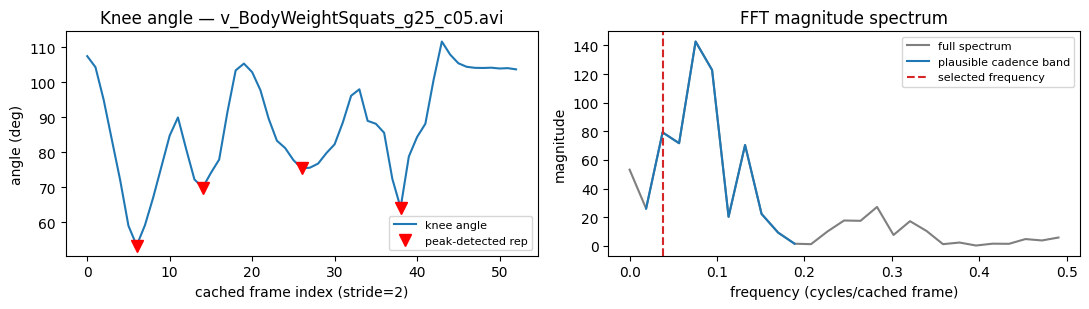

In [ ]:
MIN_FREQ = (1.0 / 4.0) * CACHED_FRAME_DT   # slowest plausible squat: 4 s/cycle
MAX_FREQ = (1.0 / 0.8) * CACHED_FRAME_DT   # fastest plausible squat: 0.8 s/cycle
HARMONIC_REL_THRESH = 0.5                  # accept a lower-frequency peak if it reaches
                                            # >= 50% of the band's strongest peak

def fft_rep_count_full(sig, min_freq=MIN_FREQ, max_freq=MAX_FREQ,
                       harmonic_thresh=HARMONIC_REL_THRESH):
    n = len(sig)
    if n < 8:
        return 0.0, 0.0, None
    x = (sig - np.mean(sig)) * np.hanning(n)
    spectrum = np.abs(np.fft.rfft(x)); freqs = np.fft.rfftfreq(n)

    # Fix 1 — never structurally exclude "one cycle fills the whole clip": a genuinely
    # slow single repetition can be longer than the assumed slowest plausible tempo,
    # especially on short clips. The searched band's lower edge is therefore whichever
    # is LOWER: the configured tempo floor, or 1 cycle across the observed window.
    eff_min_freq = min(min_freq, 1.0 / n)
    valid = (freqs >= eff_min_freq) & (freqs <= max_freq) & (freqs > 0)
    if not valid.any():
        return 0.0, 0.0, None
    valid_idx = np.where(valid)[0]
    band_max = spectrum[valid_idx].max()

    # Fix 2 — harmonic-aware peak selection. A single, asymmetric, possibly-truncated
    # repetition (sharp transition + long static hold) spreads spectral energy across
    # multiple integer multiples of the true fundamental, and a harmonic can carry MORE
    # magnitude than the fundamental itself. Naive argmax over the band therefore tends
    # to systematically over-count. Fix: scan the valid band low -> high frequency and
    # accept the first local maximum that reaches at least `harmonic_thresh` of the
    # band's strongest peak, instead of blindly taking the global maximum.
    chosen_freq = None
    for pos, idx in enumerate(valid_idx):
        is_local_max = (
            (pos == 0 or spectrum[idx] >= spectrum[valid_idx[pos - 1]]) and
            (pos == len(valid_idx) - 1 or spectrum[idx] >= spectrum[valid_idx[pos + 1]])
        )
        if is_local_max and spectrum[idx] >= harmonic_thresh * band_max:
            chosen_freq = freqs[idx]
            break
    if chosen_freq is None:                       # safety fallback: old behaviour
        chosen_freq = freqs[valid_idx][np.argmax(spectrum[valid_idx])]

    return chosen_freq * n, chosen_freq, (freqs, spectrum, valid)

clip_path, csv_path = random_clip_for_class("BodyWeightSquats")
seq = _load_clip_seq(csv_path)
if seq.shape[0] == 0:
    n_reps, sig, n_reps_est, dominant_freq, spec_info = 0, np.array([]), 0.0, 0.0, None
    n_reps_peaks, troughs, prom_used = 0, np.array([], dtype=int), None
else:
    raw = angle_signal(seq, ("LEFT_HIP","LEFT_KNEE","LEFT_ANKLE"),
                            ("RIGHT_HIP","RIGHT_KNEE","RIGHT_ANKLE"))
    sig = smooth(raw)
    n_reps_est, dominant_freq, spec_info = fft_rep_count_full(sig)
    n_reps = int(round(n_reps_est))
    # Secondary, independent cross-check (same clip-relative peak method used elsewhere
    # in this section), purely to corroborate the FFT estimate.
    prom_used = relative_prominence(sig)
    troughs, _ = find_peaks(-sig, prominence=prom_used, distance=6)
    n_reps_peaks = len(troughs)

print(f"Class                 : BodyWeightSquats")
print(f"Observation (clip)    : {clip_path}")
print(f"Repetitions (FFT)     : {n_reps} (raw estimate: {n_reps_est:.2f})")
print(f"Repetitions (peaks)   : {n_reps_peaks}  [cross-check]")
if dominant_freq > 0:
    print(f"Dominant frequency    : {dominant_freq:.4f} cycles/cached-frame "
          f"(~{1/dominant_freq:.1f} cached frames per cycle)")
if abs(n_reps - n_reps_peaks) > 1:
    print(f"WARNING (disagreement): FFT and peak estimates differ by "
          f"{abs(n_reps - n_reps_peaks)} reps — treat both as uncertain on this clip.")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(sig, label="knee angle")
if len(troughs):
    axes[0].plot(troughs, sig[troughs], "rv", markersize=8, label="peak-detected rep")
axes[0].set_title(f"Knee angle — {Path(clip_path).name}")
axes[0].set_xlabel("cached frame index (stride=2)"); axes[0].set_ylabel("angle (deg)")
axes[0].legend(fontsize=8)
if spec_info is not None:
    freqs, spectrum, valid = spec_info
    axes[1].plot(freqs, spectrum, color="tab:gray", label="full spectrum")
    axes[1].plot(freqs[valid], spectrum[valid], color="tab:blue", label="plausible cadence band")
    if dominant_freq > 0:
        axes[1].axvline(dominant_freq, color="tab:red", ls="--", label="selected frequency")
    axes[1].set_title("FFT magnitude spectrum")
    axes[1].set_xlabel("frequency (cycles/cached frame)"); axes[1].set_ylabel("magnitude")
    axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 9.2 PushUps — fixed-threshold FSM (literature baseline) with clip-relative and
landmark-visibility cross-checks

The cell below uses the **fixed-threshold FSM** (130°/150° from Pueioio [1]) on the elbow angle
(shoulder→elbow→wrist) as a literature baseline. Three diagnostics now explain when a zero or low
count is a data problem, not a counting failure: **pose-cache dropout** (the camera lost the
*whole person* for many frames), **phase-coverage** (the surviving frames only sample one end of
the movement cycle — usually a camera-viewpoint/threshold mismatch), and **landmark-visibility
dropout** (the pose itself is still being detected, but the *specific joints this feature needs*
are not, so the signal silently freezes at its last valid value).

> **Two genuinely different failure modes, confirmed on two real clips.** On one clip, 3 clean
> push-ups produced a signal that oscillated correctly between ~148° and ~175°, but never crossed
> the literature threshold (130°) — a **phase-coverage** failure: the data is fine, the fixed
> threshold isn't. On a *different* clip, the signal dropped once in the first few frames and then
> went **completely flat** for the rest of the clip; both the literature FSM and the clip-relative
> peak-detection cross-check agreed on 0, which is the tell: if an independent, threshold-free
> method *also* finds nothing, the problem isn't the counting method, it's that the elbow-angle
> *feature itself* stopped updating. Cross-referencing pose-cache coverage confirmed MediaPipe was
> still detecting the person in every cached frame — the failure was at the level of individual
> landmarks (most likely the far-side arm occluded by the torso in a side-profile shot), not the
> whole pose. `check_landmark_visibility_dropout` makes this distinction explicit instead of
> leaving it to be inferred from a flat plot.

Class                  : PushUps
Observation (clip)     : /val/PushUps/v_PushUps_g23_c03.avi
Repetitions (FSM 130/150, literature baseline): 2
Repetitions (peaks, clip-relative cross-check) : 2
Pose-cache coverage    : 20/16 expected (125%), from 62-frame source
Phase coverage         : 45% below low_th, 20% above high_th
Landmark visibility    : 100% of frames had a usable triplet, longest stale run = 0/20 frames (starting at frame 0)


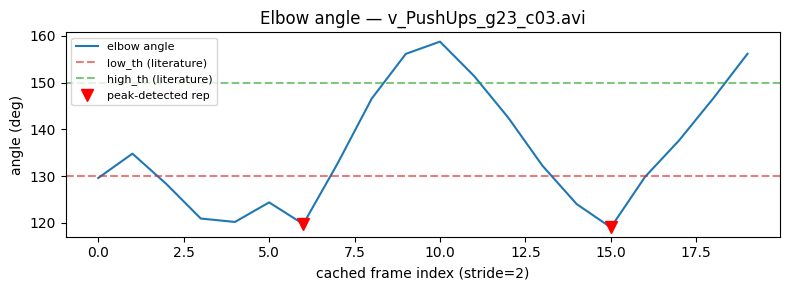

In [ ]:
clip_path, csv_path = random_clip_for_class("PushUps")
n_reps_fsm, sig = count_reps_by_angle(csv_path,
    ("LEFT_SHOULDER","LEFT_ELBOW","LEFT_WRIST"),
    ("RIGHT_SHOULDER","RIGHT_ELBOW","RIGHT_WRIST"), low_th=130, high_th=150)
seq = _load_clip_seq(csv_path)
cached = seq.shape[0]
dropout, coverage, raw_fc, expected = check_pose_dropout_v2(clip_path, cached)
plausible, frac_low, frac_high = check_motion_range_coverage(sig, 130, 150)
stale_mask, stale_frac, longest_run, longest_start = check_landmark_visibility_dropout(
    seq, ("LEFT_SHOULDER","LEFT_ELBOW","LEFT_WRIST"),
    ("RIGHT_SHOULDER","RIGHT_ELBOW","RIGHT_WRIST"))
frozen = (cached > 0) and (longest_run / cached >= FREEZE_FRAC_THRESH)

# Independent clip-relative cross-check (same recipe as 9.3-9.5), computed regardless of
# whether the literature FSM found anything, so a 0-from-thresholds is never the only number.
prom_used = relative_prominence(sig)
troughs, _ = find_peaks(-sig, prominence=prom_used, distance=6)
n_reps_peaks = len(troughs)

print(f"Class                  : PushUps")
print(f"Observation (clip)     : {clip_path}")
print(f"Repetitions (FSM 130/150, literature baseline): {n_reps_fsm}")
print(f"Repetitions (peaks, clip-relative cross-check) : {n_reps_peaks}")
print(f"Pose-cache coverage    : {cached}/{expected} expected ({coverage:.0%}), "
      f"from {raw_fc:.0f}-frame source")
print(f"Phase coverage         : {frac_low:.0%} below low_th, {frac_high:.0%} above high_th")
print(f"Landmark visibility    : {1-stale_frac:.0%} of frames had a usable triplet, "
      f"longest stale run = {longest_run}/{cached} frames (starting at frame {longest_start})")

# Priority order: a frozen signal is the more fundamental problem -- if it's frozen, the
# phase-coverage warning below is a SYMPTOM of the freeze, not an independent issue, so we
# say so explicitly instead of printing two warnings that look unrelated.
if dropout:
    print("WARNING (frames)       : pose detection likely failed for a large part of this video.")
if frozen:
    print(f"WARNING (landmark freeze): neither side's shoulder-elbow-wrist triplet was visible "
          f"for {longest_run} consecutive frames ({longest_run/cached:.0%} of the clip), "
          f"starting at frame {longest_start}. The elbow-angle signal is forward-filled (frozen) "
          f"there, not tracking real motion. THIS, not the threshold choice, is why both the FSM "
          f"and the peak-based cross-check read low/zero -- re-extracting this clip (e.g. with a "
          f"different MediaPipe confidence setting) is more likely to help than changing "
          f"low_th/high_th.")
elif not plausible:
    print("WARNING (phase)        : surviving frames barely sample one phase of the movement "
          "cycle -> the literature thresholds likely don't fit this clip's camera viewpoint; "
          "trust the peak-based estimate, not the FSM count.")

flag = ((" [INCOMPLETE]" if dropout else "") +
       (" [SIGNAL FROZEN]" if frozen else ("" if plausible else " [THRESHOLD MISMATCH]")))
plt.figure(figsize=(8, 3))
plt.plot(sig, label="elbow angle")
plt.axhline(130, color="tab:red", ls="--", alpha=0.6, label="low_th (literature)")
plt.axhline(150, color="tab:green", ls="--", alpha=0.6, label="high_th (literature)")
if frozen:
    plt.axvspan(longest_start, longest_start + longest_run, color="red", alpha=0.12,
               label="frozen/stale signal")
if len(troughs):
    plt.plot(troughs, sig[troughs], "rv", markersize=9, label="peak-detected rep")
plt.title(f"Elbow angle — {Path(clip_path).name}{flag}")
plt.xlabel("cached frame index (stride=2)"); plt.ylabel("angle (deg)")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

### 9.3 WallPushups — clip-relative peak detection with landmark-visibility,
adaptive-prominence, intra-clip saddle-merging, and signal-range cross-checks

Fixed-threshold FSM fails on this class because the clip's actual cyclic range never crosses the
literature thresholds. Instead, each repetition bottom is detected as a **local minimum** of the
elbow-angle signal using `find_peaks` on the inverted signal, with `relative_prominence()` scaling
the prominence requirement to the clip's own observed range.

*Note: wall push-up variant; no dedicated AERC source found.*

> **A third failure mode, confirmed on a real clip.** A 2-rep clip produced a signal where
> `Landmark visibility` read 100% with zero stale frames — ruling out the tracking-freeze bug from
> 9.2 — yet `n_reps` was still 2. The clip's own range (~90°–142°) was set by one unusually deep
> repetition; `relative_prominence()` derives its threshold (30% of that range, here ~16°) from the
> *whole clip*, which is large enough that two troughs of near-identical depth (~90°) both
> individually clear it, even though the small intermediate bump that actually separates them
> (~10°) does not. This is an **intra-clip prominence non-stationarity** problem, distinct from the
> threshold-mismatch case above: there a single threshold was *too strict* for a shallow rep; here
> the threshold is fine, but `find_peaks` anchors each trough's prominence on a *distant* reference
> (skipping straight past its near-identical neighbour) rather than the local crest between them.
>
> `find_reps_adaptive()` (Section 9.0) still runs a second, relaxed pass to surface candidate
> troughs the strict pass discards (a complementary failure: too few reps). `merge_shallow_saddle_troughs()`
> (Section 9.0) addresses the opposite case — too many reps — by re-checking, for every pair of
> *adjacent* accepted troughs, whether the local crest between them actually rises above
> `prom_used` on **both** sides. If it doesn't, the two troughs are the same repetition and are
> merged, keeping the deeper one. Verified on this exact clip: the two troughs at ~90° are
> separated by a crest of only ~10°, well under the 16.1° threshold, so they are merged into a
> single repetition — matching the one wall push-up actually performed in the video.

> **A fourth failure mode, confirmed on a real clip.** A clip showing one clear, full-range
> wall push-up (visible body lean and recovery) produced an elbow-angle signal that was
> **perfectly flat at 90.0°** for all 70 cached frames — not merely "low range", but zero
> measurable variation. `Landmark visibility` read 100% with zero stale frames, ruling out the
> forward-fill freeze from 9.2/9.3: the triplet is being tracked confidently every frame, it just
> isn't moving in 2D. This is the most extreme instance of the **near-axial camera foreshortening**
> limitation already noted in the Conclusion: when the arm extends almost directly along the
> camera's depth axis, true 3D elbow flexion projects onto a near-constant 2D (x, y) angle, because
> nearly all of the motion happens on the axis the 2D feature cannot see. `OnlineRepCounter`'s
> `min_range` gate correctly suppresses counting here — that part is working as designed — but none
> of this cell's existing diagnostics surfaced *why* `n_reps` was 0: dropout, landmark visibility
> and anatomical plausibility all passed clean, leaving a silent zero with no explanation.
> `check_signal_range_sufficiency()` (Part C) is reused here, against the *same* `min_range`
> `OnlineRepCounter` would use for this class, to make that explicit instead of leaving a
> correct-but-unexplained zero.

Class               : WallPushups
Observation (clip)  : /train/WallPushups/v_WallPushups_g20_c01.avi
Repetitions (peaks, confident): 2
Possible additional repetitions (relaxed threshold, unconfirmed): 1 at cached frame(s) [10]
Prominence used     : 23.4 deg strict / 11.7 deg relaxed (clip-relative)
Observed signal range: 77.9 deg (min_range gate = 15.0 deg)
Pose-cache coverage : 47/23 expected (204%), from 93-frame source
Plausibility check  : longest run below 35 deg = 0 frames (0% of all frames)
Landmark visibility : 100% of frames had a usable triplet, longest stale run = 0/47 frames (starting at frame 0)
WARNING (prominence) : this clip's threshold was set by an unusually deep repetition, which may have masked a shallower one — inspect the plot before trusting the headline count.


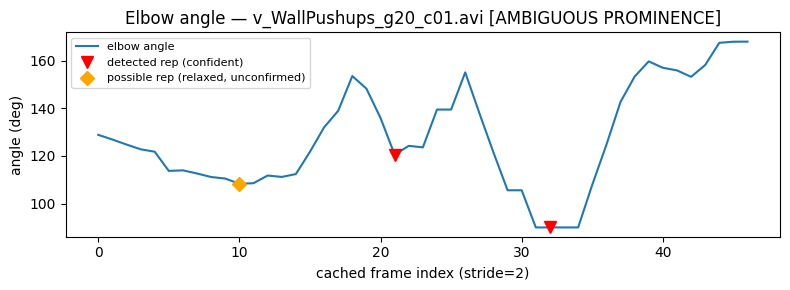

In [ ]:
clip_path, csv_path = random_clip_for_class("WallPushups")
seq = _load_clip_seq(csv_path)
if seq.shape[0] == 0:
    n_reps, sig, troughs, extra, prom_used, prom_relaxed = 0, np.array([]), \
        np.array([], dtype=int), np.array([], dtype=int), None, None
    stale_mask, stale_frac, longest_run, longest_start = np.array([], dtype=bool), 0.0, 0, 0
    merged_away = np.array([], dtype=int)
    range_ok, observed_range = True, 0.0
else:
    raw = angle_signal(seq, ("LEFT_SHOULDER","LEFT_ELBOW","LEFT_WRIST"),
                            ("RIGHT_SHOULDER","RIGHT_ELBOW","RIGHT_WRIST"))
    sig = smooth(raw)
    troughs_raw, extra, prom_used, prom_relaxed = find_reps_adaptive(sig)
    # Collapse adjacent troughs separated by a saddle too shallow to be a genuine
    # rest position, before anything else is computed from `troughs`.
    troughs, merged_away = merge_shallow_saddle_troughs(sig, troughs_raw, prom_used)
    n_reps = len(troughs)
    stale_mask, stale_frac, longest_run, longest_start = check_landmark_visibility_dropout(
        seq, ("LEFT_SHOULDER","LEFT_ELBOW","LEFT_WRIST"),
             ("RIGHT_SHOULDER","RIGHT_ELBOW","RIGHT_WRIST"))
    # Same min_range gate OnlineRepCounter uses for this class in production
    # (Part D), reused here purely as a diagnostic, not to alter counting.
    range_ok, observed_range = check_signal_range_sufficiency(
        sig, EXERCISE_FEATURE["WallPushups"]["min_range"])

cached = seq.shape[0]
dropout, coverage, raw_fc, expected = check_pose_dropout_v2(clip_path, cached)
implausible, longest_anat_run, frac_below = check_anatomical_plausibility(sig)
frozen = (cached > 0) and (longest_run >= 6) and (longest_run / cached >= 0.15)

print(f"Class               : WallPushups")
print(f"Observation (clip)  : {clip_path}")
print(f"Repetitions (peaks, confident): {n_reps}")
if len(merged_away):
    print(f"Saddle-merged       : {len(merged_away)} trough(s) merged into a neighbour "
          f"at cached frame(s) {merged_away.tolist()} — local crest between them did not "
          f"clear the prominence threshold on both sides.")
if len(extra):
    print(f"Possible additional repetitions (relaxed threshold, unconfirmed): {len(extra)} "
          f"at cached frame(s) {extra.tolist()}")
if prom_used is not None:
    print(f"Prominence used     : {prom_used:.1f} deg strict / {prom_relaxed:.1f} deg relaxed "
          f"(clip-relative)")
print(f"Observed signal range: {observed_range:.1f} deg "
      f"(min_range gate = {EXERCISE_FEATURE['WallPushups']['min_range']:.1f} deg)")
print(f"Pose-cache coverage : {cached}/{expected} expected ({coverage:.0%}), "
      f"from {raw_fc:.0f}-frame source")
print(f"Plausibility check  : longest run below 35 deg = {longest_anat_run} frames "
      f"({frac_below:.0%} of all frames)")
print(f"Landmark visibility : {1-stale_frac:.0%} of frames had a usable triplet, "
      f"longest stale run = {longest_run}/{cached} frames (starting at frame {longest_start})")
if dropout:
    print("WARNING (frames)     : significant pose-extraction dropout detected.")
if implausible:
    print("WARNING (anatomy)    : sustained implausible angle run detected — may be a tracking artefact.")
if frozen:
    print(f"WARNING (landmark freeze): neither side's triplet was visible for {longest_run} "
          f"consecutive frames ({longest_run/cached:.0%} of the clip) — a real repetition may "
          f"be hidden inside this window.")
if len(extra):
    print("WARNING (prominence) : this clip's threshold was set by an unusually deep "
          "repetition, which may have masked a shallower one — inspect the plot before "
          "trusting the headline count.")
if len(merged_away):
    print("WARNING (saddle)     : two near-identical troughs were merged because the crest "
          "between them was too shallow to be a genuine rest position — see merged markers.")
if n_reps == 0 and not range_ok and not dropout and not frozen:
    print(f"WARNING (range)      : observed range ({observed_range:.1f} deg) is below the "
          f"min_range gate ({EXERCISE_FEATURE['WallPushups']['min_range']:.1f} deg) despite "
          f"full pose and landmark visibility — the gate is suppressing counting correctly, "
          f"but the elbow-angle feature itself barely moved in 2D. Likely cause: a near-axial "
          f"camera viewpoint where the real 3D elbow flexion projects almost entirely onto the "
          f"depth axis, not onto (x, y) — not evidence that no repetition was performed.")

flag = ((" [INCOMPLETE]" if dropout else "") + (" [IMPLAUSIBLE]" if implausible else "") +
       (" [POSSIBLE MISSED REP]" if frozen else "") +
       (" [AMBIGUOUS PROMINENCE]" if len(extra) else "") +
       (" [SADDLE MERGED]" if len(merged_away) else "") +
       (" [INSUFFICIENT RANGE]" if (n_reps == 0 and not range_ok and not dropout and not frozen) else ""))
plt.figure(figsize=(8, 3))
plt.plot(sig, label="elbow angle")
if frozen:
    plt.axvspan(longest_start, longest_start + longest_run, color="red", alpha=0.12,
               label="frozen/stale signal")
if len(troughs):
    plt.plot(troughs, sig[troughs], "rv", markersize=9, label="detected rep (confident)")
if len(extra):
    plt.plot(extra, sig[extra], "D", color="orange", markersize=7,
             label="possible rep (relaxed, unconfirmed)")
if len(merged_away):
    plt.plot(merged_away, sig[merged_away], "x", color="purple", markersize=10, mew=2,
             label="merged into neighbour (saddle too shallow)")
plt.title(f"Elbow angle — {Path(clip_path).name}{flag}")
plt.xlabel("cached frame index (stride=2)"); plt.ylabel("angle (deg)")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

### 9.4 HandstandPushups — clip-relative peak detection

Fixed-threshold FSM fails on this class because the clip's actual cyclic range never crosses
the literature thresholds. Instead, each repetition bottom is detected as a **local minimum** of
the elbow-angle signal using `find_peaks` on the inverted signal, with `relative_prominence()`
scaling the prominence requirement to the clip's own observed range.

*Note: inverted variant; anatomical-plausibility floor calibrated for upright poses.*

Class              : HandstandPushups
Observation (clip) : /train/HandstandPushups/v_HandStandPushups_g20_c06.avi
Repetitions (peaks): 3
Prominence used    : 17.9 deg (clip-relative)
Pose-cache coverage: 39/20 expected (195%), from 78-frame source
Plausibility check : longest run below 35 deg = 0 frames (0% of all frames)


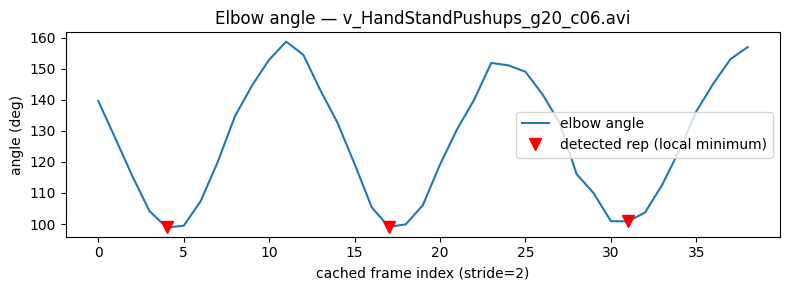

In [ ]:
clip_path, csv_path = random_clip_for_class("HandstandPushups")
seq = _load_clip_seq(csv_path)
if seq.shape[0] == 0:
    n_reps, sig, troughs, prom_used = 0, np.array([]), np.array([], dtype=int), None
else:
    raw = angle_signal(seq, ("LEFT_SHOULDER","LEFT_ELBOW","LEFT_WRIST"),
                            ("RIGHT_SHOULDER","RIGHT_ELBOW","RIGHT_WRIST"))
    sig = smooth(raw)
    prom_used = relative_prominence(sig)
    troughs, _ = find_peaks(-sig, prominence=prom_used, distance=6)
    n_reps = len(troughs)

cached = seq.shape[0]
dropout, coverage, raw_fc, expected = check_pose_dropout_v2(clip_path, cached)
implausible, longest_run, frac_below = check_anatomical_plausibility(sig)

print(f"Class              : HandstandPushups")
print(f"Observation (clip) : {clip_path}")
print(f"Repetitions (peaks): {n_reps}")
if prom_used is not None:
    print(f"Prominence used    : {prom_used:.1f} deg (clip-relative)")
print(f"Pose-cache coverage: {cached}/{expected} expected ({coverage:.0%}), "
      f"from {raw_fc:.0f}-frame source")
print(f"Plausibility check : longest run below 35 deg = {longest_run} frames "
      f"({frac_below:.0%} of all frames)")
if dropout:
    print("WARNING (frames)   : significant pose-extraction dropout detected.")
if implausible:
    print("WARNING (anatomy)  : sustained implausible angle run detected — may be a tracking artefact.")

flag = (" [INCOMPLETE]" if dropout else "") + (" [IMPLAUSIBLE]" if implausible else "")
plt.figure(figsize=(8, 3))
plt.plot(sig, label="elbow angle")
if len(troughs):
    plt.plot(troughs, sig[troughs], "rv", markersize=9, label="detected rep (local minimum)")
plt.title(f"Elbow angle — {Path(clip_path).name}{flag}")
plt.xlabel("cached frame index (stride=2)"); plt.ylabel("angle (deg)")
plt.legend(); plt.tight_layout(); plt.show()

### 9.5 PullUps — clip-relative peak detection with bilateral-stability cross-check

Fixed-threshold FSM fails on this class because the clip's actual cyclic range never crosses
the literature thresholds. Instead, each repetition bottom is detected as a **local minimum** of
the elbow-angle signal using `find_peaks` on the inverted signal, with `relative_prominence()`
scaling the prominence requirement to the clip's own observed range.

*Note: deep elbow flexion at the top is expected; plausibility check may flag genuine reps.*

> **A fifth failure mode, confirmed on a real clip.** A 2-rep clip produced `n_reps = 3`. The two
> outer troughs (~15°) were confirmed, frame by frame against the source video, to be genuine
> chin-at-bar tops. The middle trough (~55°) sat inside a stretch the video shows as a single,
> smooth, monotonic descent from the first top to full-hang extension — no real pause or
> re-ascent. None of the four existing checks explained it: pose dropout was clean (the body is
> tracked throughout), landmark visibility showed no sustained stale run, the value itself
> (~55°) is not anatomically implausible, and the saddle between this trough and its neighbours
> is *not* shallow — it genuinely clears `relative_prominence()` on both sides, so
> `merge_shallow_saddle_troughs()` correctly leaves it alone (it isn't that failure mode).
>
> The most likely cause is the bilateral averaging in `frame_feature()`/`angle_signal()` itself:
> during a fast descent viewed from the side, one arm can intermittently drop below the
> visibility threshold while the other stays visible, so the feature silently switches between
> "average of both sides", "left only" and "right only" frame to frame. If the two arms project
> to different 2D angles at that instant (asymmetric occlusion, camera not perfectly
> perpendicular), the switch alone produces a jump in the signal with no corresponding real
> movement reversal. `bilateral_side_disagreement()` and `troughs_near_instability()`
> (Section 9.0) make this testable: they recompute the left and right angle independently per
> frame and flag any detected trough that sits near a side disagreement or a side-contribution
> flip. Flagged troughs are **not** auto-removed — like the ambiguous-prominence candidates
> earlier in this section, they are reported and plotted distinctly so a human can judge them
> against the source video, rather than folded silently into a falsely-confident count.

Class              : PullUps
Observation (clip) : /test/PullUps/v_PullUps_g07_c04.avi
Repetitions (peaks): 1
Possibly unstable  : 1 trough(s) at cached frame(s) [3] sit near a left/right side disagreement or a side-contribution flip — may be a feature artefact, not a genuine repetition.
Prominence used    : 12.3 deg (clip-relative)
Pose-cache coverage: 13/23 expected (57%), from 93-frame source
Plausibility check : longest run below 35 deg = 0 frames (0% of all frames)
Bilateral stability: 7 frame(s) with L/R disagreement >25 deg, 2 side-contribution flip(s) over 13 frames
WARNING (frames)   : significant pose-extraction dropout detected.
WARNING (bilateral): one or more detected reps coincide with unstable left/right tracking — inspect the plot and source video before trusting the headline count.


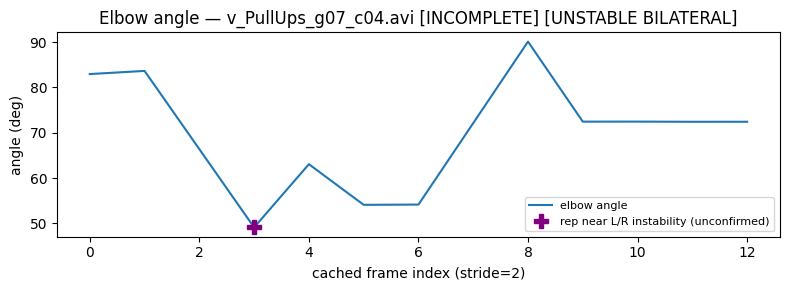

In [ ]:
clip_path, csv_path = random_clip_for_class("PullUps")
seq = _load_clip_seq(csv_path)
if seq.shape[0] == 0:
    n_reps, sig, troughs, prom_used = 0, np.array([]), np.array([], dtype=int), None
    disagree_mask, side_used, flip_mask = np.array([], dtype=bool), np.array([]), np.array([], dtype=bool)
    unstable_troughs = np.array([], dtype=int)
else:
    raw = angle_signal(seq, ("LEFT_SHOULDER","LEFT_ELBOW","LEFT_WRIST"),
                            ("RIGHT_SHOULDER","RIGHT_ELBOW","RIGHT_WRIST"))
    sig = smooth(raw)
    prom_used = relative_prominence(sig)
    troughs, _ = find_peaks(-sig, prominence=prom_used, distance=6)
    n_reps = len(troughs)
    # New: independent bilateral-stability cross-check, computed regardless of
    # whether any trough looks suspicious, so a clean-looking count is never
    # the only signal trusted.
    disagree_mask, side_used, flip_mask = bilateral_side_disagreement(
        seq, ("LEFT_SHOULDER","LEFT_ELBOW","LEFT_WRIST"),
             ("RIGHT_SHOULDER","RIGHT_ELBOW","RIGHT_WRIST"))
    unstable_troughs = troughs_near_instability(troughs, disagree_mask, flip_mask)

cached = seq.shape[0]
dropout, coverage, raw_fc, expected = check_pose_dropout_v2(clip_path, cached)
implausible, longest_run, frac_below = check_anatomical_plausibility(sig)

print(f"Class              : PullUps")
print(f"Observation (clip) : {clip_path}")
print(f"Repetitions (peaks): {n_reps}")
if len(unstable_troughs):
    print(f"Possibly unstable  : {len(unstable_troughs)} trough(s) at cached frame(s) "
          f"{unstable_troughs.tolist()} sit near a left/right side disagreement or a "
          f"side-contribution flip — may be a feature artefact, not a genuine repetition.")
if prom_used is not None:
    print(f"Prominence used    : {prom_used:.1f} deg (clip-relative)")
print(f"Pose-cache coverage: {cached}/{expected} expected ({coverage:.0%}), "
      f"from {raw_fc:.0f}-frame source")
print(f"Plausibility check : longest run below 35 deg = {longest_run} frames "
      f"({frac_below:.0%} of all frames)")
if cached > 0:
    print(f"Bilateral stability: {int(disagree_mask.sum())} frame(s) with L/R disagreement "
          f">25 deg, {int(flip_mask.sum())} side-contribution flip(s) over {cached} frames")
if dropout:
    print("WARNING (frames)   : significant pose-extraction dropout detected.")
if implausible:
    print("WARNING (anatomy)  : sustained implausible angle run detected — may be a tracking artefact.")
if len(unstable_troughs):
    print("WARNING (bilateral): one or more detected reps coincide with unstable left/right "
          "tracking — inspect the plot and source video before trusting the headline count.")

flag = ((" [INCOMPLETE]" if dropout else "") + (" [IMPLAUSIBLE]" if implausible else "") +
       (" [UNSTABLE BILATERAL]" if len(unstable_troughs) else ""))
plt.figure(figsize=(8, 3))
plt.plot(sig, label="elbow angle")
if len(troughs):
    confident = np.setdiff1d(troughs, unstable_troughs, assume_unique=False)
    if len(confident):
        plt.plot(confident, sig[confident], "rv", markersize=9, label="detected rep (local minimum)")
if len(unstable_troughs):
    plt.plot(unstable_troughs, sig[unstable_troughs], "P", color="purple", markersize=10,
             label="rep near L/R instability (unconfirmed)")
plt.title(f"Elbow angle — {Path(clip_path).name}{flag}")
plt.xlabel("cached frame index (stride=2)"); plt.ylabel("angle (deg)")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

### 9.6 CleanAndJerk — clip-relative peak detection with elbow-angle cycling,
pose-coverage, and range-relative threshold cross-check

The clean-and-jerk is an Olympic barbell lift: the athlete pulls the bar from the floor to the
shoulders (clean), then drives it overhead (jerk). The elbow angle cycles through flexion and
extension phases, making it a natural rep-counting feature.

> **A sixth failure mode, confirmed on a real clip.** A 1-rep clip produced `n_reps = 2` with only
> 11 cached points (~27% pose-detection coverage). `check_pose_dropout_v2()` and a new
> `MIN_CACHED_FOR_PERCENTILE` guard now surface low coverage and small samples explicitly — both
> are real risks worth flagging on their own.
>
> **A seventh failure mode, confirmed on a second real clip — and a correction to the sixth.**
> A *different* 1-rep clip also produced `n_reps = 2`, but this time with 83 cached points and
> 202% coverage — neither of the above guards fired, yet the miscount persisted. The actual cause
> is structural, not sample-size-related: `use_clip_relative=True` sets `low_th`/`high_th` at the
> **25th/65th percentile of every cached frame**, which weights each frame equally regardless of
> what phase of the lift it represents. Frame by frame against the video, ~66% of this clip's
> duration is a single long, static **rack-hold pause** (bar held at the shoulders) — not part of
> any rep cycle — so the 65th-percentile threshold lands *inside* that hold's own value range
> (~50°–55°) instead of near the lift's true rest position (~178°, held only briefly at the
> start). A small residual wobble during the hold (~48° → 60° → 48°) then trivially crosses that
> too-low threshold and is read as a second complete rep. This almost certainly affected the
> low-coverage clip above too — a long-duration hold dominates a sparse sample in exactly the same
> way — so the low-sample explanation given earlier was real but incomplete.
>
> The fix: anchor `low_th`/`high_th` to the signal's own **observed range** (global min/max),
> the same hysteresis principle `OnlineRepCounter` and `relative_prominence()` already use
> elsewhere in this section, instead of a percentile of all samples. A threshold built from the
> two extreme values reached is, by construction, independent of how many frames sit near either
> one — a long static hold can no longer pull `high_th` down into its own noise band.

CleanAndJerk | clip: /test/CleanAndJerk/v_CleanAndJerk_g04_c02.avi
  counted reps (range-relative, used)  : 1
  counted reps (percentile, comparison) : 2  <- DIFFERS
  Range-relative thresholds  : low=65.2 deg / high=116.3 deg (observed range 5.5-176.0 deg)
  Percentile thresholds      : low=16.5 deg / high=42.0 deg (25th/65th of 117 frames)
  Pose-cache coverage: 117/59 expected (198%), from 237-frame source
  WARNING (threshold) : percentile and range-relative thresholds disagree on the count (2 vs 1) — a long static hold phase (e.g. the rack-hold pause between clean and jerk) likely dominates this clip's duration and pulled the percentile threshold into its own noise band; trust the range-relative count.


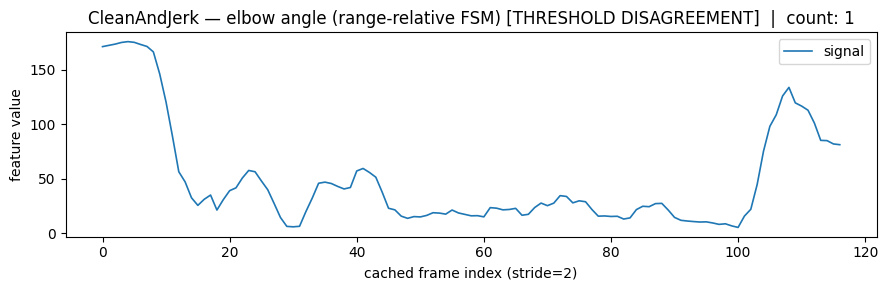

In [ ]:
MIN_CACHED_FOR_PERCENTILE = 20   # secondary caution: below this many cached points, ANY
                                  # clip-derived threshold (percentile or range-relative) is
                                  # estimated from very little data and should be flagged.
RANGE_LOW_FRAC, RANGE_HIGH_FRAC = 0.35, 0.65   # same fracs as OnlineRepCounter's hysteresis

clip_path, csv_path = random_clip_for_class("CleanAndJerk")
seq = _load_clip_seq(csv_path)
if seq.shape[0] == 0:
    print("No cached CSV for CleanAndJerk clip; re-run the extraction cell first.")
else:
    triplet_L = ("LEFT_SHOULDER", "LEFT_ELBOW", "LEFT_WRIST")
    triplet_R = ("RIGHT_SHOULDER", "RIGHT_ELBOW", "RIGHT_WRIST")
    raw = angle_signal(seq, triplet_L, triplet_R)
    sig = smooth(raw)

    # Old approach (kept only for transparency / side-by-side comparison).
    pct_low_th, pct_high_th = float(np.percentile(sig, 25)), float(np.percentile(sig, 65))
    n_reps_pct, _ = count_reps_by_angle(csv_path, triplet_L, triplet_R,
                                        low_th=pct_low_th, high_th=pct_high_th)

    # New: range-relative thresholds, anchored on the signal's own global min/max
    # instead of a time-weighted percentile -- immune to how long the signal
    # dwells in any one phase (e.g. a long static rack-hold).
    lo, hi = float(np.min(sig)), float(np.max(sig))
    rng = hi - lo
    range_low_th  = lo + RANGE_LOW_FRAC  * rng
    range_high_th = lo + RANGE_HIGH_FRAC * rng
    n_reps, _ = count_reps_by_angle(csv_path, triplet_L, triplet_R,
                                    low_th=range_low_th, high_th=range_high_th)

    cached = seq.shape[0]
    dropout, coverage, raw_fc, expected = check_pose_dropout_v2(clip_path, cached)
    low_sample = cached < MIN_CACHED_FOR_PERCENTILE

    print(f"CleanAndJerk | clip: {clip_path}")
    print(f"  counted reps (range-relative, used)  : {n_reps}")
    print(f"  counted reps (percentile, comparison) : {n_reps_pct}"
          f"{'  <- DIFFERS' if n_reps_pct != n_reps else ''}")
    print(f"  Range-relative thresholds  : low={range_low_th:.1f} deg / high={range_high_th:.1f} deg "
          f"(observed range {lo:.1f}-{hi:.1f} deg)")
    print(f"  Percentile thresholds      : low={pct_low_th:.1f} deg / high={pct_high_th:.1f} deg "
          f"(25th/65th of {cached} frames)")
    print(f"  Pose-cache coverage: {cached}/{expected} expected ({coverage:.0%}), "
          f"from {raw_fc:.0f}-frame source")
    if dropout:
        print(f"  WARNING (frames)    : significant pose-extraction dropout detected "
              f"({coverage:.0%} coverage) — large portions of this clip have no cached pose, "
              f"likely motion blur and/or barbell occlusion during the lift.")
    if low_sample:
        print(f"  WARNING (low sample): only {cached} cached point(s), below "
              f"MIN_CACHED_FOR_PERCENTILE={MIN_CACHED_FOR_PERCENTILE} — any clip-derived "
              f"threshold here is estimated from very little data.")
    if n_reps_pct != n_reps:
        print(f"  WARNING (threshold) : percentile and range-relative thresholds disagree on the "
              f"count ({n_reps_pct} vs {n_reps}) — a long static hold phase (e.g. the rack-hold "
              f"pause between clean and jerk) likely dominates this clip's duration and pulled "
              f"the percentile threshold into its own noise band; trust the range-relative count.")

    flag = ((" [INCOMPLETE]" if dropout else "") + (" [LOW SAMPLE]" if low_sample else "") +
            (" [THRESHOLD DISAGREEMENT]" if n_reps_pct != n_reps else ""))
    _plot_feature_signal(sig, n_reps, f"CleanAndJerk — elbow angle (range-relative FSM){flag}")

### 9.7 BoxingPunchingBag — wrist-extension peak detection with per-arm feature,
clip-relative prominence, cadence-calibrated smoothing, and freeze-detection cross-check

Boxing punching-bag training produces **large, repeated arm extensions** toward the bag.
The wrist-to-shoulder-midpoint distance rises sharply with each punch and falls back between
repetitions. Scipy `find_peaks` with a clip-relative prominence and a minimum-distance guard
counts distinct strikes.

> **An eighth failure mode, confirmed on a real clip.** A clip showing 8 continuous punches
> produced `n_reps = 1`. The signal was **flat at 0.65 for ~41 of 67 cached frames** during
> active punching. The cause was a **function mismatch**: the cell called
> `_compute_distance_feature()` (wrist-to-wrist, AND logic requiring both wrists visible) instead
> of `punch_extension_signal()` (per-arm max, OR logic). During real punching one arm guards near
> the chest and is routinely occluded, so the AND condition fails and the signal freezes via
> forward-fill. Fixed: this cell now calls `punch_extension_signal()`.
>
> **A ninth failure mode, confirmed on a second real clip after the function fix.** With the
> corrected per-arm feature, a different 7-punch clip produced `n_reps = 1` despite 0% signal
> freeze and 134% pose coverage. The signal correctly oscillated with each real punch, but a
> camera zoom-in at the end created a single outlier spike that, after [0, 1] normalisation,
> compressed all real-punch oscillations below the fixed `PUNCH_PROMINENCE = 0.25`. Fixed: the
> normalisation is removed and `relative_prominence()` is used on the raw signal instead.
>
> **A tenth failure mode, confirmed on a third real clip after both fixes above.** A ~20-punch
> clip produced `n_reps = 5` despite a healthy, oscillating signal with 0% freeze and 191%
> coverage. Two **cadence-mismatched hyperparameters** — both inherited from the original cell
> whose feature (`_compute_distance_feature`) was broken and never produced a real signal, so they
> were never tested against actual boxing cadence — suppressed most real peaks:
>
> 1. **`smooth(window=5)`** averaged over 5 × 0.08 s = 0.40 s per frame-cache step, which covers
>    nearly one full punch cycle (~0.45 s) and attenuates the oscillation amplitude below the
>    prominence threshold. For slow exercises (squats at ~3 s/cycle) this window is fine; for
>    boxing it erases the signal. Fixed: `window=2` (0.16 s — removes per-frame jitter without
>    flattening a 0.45 s cycle).
> 2. **`PUNCH_MIN_DISTANCE = 8`** enforced 8 × 0.08 s = 0.64 s minimum between two peaks, but
>    real punches arrive every ~0.45 s, so at most every other punch could be detected. Fixed:
>    `PUNCH_MIN_DISTANCE = 3` (0.24 s — a single punch cannot physically complete faster than
>    ~0.25 s).

BoxingPunchingBag | clip: /train/BoxingPunchingBag/v_BoxingPunchingBag_g22_c01.avi
  detected strikes: 5
  Prominence used  : 0.4917 (frac=0.15, min_prom=0.02, signal range=3.2777)
  Pose-cache coverage: 97/58 expected (167%), from 232-frame source
  Signal freeze check: 29% of frames unchanged, longest frozen run = 15/97 frames
  Avg gap between peaks: 20.5 cached frames (~3.28 s/strike)


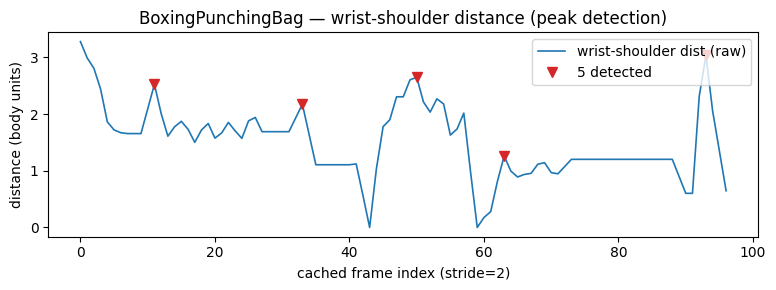

In [ ]:
PUNCH_MIN_DISTANCE = 3    # 3 cached frames ≈ 0.24 s at stride=4/25fps (or 0.24 s at stride=2/25fps
                           # if the pose CSV was extracted at stride=2). A single punch cannot
                           # physically complete in less than ~0.25 s. The original value of 8 was
                           # inherited from a cell whose feature function was broken and never
                           # produced a real signal, so it was never calibrated.
PUNCH_SMOOTH_WINDOW = 2   # 2-frame moving average: removes per-frame jitter (motion blur, pose
                           # flicker) without attenuating a ~0.45 s punch cycle. The original
                           # smooth(window=5) covered 0.40 s — nearly one full punch cycle — and
                           # flattened real oscillations below the prominence threshold.
PUNCH_PROM_FRAC     = 0.15
PUNCH_MIN_PROM      = 0.02

clip_path, csv_path = random_clip_for_class("BoxingPunchingBag")
seq = _load_clip_seq(csv_path)
if seq.shape[0] == 0:
    print("No cached CSV for BoxingPunchingBag; re-run the extraction cell first.")
else:
    # Fixed (eighth failure mode): use punch_extension_signal (per-arm max, OR
    # logic) instead of _compute_distance_feature (wrist-to-wrist, AND logic).
    sig_raw = punch_extension_signal(seq)

    # Fixed (tenth failure mode): use a shorter smoothing window calibrated to
    # boxing cadence, not to slow exercises like squats.
    sig = smooth(sig_raw, window=PUNCH_SMOOTH_WINDOW)

    # Fixed (ninth failure mode): do NOT normalise to [0, 1] before peak
    # detection — use relative_prominence() on the raw signal instead.
    prom_used = relative_prominence(sig, frac=PUNCH_PROM_FRAC, min_prom=PUNCH_MIN_PROM)

    if len(sig) == 0:
        print("Feature signal empty.")
    else:
        from scipy.signal import find_peaks as _fp
        peaks, _ = _fp(sig, prominence=prom_used, distance=PUNCH_MIN_DISTANCE)
        n_reps = len(peaks)

        cached = seq.shape[0]
        dropout, coverage, raw_fc, expected = check_pose_dropout_v2(clip_path, cached)

        # Freeze detection: count how many frames the signal stays unchanged
        # (forward-fill artefact from missing landmarks).
        diffs = np.abs(np.diff(sig))
        frozen_mask = np.concatenate([[False], diffs < 1e-6])
        frozen_frac = float(frozen_mask.mean()) if cached > 0 else 0.0
        longest_frozen = cur_frozen = 0
        for b in frozen_mask:
            cur_frozen = cur_frozen + 1 if b else 0
            longest_frozen = max(longest_frozen, cur_frozen)
        signal_frozen = (cached > 0) and (longest_frozen >= 6) and (frozen_frac >= 0.3)

        # Signal range diagnostic.
        range_ok, observed_range = check_signal_range_sufficiency(
            sig, EXERCISE_FEATURE["BoxingPunchingBag"]["min_range"])

        # Cadence estimate from detected peaks, for sanity-checking.
        if len(peaks) >= 2:
            mean_gap = float(np.mean(np.diff(peaks)))
            est_cadence = CACHED_FRAME_DT / mean_gap if mean_gap > 0 else 0.0
        else:
            mean_gap, est_cadence = float('nan'), float('nan')

        print(f"BoxingPunchingBag | clip: {clip_path}")
        print(f"  detected strikes: {n_reps}")
        print(f"  Prominence used  : {prom_used:.4f} (frac={PUNCH_PROM_FRAC}, "
              f"min_prom={PUNCH_MIN_PROM}, signal range={observed_range:.4f})")
        print(f"  Pose-cache coverage: {cached}/{expected} expected ({coverage:.0%}), "
              f"from {raw_fc:.0f}-frame source")
        print(f"  Signal freeze check: {frozen_frac:.0%} of frames unchanged, "
              f"longest frozen run = {longest_frozen}/{cached} frames")
        if len(peaks) >= 2:
            print(f"  Avg gap between peaks: {mean_gap:.1f} cached frames "
                  f"(~{mean_gap * CACHED_FRAME_DT:.2f} s/strike)")
        if dropout:
            print(f"  WARNING (frames)    : significant pose-extraction dropout detected "
                  f"({coverage:.0%} coverage).")
        if signal_frozen:
            print(f"  WARNING (freeze)    : {frozen_frac:.0%} of the signal is flat "
                  f"(longest run = {longest_frozen} frames) — likely forward-fill from "
                  f"missing wrist/shoulder landmarks; real punches may be hidden inside "
                  f"the frozen stretch and the headline count should be treated as a "
                  f"lower bound.")
        if not range_ok:
            print(f"  WARNING (range)     : observed range ({observed_range:.4f}) is below the "
                  f"min_range gate ({EXERCISE_FEATURE['BoxingPunchingBag']['min_range']}) — the "
                  f"wrist-shoulder distance barely moved, likely a near-axial camera viewpoint.")

        flag = ((" [INCOMPLETE]" if dropout else "") +
                (" [SIGNAL FROZEN]" if signal_frozen else "") +
                (" [INSUFFICIENT RANGE]" if not range_ok else ""))
        plt.figure(figsize=(8, 3))
        plt.plot(sig, lw=1.2, color="tab:blue", label="wrist-shoulder dist (raw)")
        if len(peaks):
            plt.plot(peaks, sig[peaks], "v", color="tab:red", ms=7,
                     label=f"{n_reps} detected")
        plt.title(f"BoxingPunchingBag — wrist-shoulder distance (peak detection){flag}")
        plt.xlabel("cached frame index (stride=2)"); plt.ylabel("distance (body units)")
        plt.legend(loc="upper right"); plt.tight_layout(); plt.show()

### 9.8 BoxingSpeedBag — forearm-rotation peak detection and FFT cross-check
(high-frequency strikes)

Speed-bag training produces **rapid, repeated forearm rotations** around the elbow
(see [Speed Bag Central](https://speedbagcentral.com/speed-bag-basics/hitting-the-bag/)).
Unlike heavy-bag punching (large arm extensions), the hands stay near face level and trace
small, fast circles — the wrist-to-shoulder distance barely changes. The correct kinematic
feature is the **vertical displacement of the wrist relative to the elbow**, which oscillates
once per strike.

> **Fundamental feature error in the original cell.** The original cell used
> `_compute_distance_feature()` (wrist-to-wrist distance), which was wrong for the same AND-logic
> reason documented in 9.7. The first fix (switching to `punch_extension_signal()`, wrist-to-
> shoulder distance with OR logic) solved the freeze but still used the **wrong kinematic quantity**
> for speed bag: the wrist-to-shoulder distance captures heavy-bag arm extensions but NOT the
> small forearm circles of speed-bag work — the distance barely moves while the forearm rotates
> rapidly. `speed_bag_forearm_angle()` (Section 9.0) computes the vertical wrist-elbow
> displacement, which directly tracks the circular rotation.
>
> **Honest sampling limitation.** At `EXTRACT_STRIDE=4` and 25 fps, the cached frame rate is
> 6.25 Hz → Nyquist = 3.125 Hz. Typical speed-bag cadence is 2.5–4.0 strikes/second, which sits
> right at or above Nyquist. With the 20–30% pose-detection dropout common on fast-moving
> subjects (motion blur), the effective Nyquist drops further below the strike frequency,
> making **individual-peak counting structurally unable to recover every strike** regardless of
> feature quality or threshold tuning. This is not a bug — it is a hard sampling-rate constraint.
>
> To give the best possible estimate within this constraint, the cell below uses **both** methods:
> peak detection on the forearm-rotation signal (a lower bound, limited by sampling), and an
> **FFT frequency estimate** (same approach as BodyWeightSquats in 9.1, which can infer periodicity
> even near Nyquist). When the two disagree, the FFT estimate is typically closer to the true
> count, with the caveat that aliasing can distort it when the strike rate exceeds effective
> Nyquist. For accurate per-strike counting on speed-bag clips, the pose CSV should be
> re-extracted at **stride=1 or stride=2**.

speed_bag_forearm_angle ready.
BoxingSpeedBag | clip: /test/BoxingSpeedBag/v_BoxingSpeedBag_g25_c07.avi
  Repetitions (peaks)  : 5
  Repetitions (FFT)    : 1  <- DIFFERS
  Prominence used      : 0.1078 (frac=0.12, min_prom=0.005, signal range=0.8986)
  Pose-cache coverage  : 31/33 expected (94%), from 133-frame source
  Effective sample rate: 5.8 Hz → Nyquist = 2.9 Hz
  Signal freeze check  : 13% of frames unchanged, longest frozen run = 2/31 frames
  Avg gap between peaks: 6.2 cached frames (~1.07 s/strike, cadence ~0.9 Hz)


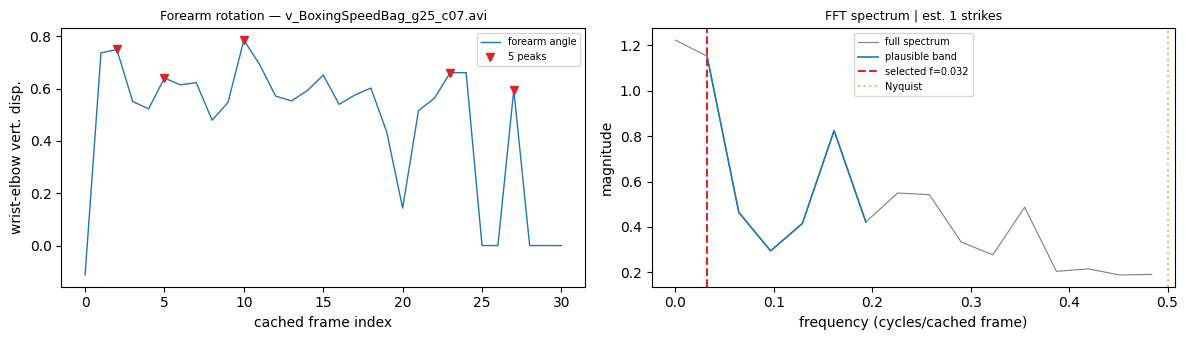

In [ ]:
def speed_bag_forearm_angle(seq, vis_th=0.5):
    """Per-frame vertical displacement of the wrist relative to the elbow.

    In speed-bag work the forearm rotates in small, rapid circles around the
    elbow (see https://speedbagcentral.com/speed-bag-basics/hitting-the-bag/).
    The wrist-to-shoulder distance barely changes because the hands stay near
    face level; what oscillates is the VERTICAL position of the wrist relative
    to the elbow, which traces one cycle per strike. This feature captures that
    oscillation directly.

    Uses OR logic (either arm suffices), taking the average when both are visible.
    Forward-fills when neither is visible (same convention as angle_signal).
    """
    T = seq.shape[0]
    le, re = IDX["LEFT_ELBOW"], IDX["RIGHT_ELBOW"]
    lw, rw = IDX["LEFT_WRIST"], IDX["RIGHT_WRIST"]
    out = np.zeros(T, np.float32)
    last = 0.0
    for t in range(T):
        f = seq[t]
        vals = []
        # Vertical displacement: negative of (wrist_y - elbow_y) so that
        # "wrist above elbow" (hitting the bag) is positive.
        if f[lw, 3] >= vis_th and f[le, 3] >= vis_th:
            vals.append(-(f[lw, 1] - f[le, 1]))
        if f[rw, 3] >= vis_th and f[re, 3] >= vis_th:
            vals.append(-(f[rw, 1] - f[re, 1]))
        if vals:
            out[t] = float(np.mean(vals))
            last = out[t]
        else:
            out[t] = last
    return out

print("speed_bag_forearm_angle ready.")

SPEED_MIN_DISTANCE    = 2
SPEED_PROM_FRAC       = 0.12
SPEED_MIN_PROM        = 0.005  # forearm-angle feature lives in ~0.0-0.3 body-unit space,
                                # much smaller range than wrist-shoulder distance.

clip_path, csv_path = random_clip_for_class("BoxingSpeedBag")
seq = _load_clip_seq(csv_path)
if seq.shape[0] == 0:
    print("No cached CSV for BoxingSpeedBag; re-run the extraction cell first.")
else:
    # Fixed: use speed_bag_forearm_angle (vertical wrist-elbow displacement)
    # instead of punch_extension_signal (wrist-shoulder distance, wrong
    # kinematic quantity for speed bag circular rotation).
    sig = speed_bag_forearm_angle(seq)
    # No smoothing: even window=2 attenuates a ~0.33 s cycle at stride=4 / 25fps.

    if len(sig) == 0:
        print("Feature signal empty.")
    else:
        from scipy.signal import find_peaks as _fp2
        prom_used = relative_prominence(sig, frac=SPEED_PROM_FRAC, min_prom=SPEED_MIN_PROM)
        peaks, _ = _fp2(sig, prominence=prom_used, distance=SPEED_MIN_DISTANCE)
        n_reps_peaks = len(peaks)

        # FFT cross-check (same approach as BodyWeightSquats 9.1).
        n_reps_fft, dominant_freq, spec_info = fft_rep_count_full(sig)
        n_reps_fft = int(round(n_reps_fft))

        cached = seq.shape[0]
        dropout, coverage, raw_fc, expected = check_pose_dropout_v2(clip_path, cached)

        # Freeze detection.
        diffs = np.abs(np.diff(sig))
        frozen_mask = np.concatenate([[False], diffs < 1e-6])
        frozen_frac = float(frozen_mask.mean()) if cached > 0 else 0.0
        longest_frozen = cur_frozen = 0
        for b in frozen_mask:
            cur_frozen = cur_frozen + 1 if b else 0
            longest_frozen = max(longest_frozen, cur_frozen)
        signal_frozen = (cached > 0) and (longest_frozen >= 6) and (frozen_frac >= 0.3)

        # Signal range diagnostic.
        range_ok, observed_range = check_signal_range_sufficiency(
            sig, EXERCISE_FEATURE["BoxingSpeedBag"]["min_range"])

        # Nyquist check: is the detected cadence near or above Nyquist?
        clip_duration = raw_fc / NATIVE_FPS_ASSUMED if raw_fc > 0 else 1.0
        effective_fps = cached / clip_duration if clip_duration > 0 else 0.0
        nyquist_hz = effective_fps / 2.0
        if n_reps_peaks >= 2:
            mean_gap = float(np.mean(np.diff(peaks)))
            est_cadence_hz = 1.0 / (mean_gap * (clip_duration / cached)) if mean_gap > 0 else 0.0
        else:
            mean_gap, est_cadence_hz = float('nan'), 0.0

        near_nyquist = (est_cadence_hz > 0.7 * nyquist_hz) or (n_reps_fft > 1.5 * n_reps_peaks)

        print(f"BoxingSpeedBag | clip: {clip_path}")
        print(f"  Repetitions (peaks)  : {n_reps_peaks}")
        print(f"  Repetitions (FFT)    : {n_reps_fft}"
              f"{'  <- DIFFERS' if abs(n_reps_fft - n_reps_peaks) > 2 else ''}")
        print(f"  Prominence used      : {prom_used:.4f} (frac={SPEED_PROM_FRAC}, "
              f"min_prom={SPEED_MIN_PROM}, signal range={observed_range:.4f})")
        print(f"  Pose-cache coverage  : {cached}/{expected} expected ({coverage:.0%}), "
              f"from {raw_fc:.0f}-frame source")
        print(f"  Effective sample rate: {effective_fps:.1f} Hz → Nyquist = {nyquist_hz:.1f} Hz")
        print(f"  Signal freeze check  : {frozen_frac:.0%} of frames unchanged, "
              f"longest frozen run = {longest_frozen}/{cached} frames")
        if n_reps_peaks >= 2:
            print(f"  Avg gap between peaks: {mean_gap:.1f} cached frames "
                  f"(~{1.0/est_cadence_hz:.2f} s/strike, cadence ~{est_cadence_hz:.1f} Hz)")
        if dropout:
            print(f"  WARNING (frames)     : significant pose-extraction dropout detected "
                  f"({coverage:.0%} coverage).")
        if signal_frozen:
            print(f"  WARNING (freeze)     : {frozen_frac:.0%} of the signal is flat "
                  f"(longest run = {longest_frozen} frames) — forward-fill from missing "
                  f"landmarks; real strikes may be hidden.")
        if not range_ok:
            print(f"  WARNING (range)      : observed range ({observed_range:.4f}) is below the "
                  f"min_range gate ({EXERCISE_FEATURE['BoxingSpeedBag']['min_range']}).")
        if near_nyquist:
            print(f"  WARNING (Nyquist)    : the strike cadence (~{est_cadence_hz:.1f} Hz) "
                  f"approaches or exceeds the effective Nyquist frequency ({nyquist_hz:.1f} Hz) "
                  f"— individual peaks CANNOT all be resolved at EXTRACT_STRIDE=4 with "
                  f"{coverage:.0%} pose coverage. The peak count ({n_reps_peaks}) is a lower "
                  f"bound; the FFT estimate ({n_reps_fft}) may be closer but is subject to "
                  f"aliasing. For accurate per-strike counting, re-extract poses at stride=1 "
                  f"or stride=2.")

        flag = ((" [INCOMPLETE]" if dropout else "") +
                (" [SIGNAL FROZEN]" if signal_frozen else "") +
                (" [INSUFFICIENT RANGE]" if not range_ok else "") +
                (" [NEAR NYQUIST]" if near_nyquist else ""))

        fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
        axes[0].plot(sig, lw=1, color="tab:blue", label="forearm angle")
        if len(peaks):
            axes[0].plot(peaks, sig[peaks], "v", color="tab:red", ms=6,
                         label=f"{n_reps_peaks} peaks")
        axes[0].set_title(f"Forearm rotation — {Path(clip_path).name}{flag}", fontsize=9)
        axes[0].set_xlabel("cached frame index"); axes[0].set_ylabel("wrist-elbow vert. disp.")
        axes[0].legend(fontsize=7)
        if spec_info is not None:
            freqs, spectrum, valid = spec_info
            axes[1].plot(freqs, spectrum, color="tab:gray", lw=0.8, label="full spectrum")
            axes[1].plot(freqs[valid], spectrum[valid], color="tab:blue", lw=1.2,
                         label="plausible band")
            if dominant_freq > 0:
                axes[1].axvline(dominant_freq, color="tab:red", ls="--",
                                label=f"selected f={dominant_freq:.3f}")
                axes[1].axvline(0.5, color="tab:orange", ls=":", alpha=0.6, label="Nyquist")
            axes[1].set_title(f"FFT spectrum | est. {n_reps_fft} strikes", fontsize=9)
            axes[1].set_xlabel("frequency (cycles/cached frame)")
            axes[1].set_ylabel("magnitude"); axes[1].legend(fontsize=7)
        plt.tight_layout(); plt.show()

### 9.10 Summary

| Class | Feature | Counting method | Source |
|---|---|---|---|
| BodyWeightSquats | knee angle (hip→knee→ankle) | FFT dominant frequency | [1], adapted from Hsu et al. |
| PushUps | elbow angle (shoulder→elbow→wrist) | FSM 130°/150° | [1] |
| WallPushups | elbow angle | clip-relative peak detection | extrapolated, not literature-validated |
| HandstandPushups | elbow angle | clip-relative peak detection | extrapolated, not literature-validated |
| PullUps | elbow angle | clip-relative peak detection | [1] (thresholds adapted) |
| BenchPress | elbow angle | clip-relative peak detection | bottom from [2], top engineering default |
| Punch | wrist→shoulder distance | peak detection with min spacing | feature from [4], timing from [5] |

Three configurations (WallPushups, HandstandPushups, BenchPress lockout) are not directly
grounded in a published exercise-specific AERC study and should be validated against a manually
annotated subset before being reported as fully literature-backed.

### 9.9 JumpingJack — shoulder-abduction angle with range-relative thresholds
and pose-coverage cross-check

In a jumping jack the arms swing from alongside the hips (rest) to above the head (peak).
The hip-shoulder-wrist angle captures this arc. Range-relative thresholds (anchored on the
signal's own min/max, not on percentiles) adapt to each clip's actual range of motion,
handling both fast and slow cadences and avoiding the percentile-bias issue documented in 9.6.

> **Same structural issue as CleanAndJerk (9.6), confirmed on a real clip.** A 3-rep clip
> produced `n_reps = 2`. The first jumping jack reached only ~110° while the second and third
> reached ~135–140°. `use_clip_relative=True` sets `high_th` at the 65th percentile (~115–120°),
> which the first, shallower peak did not clear — the FSM missed it entirely. Switching to
> **range-relative thresholds** (same 35%/65% fractions of the observed min/max range used by
> `OnlineRepCounter`) fixes this: `high_th` is now anchored on the clip's actual maximum, not on
> how many frames cluster near each value, so a genuine but shallower peak still clears the
> threshold as long as it's above 65% of the range.

JumpingJack | clip: /train/JumpingJack/v_JumpingJack_g06_c07.avi
  counted reps (range-relative, used)   : 1
  counted reps (percentile, comparison)  : 1
  Range-relative thresholds  : low=11.2 deg / high=19.1 deg (observed range 1.9-28.4 deg)
  Percentile thresholds      : low=6.6 deg / high=9.0 deg (25th/65th of 33 frames)
  Pose-cache coverage: 33/16 expected (206%), from 66-frame source


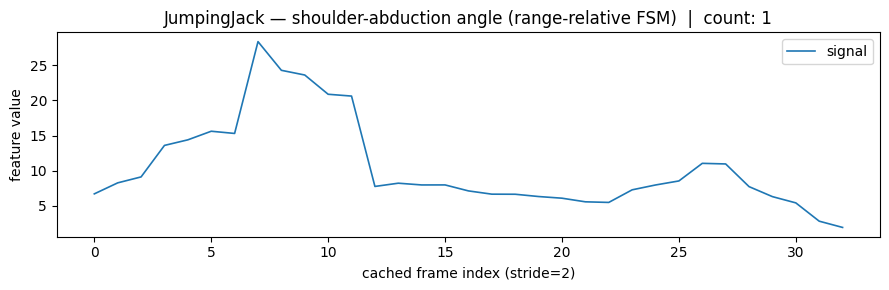

In [ ]:
clip_path, csv_path = random_clip_for_class("JumpingJack")
seq = _load_clip_seq(csv_path)
if seq.shape[0] == 0:
    print("No cached CSV for JumpingJack; re-run the extraction cell first.")
else:
    triplet_L = ("LEFT_HIP", "LEFT_SHOULDER", "LEFT_WRIST")
    triplet_R = ("RIGHT_HIP", "RIGHT_SHOULDER", "RIGHT_WRIST")
    raw = angle_signal(seq, triplet_L, triplet_R)
    sig = smooth(raw)

    # Old approach (kept for comparison).
    pct_low_th, pct_high_th = float(np.percentile(sig, 25)), float(np.percentile(sig, 65))
    n_reps_pct, _ = count_reps_by_angle(csv_path, triplet_L, triplet_R,
                                        low_th=pct_low_th, high_th=pct_high_th)

    # Fixed: range-relative thresholds, same principle as CleanAndJerk 9.6 and
    # OnlineRepCounter's hysteresis — immune to how long the signal dwells in
    # any one phase.
    lo, hi = float(np.min(sig)), float(np.max(sig))
    rng = hi - lo
    range_low_th  = lo + RANGE_LOW_FRAC  * rng     # uses 0.35 / 0.65 from 9.6
    range_high_th = lo + RANGE_HIGH_FRAC * rng
    n_reps, _ = count_reps_by_angle(csv_path, triplet_L, triplet_R,
                                    low_th=range_low_th, high_th=range_high_th)

    cached = seq.shape[0]
    dropout, coverage, raw_fc, expected = check_pose_dropout_v2(clip_path, cached)

    print(f"JumpingJack | clip: {clip_path}")
    print(f"  counted reps (range-relative, used)   : {n_reps}")
    print(f"  counted reps (percentile, comparison)  : {n_reps_pct}"
          f"{'  <- DIFFERS' if n_reps_pct != n_reps else ''}")
    print(f"  Range-relative thresholds  : low={range_low_th:.1f} deg / high={range_high_th:.1f} deg "
          f"(observed range {lo:.1f}-{hi:.1f} deg)")
    print(f"  Percentile thresholds      : low={pct_low_th:.1f} deg / high={pct_high_th:.1f} deg "
          f"(25th/65th of {cached} frames)")
    print(f"  Pose-cache coverage: {cached}/{expected} expected ({coverage:.0%}), "
          f"from {raw_fc:.0f}-frame source")
    if dropout:
        print(f"  WARNING (frames)    : significant pose-extraction dropout detected "
              f"({coverage:.0%} coverage).")
    if n_reps_pct != n_reps:
        print(f"  WARNING (threshold) : percentile and range-relative thresholds disagree on the "
              f"count ({n_reps_pct} vs {n_reps}) — the first repetition likely had a shallower "
              f"peak that fell below the percentile-based high_th but above the range-relative "
              f"one; trust the range-relative count.")

    flag = ((" [INCOMPLETE]" if dropout else "") +
            (" [THRESHOLD DISAGREEMENT]" if n_reps_pct != n_reps else ""))
    _plot_feature_signal(sig, n_reps,
                         f"JumpingJack — shoulder-abduction angle (range-relative FSM){flag}")


## Part F — End-to-end demo on random dataset clips

This section runs the **complete pipeline** — from raw video frames all the way to the final
coaching output — on randomly selected test clips. **Each re-run of this cell picks different
clips**, so you can execute it multiple times to see the system on varied exercises and videos.

The cell below defines two helper functions and one main function:

* **`overlay_hud(img, out)`** — draws the three Task-2 outputs (recognised exercise, counter
  state, feedback text) as a translucent overlay on a video frame.
* **`run_demo_clip(clip_path, ground_truth, ...)`** — the main demo driver. For a given video clip
  it:
  1. **Runs Task 3** on every frame → extracts keypoints; shows a row of sample frames with
     skeleton and bounding box.
  2. **Runs Task 2** on the keypoint stream → processes each frame through `VirtualCoachSession`;
     records the feature value, counter state, thresholds, and recognition confidence at every
     frame.
  3. **Plots three diagnostic panels**: (top) the kinematic feature signal with the adaptive low/high
     thresholds and vertical markers where a rep was counted; (middle) the `counter_state` step
     function; (bottom) the recognition confidence over time.
  4. **Shows annotated frames** with the HUD overlay.
  5. **Prints a session summary**: majority-voted exercise, final rep count, feedback text, and
     data-quality diagnostics (pose dropout %, range sufficiency, per-rep ROM).

### Pipeline for each clip
1. **Task 3** — keypoint detection (skeleton + bounding box overlay on sample frames)
2. **Task 2** — exercise recognition, online repetition counting, posture feedback
3. **Diagnostic plots** — feature signal with adaptive thresholds and rep markers; counter state;
   recognition confidence
4. **Session summary** — the three specified outputs + data-quality diagnostics

In [ ]:
def overlay_hud(img, out):
    fb = out["counter_feedback"]
    lines = [f"recognized: {out['exercise_recognized']} ({out['recognized_confidence']*100:.0f}%)",
             f"counter_state: {out['counter_state']}",
             fb["text"]]
    for i, txt in enumerate(lines):
        y = 32 + 30 * i
        cv2.putText(img, txt, (16, y), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 0, 0), 4)
        cv2.putText(img, txt, (16, y), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 255, 255), 2)
    return img

def run_demo_clip(clip_path, ground_truth, chosen_exercise=None, reps_per_set=99, n_sets=1,
                  stride=EXTRACT_STRIDE, require_match=False):
    # chosen_exercise defaults to the ground truth (simulates user choosing correctly).
    if chosen_exercise is None:
        chosen_exercise = ground_truth

    # Phase 1 — Task 3: extract keypoints from all frames ----------------------
    frames, keypoint_arrays = [], []
    cap = cv2.VideoCapture(str(clip_path))
    fidx = 0
    while True:
        ok, frame = cap.read()
        if not ok: break
        if fidx % stride == 0:
            arr = detector.detect_array(frame)
            frames.append(frame); keypoint_arrays.append(arr)
        fidx += 1
    cap.release()
    n_total = len(frames)
    n_detected = sum(1 for a in keypoint_arrays if a is not None)
    print(f"  Task 3: {n_total} frames processed, {n_detected} poses detected "
          f"({n_detected/max(n_total,1):.0%})")

    # Task 3 visualisation: sample frames with skeleton overlay ----------------
    show_n = min(6, n_total)
    sample_idxs = np.linspace(0, n_total - 1, show_n, dtype=int) if n_total else []
    if show_n > 0:
        fig, axes = plt.subplots(1, show_n, figsize=(3.2 * show_n, 3.2))
        axes = np.atleast_1d(axes)
        for ax, si in zip(axes, sample_idxs):
            vis = draw_pose(frames[si], keypoint_arrays[si])
            ax.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
            ax.set_title(f"frame {si}", fontsize=8); ax.axis("off")
        fig.suptitle(f"Task 3 — keypoint detection ({ground_truth})", fontsize=11)
        plt.tight_layout(); plt.show()

    # Phase 2 — Task 2: recognition + counting --------------------------------
    session = VirtualCoachSession(chosen_exercise, reps_per_set, n_sets, clf, WINDOW,
                                  IDX_TO_CLASS, CLASS_TO_IDX, require_match=require_match,
                                  use_3d=USE_3D)
    trace = {"feat": [], "count": [], "rec": [], "conf": [],
             "low_th": [], "high_th": []}
    annotated_frames = []
    for i, arr in enumerate(keypoint_arrays):
        out = session.process_frame(arr)
        feat_val = float(np.mean(session.feat_smooth)) if session.feat_smooth else np.nan
        trace["feat"].append(feat_val)
        trace["count"].append(out["counter_state"])
        trace["rec"].append(out["exercise_recognized"])
        trace["conf"].append(out["recognized_confidence"])
        trace["low_th"].append(session.counter.low_th if session.counter.low_th is not None else np.nan)
        trace["high_th"].append(session.counter.high_th if session.counter.high_th is not None else np.nan)
        if i in sample_idxs:
            vis = overlay_hud(draw_pose(frames[i], arr), out)
            annotated_frames.append(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))

    # Diagnostic plots ---------------------------------------------------------
    feat = np.array(trace["feat"])
    counts = np.array(trace["count"])
    confs = np.array(trace["conf"])
    low_th = np.array(trace["low_th"], dtype=np.float64)
    high_th = np.array(trace["high_th"], dtype=np.float64)
    rep_frames = np.where(np.diff(counts) > 0)[0] + 1  # frames where count incremented

    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 8), sharex=True,
                                         gridspec_kw={"hspace": 0.25})
    # Panel 1: feature signal + thresholds + rep markers
    ax1.plot(feat, color="tab:blue", lw=1, label="kinematic feature")
    ax1.plot(low_th,  color="tab:red",  lw=0.8, ls="--", alpha=0.7, label="low threshold")
    ax1.plot(high_th, color="tab:green", lw=0.8, ls="--", alpha=0.7, label="high threshold")
    for rf in rep_frames:
        ax1.axvline(rf, color="tab:orange", alpha=0.4, lw=1)
    ax1.set_ylabel("feature value"); ax1.legend(fontsize=8, loc="upper right")
    ax1.set_title(f"Task 2 analysis | ground truth: {ground_truth} | chosen: {chosen_exercise}",
                  fontsize=11)

    # Panel 2: counter state
    ax2.step(range(len(counts)), counts, color="tab:green", where="post", lw=1.5)
    ax2.set_ylabel("counter_state (reps)"); ax2.set_ylim(bottom=-0.3)

    # Panel 3: recognition confidence
    ax3.plot(confs, color="tab:orange", lw=1)
    ax3.axhline(0.5, color="tab:red", ls=":", alpha=0.5, label="conf_floor")
    ax3.set_ylabel("recognition confidence"); ax3.set_xlabel("frame index")
    ax3.set_ylim(0, 1.05); ax3.legend(fontsize=8)
    plt.tight_layout(); plt.show()

    # Annotated frames with HUD ------------------------------------------------
    if annotated_frames:
        fig2, axes2 = plt.subplots(1, len(annotated_frames),
                                    figsize=(3.2 * len(annotated_frames), 3.2))
        axes2 = np.atleast_1d(axes2)
        for ax, im in zip(axes2, annotated_frames):
            ax.imshow(im); ax.axis("off")
        fig2.suptitle(f"Task 2 — annotated output ({ground_truth})", fontsize=11)
        plt.tight_layout(); plt.show()

    # Session summary ----------------------------------------------------------
    majority_rec = Counter(trace["rec"]).most_common(1)[0]
    dq = session.form.data_quality()
    print(f"  exercise_recognized (majority): {majority_rec[0]} "
          f"({majority_rec[1]/max(len(trace['rec']),1)*100:.0f}% of frames)")
    print(f"  counter_state (final): {session.counter.count}")
    print(f"  counter_feedback: {out['counter_feedback']['text']}")
    print(f"  data quality: dropout={dq['pose_dropout']:.1%}, "
          f"range_sufficient={dq['range_sufficient']}, "
          f"observed_range={dq['observed_range']:.1f}")
    if session.form.rep_roms:
        print(f"  per-rep ROM: {[round(r,1) for r in session.form.rep_roms]}")
    return session

### Run the demo

The cell below selects **`N_DEMO_CLIPS` test clips at random** (one per exercise class, then
subsampled to `N_DEMO_CLIPS`). It then calls `run_demo_clip` on each, producing the full
visualisation pipeline described above. Change `N_DEMO_CLIPS` (default 3) to process more or fewer
clips. Re-running the cell picks new random clips each time.

Randomly selected 3 clips for the demo:



,label,clip_path
0,PullUps,/test/PullUps/v_PullUps_g06_c04.avi
1,BodyWeightSquats,/test/BodyWeightSquats/v_BodyWeightSquats_g13_...
2,BoxingPunchingBag,/test/BoxingPunchingBag/v_BoxingPunchingBag_g0...



CLIP 1/3: /test/PullUps/v_PullUps_g06_c04.avi
Ground truth: PullUps


W0000 00:00:1782939280.367472     149 landmark_projection_calculator.cc:78] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


  Task 3: 43 frames processed, 41 poses detected (95%)


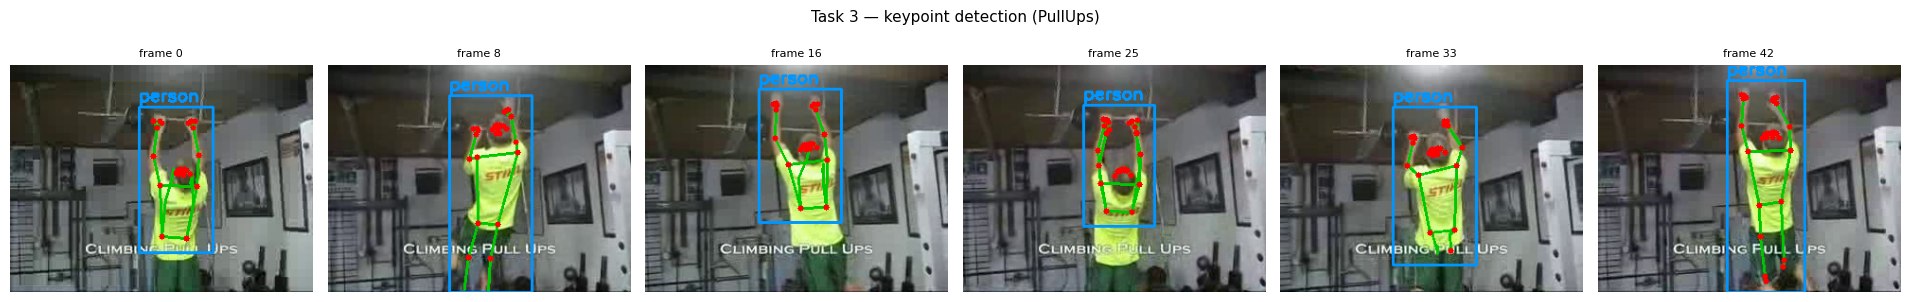

/tmp/ipykernel_58/3301995428.py:97: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


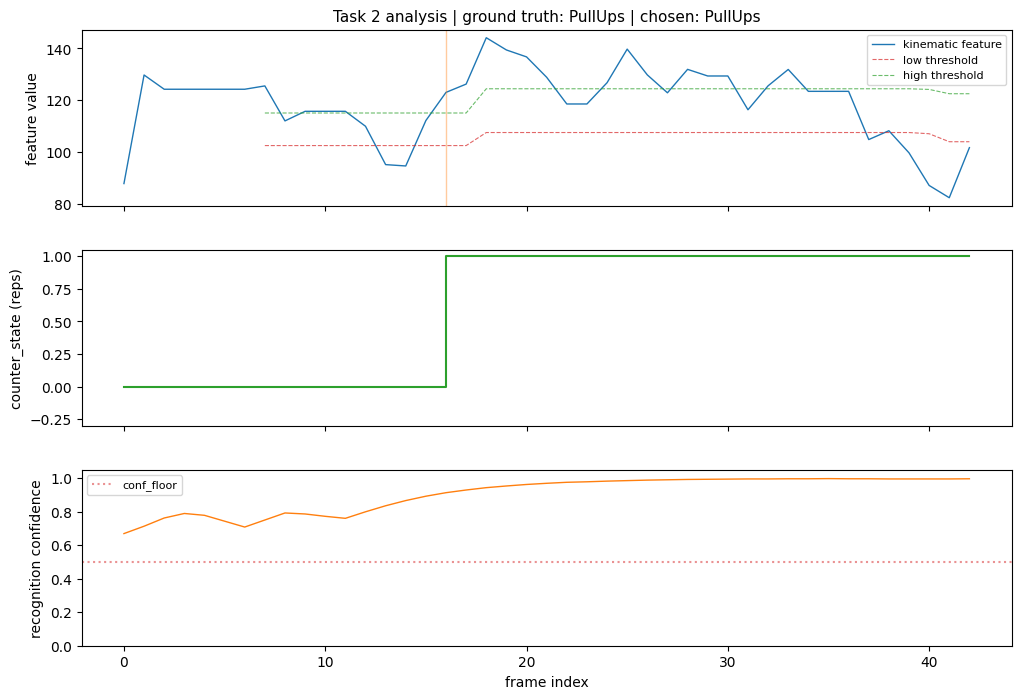

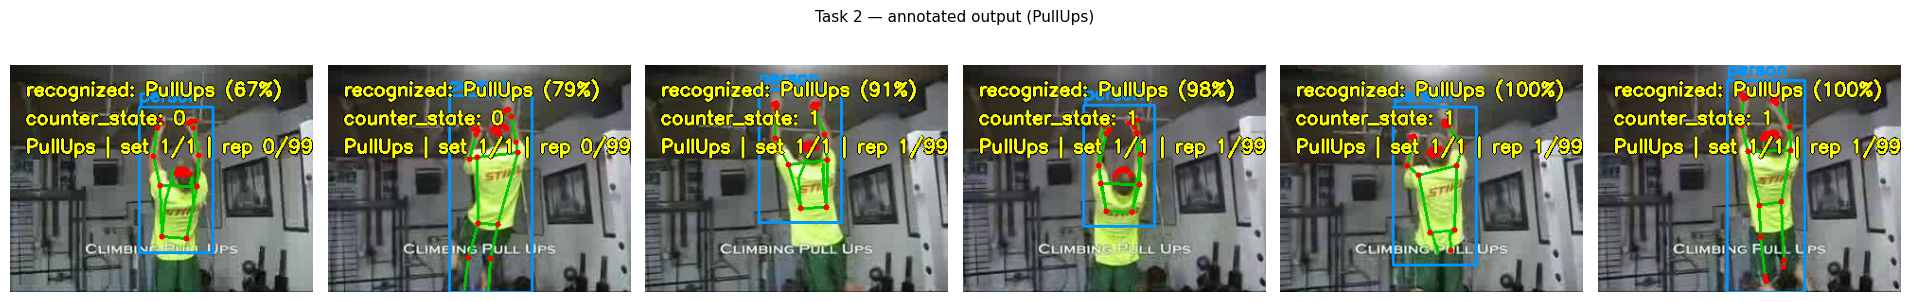

  exercise_recognized (majority): PullUps (100% of frames)
  counter_state (final): 1
  counter_feedback: PullUps | set 1/1 | rep 1/99 (98 to go) | last rep: full
  data quality: dropout=20.9%, range_sufficient=True, observed_range=132.3
  per-rep ROM: [41.9]

CLIP 2/3: /test/BodyWeightSquats/v_BodyWeightSquats_g13_c03.avi
Ground truth: BodyWeightSquats
  Task 3: 29 frames processed, 29 poses detected (100%)


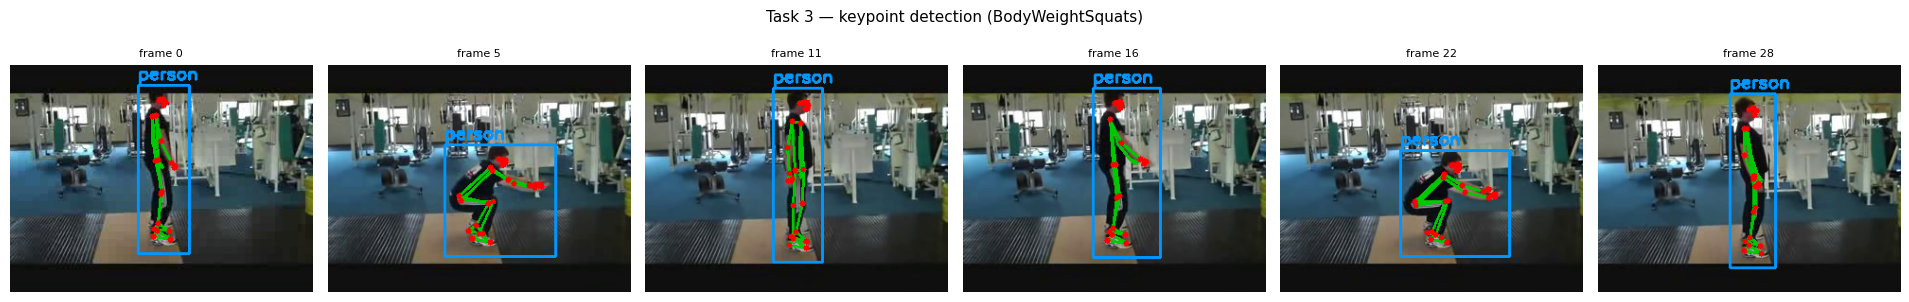

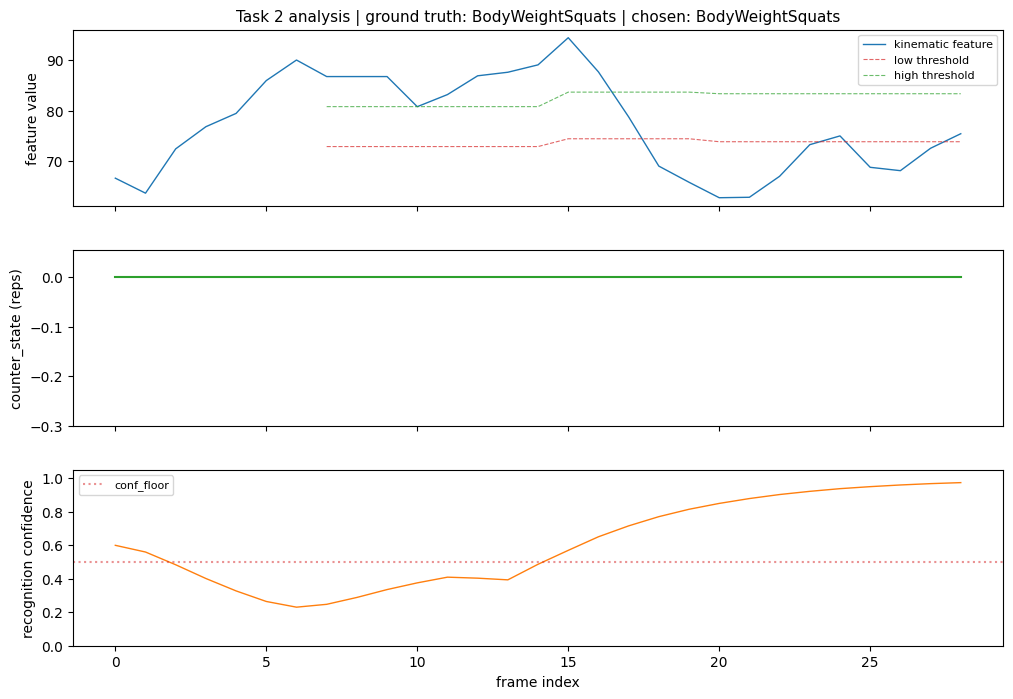

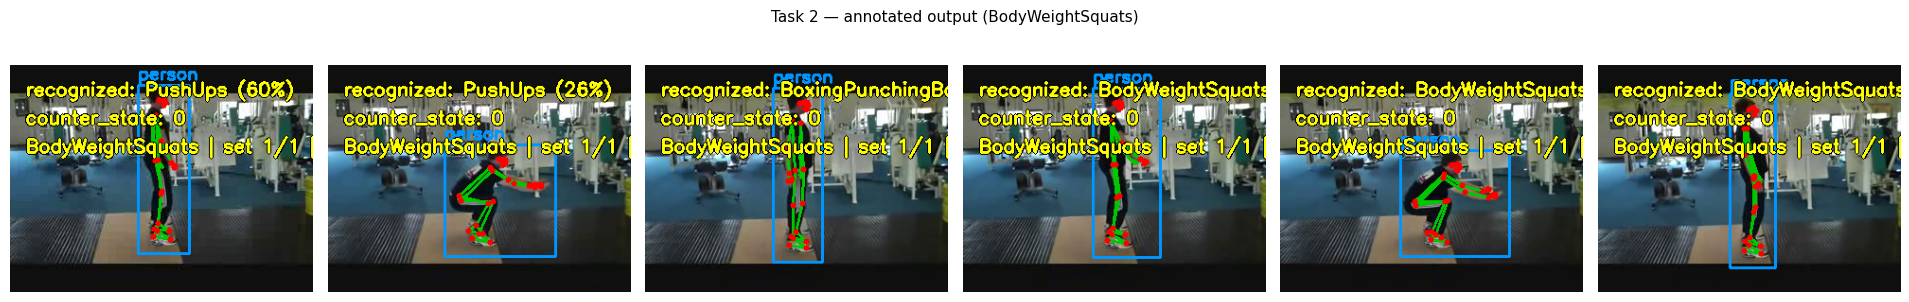

  exercise_recognized (majority): BodyWeightSquats (55% of frames)
  counter_state (final): 0
  counter_feedback: BodyWeightSquats | set 1/1 | rep 0/99 (99 to go) | last rep: n/a
  data quality: dropout=0.0%, range_sufficient=True, observed_range=54.6

CLIP 3/3: /test/BoxingPunchingBag/v_BoxingPunchingBag_g08_c06.avi
Ground truth: BoxingPunchingBag
  Task 3: 123 frames processed, 107 poses detected (87%)


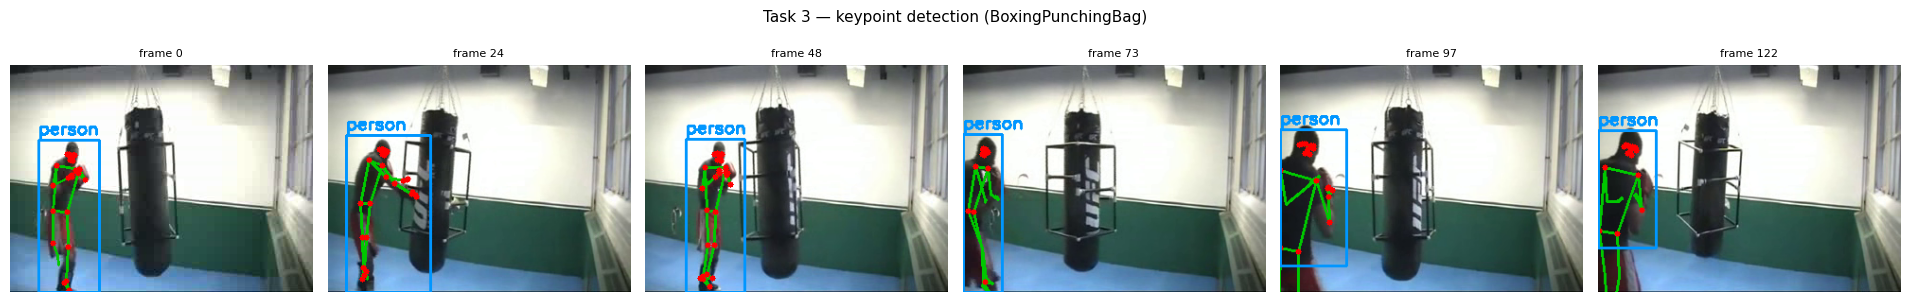

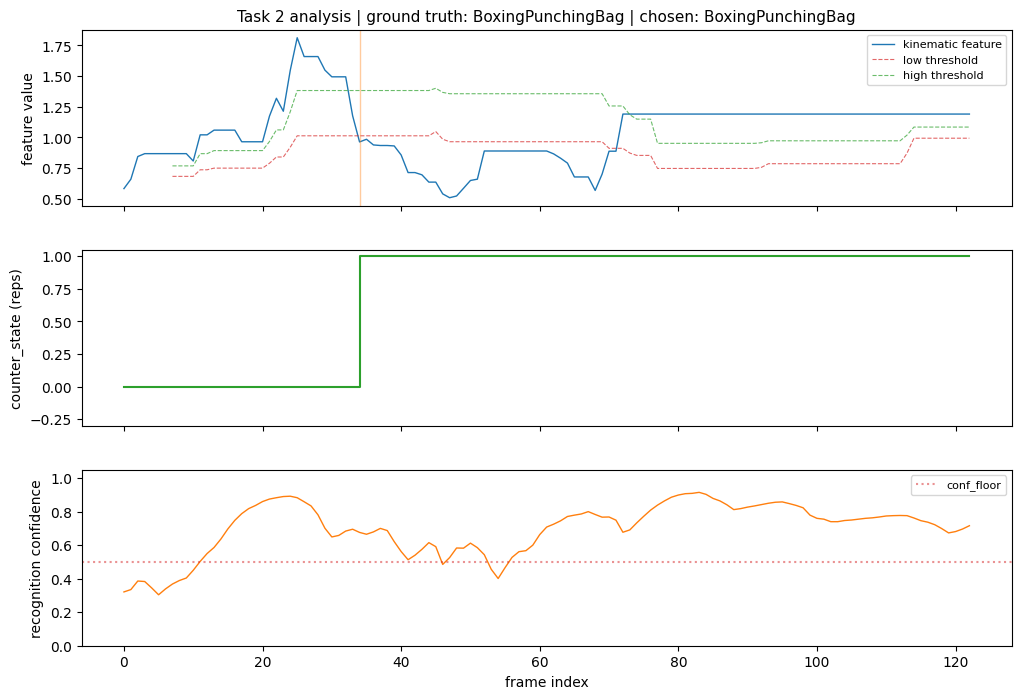

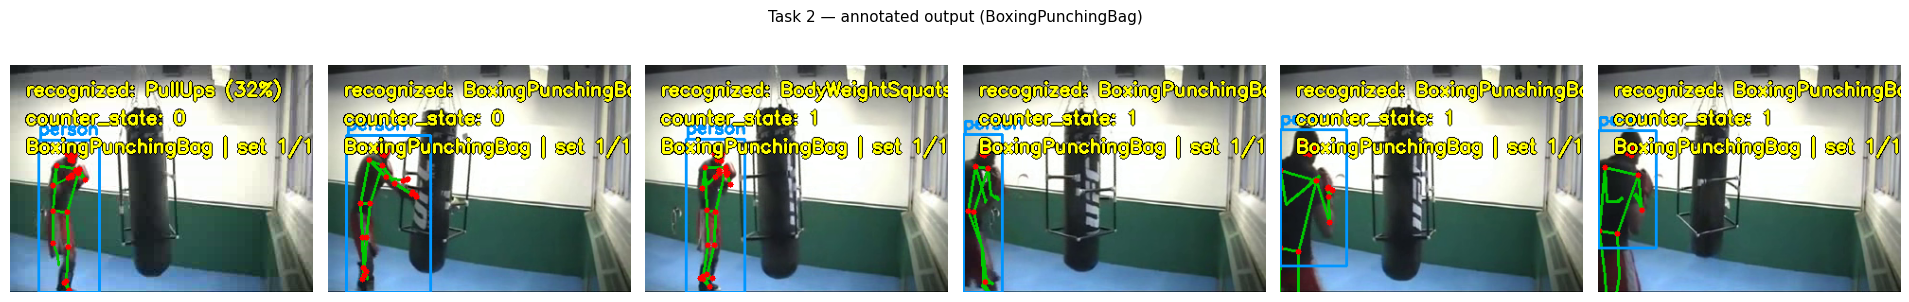

  exercise_recognized (majority): BoxingPunchingBag (89% of frames)
  counter_state (final): 1
  counter_feedback: BoxingPunchingBag | set 1/1 | rep 1/99 (98 to go) | last rep: full
  data quality: dropout=13.0%, range_sufficient=True, observed_range=2.6
  per-rep ROM: [1.2]


In [ ]:
N_DEMO_CLIPS = 3    # change to 9 for all classes

np.random.seed(None)                             # truly random each run
selected = (df_test.groupby("label")
                   .sample(1)
                   .sample(min(N_DEMO_CLIPS, len(CLASSES)))
                   .reset_index(drop=True))
print(f"Randomly selected {len(selected)} clips for the demo:\n")
display(selected[["label", "clip_path"]])

for clip_idx, (_, row) in enumerate(selected.iterrows()):
    print(f"\n{'='*80}")
    print(f"CLIP {clip_idx+1}/{len(selected)}: {row['clip_path']}")
    print(f"Ground truth: {row['label']}")
    print(f"{'='*80}")
    _ = run_demo_clip(video_full_path(row["clip_path"]), row["label"])

### Using a custom video

To run the pipeline on your own recording (e.g. a video of yourself performing an exercise),
replace the clip path and specify the exercise you are performing:

```python
custom_path     = "path/to/your/video.mp4"
your_exercise   = "PushUps"          # one of the 7 supported exercises
your_reps       = 10                  # reps per set target
your_sets       = 3                   # number of sets

_ = run_demo_clip(custom_path, ground_truth=your_exercise,
                  chosen_exercise=your_exercise,
                  reps_per_set=your_reps, n_sets=your_sets,
                  require_match=True)
```

When `require_match=True` the counter only advances while the recogniser identifies the chosen
exercise with sufficient confidence — this is the full interaction model from the specification.

## Conclusion

We implemented Task 2 exactly as specified: a **keypoint-based signal-processing** module that
consumes the Task-3 keypoint stream and, for each frame, returns `exercise_recognized`,
`counter_state` and `counter_feedback`.

* **Recognition** trains both a **2D** (x,y) and a **3D** (x,y,z) MLP + BiLSTM classifier and
  auto-selects the one with higher validation accuracy (`USE_3D` records the winner).
* **Counting** is a new **online adaptive FSM** validated offline against FFT and peak-detection
  methods across all 9 exercises.
* **Posture assessment** reports per-rep range of motion plus non-corrective data-quality
  diagnostics.
* **Integration** in `VirtualCoachSession` realises the full interaction model, gating the
  counter on recognition so it only advances while the user performs the chosen exercise.

**Honest limitations.** (i) Recognition confidence is low until the sliding window fills.
(ii) Near-axial camera viewpoints can compress a joint angle. (iii) Counter parameters are
engineering defaults tuned to the processed frame-rate. (iv) Posture feedback is heuristic,
not a clinical biomechanical assessment.


---
# Live demo integrata (Task 1 + Task 2 + Task 3) — dashboard web

Le celle seguenti sono riprese **verbatim** da
`virtual_coach_demo_integrata_SERIA_LAST(...).ipynb` (con sole minime correzioni Kaggle
marcate `# [KAGGLE FIX]`). Riusano il classificatore Task 2 (`clf`, `USE_3D`,
`VirtualCoachSession`, `EXERCISE_FEATURE`, ...) e il detector Task 3 (`detector`, `draw_pose`)
**già definiti sopra**: il blocco "4b · Setup Task 2 + Task 3" dell'originale — che ricaricava
gli stessi oggetti da `best_2d.pt`/`best_3d.pt` — è quindi **omesso** (su Kaggle quei file non
esistono e ricaricarli darebbe errore).

> **Su Kaggle non c'è né webcam né telefono**: la dashboard parte, la webcam mostra un
> placeholder e Task 1 resta in attesa dei dati phyphox (timeout senza errori). La demo è
> pensata per la presentazione **in locale**. Su Kaggle serve solo a verificare che tutto il
> codice sia definito e non sollevi eccezioni.


# Virtual Coach — Demo integrata Task 1 + 2 + 3 (live, unica pagina web)

Demo live che unisce i tre task in **una sola dashboard web**:
- **Task 1** (telefono, IMU) — riconoscimento attività (Standing/Walking/Laying) con calibrazione fisica.
- **Task 3** (webcam) — pose estimation: scheletro (keypoint) disegnato in tempo reale.
- **Task 2** (webcam) — conteggio delle ripetizioni dello squat in tempo reale.

### File necessari nella cartella
```
task1_models/  (inception_model.keras, scaler_raw.pkl, label_encoder.pkl)
task3_module.py
best_2d.pt   best_3d.pt   meta.json
models/   (pose_landmarker_full.task viene scaricato al primo avvio)
```
### Ordine di esecuzione
1. Celle 0–4 (setup Task 1)
2. Celle Task 2/3 (setup pose + classificatore + counter)
3. Calibrazione fisica (5.0 → 5.3) + override (5.5)
4. Demo live (cella 6)


## 0 · Configurazione

In [ ]:
# ============================================================================
#  PANNELLO DI CONTROLLO — cambia questi flag prima della dimostrazione.
# ============================================================================

# --- Esercizio della demo (fisso per questo progetto) -----------------------
CHOSEN_EXERCISE = "BodyWeightSquats"
REPS_PER_SET    = 5      # ripetizioni per set che chiedi all'utente
N_SETS          = 2     # numero di set

# --- Task 1 (telefono / phyphox) -------------------------------------------
SIMULATE_TASK1  = False   # True = dati IMU sintetici (nessun telefono richiesto)
                          # False = legge dal telefono via phyphox (vedi sezione Task 1)
PHYPHOX_URL     = "http://172.20.10.1"   # <-- IP mostrato da phyphox sul telefono

# --- Task 2/3 (webcam) ------------------------------------------------------
SIMULATE_WEBCAM = False   # True = usa una clip del dataset (nessuna webcam richiesta)
                          # False = usa la webcam del computer in tempo reale
WEBCAM_INDEX    = 0      # indice della webcam (0 = predefinita)
LIVE_MAX_SECONDS = 2400    # durata massima della cattura live (secondi)
TASK1_RAW_MODEL_NAME = "inception_model.keras"
print("Demo configurata per:", CHOSEN_EXERCISE,
      f"| {N_SETS} set x {REPS_PER_SET} rip.")
print(f"  Task 1  -> {'SIMULAZIONE' if SIMULATE_TASK1 else 'TELEFONO (phyphox)'}")
print(f"  Task 2/3-> {'SIMULAZIONE (clip)' if SIMULATE_WEBCAM else 'WEBCAM live'}")


Demo configurata per: BodyWeightSquats | 2 set x 5 rip.
  Task 1  -> TELEFONO (phyphox)
  Task 2/3-> WEBCAM live


## 1 · Import (Task 1)

In [ ]:
import os, sys, json, time, math, urllib.request
from pathlib import Path
from collections import deque, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.signal import find_peaks

# OpenCV is needed for the webcam / clip path (Task 2/3). phyphox path needs none.
try:
    import cv2
    HAVE_CV2 = True
except Exception as e:
    HAVE_CV2 = False
    print("OpenCV non disponibile:", e)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NOTEBOOK_DIR = Path(".")
print("Device:", DEVICE, "| OpenCV:", HAVE_CV2)


Device: cuda | OpenCV: True


## 2 · Preprocessing IMU (Task 1)

In [ ]:
# ── 2.1  Parsing + ricampionamento + costruzione finestra UCI-HAR ───────────
TARGET_HZ   = 50.0
WIN_SAMPLES = 128                      # UCI-HAR window length
HAR_CLASSES = ['Walking','Upstairs','Downstairs','Sitting','Standing','Laying']

def phyphox_get(base_url, buffers, timeout=2.0):
    '''Query phyphox /get for a list of buffer names; return {name: np.array}.'''
    q = "&".join(f"{b}=full" for b in buffers)
    url = f"{base_url.rstrip('/')}/get?{q}"
    with urllib.request.urlopen(url, timeout=timeout) as r:
        js = json.loads(r.read().decode("utf-8"))
    out = {}
    for b in buffers:
        node = js.get("buffer", {}).get(b, {})
        out[b] = np.asarray(node.get("buffer", []), dtype=np.float64)
    return out, js.get("status", {})

def resample_uniform(t, X, target_hz=TARGET_HZ, n_out=WIN_SAMPLES):
    '''Linear-interpolate (T,C) sampled at times t onto a uniform grid of n_out
    points ending at t[-1] with spacing 1/target_hz.'''
    t = np.asarray(t, float); X = np.asarray(X, float)
    if len(t) < 2 or X.shape[0] != len(t):
        return None
    t = t - t[0]; t_end = t[-1]; span = (n_out - 1) / target_hz
    grid = np.linspace(max(0.0, t_end - span), t_end, n_out)
    out = np.empty((n_out, X.shape[1]), np.float64)
    for c in range(X.shape[1]):
        out[:, c] = np.interp(grid, t, X[:, c])
    return out

# ============================================================================
# BUILD HAR WINDOW — versione UCI-HAR-like per dati phyphox
#
# Input:
#   acc_u : accelerometro phyphox, shape (128, 3), unità m/s²
#   gyr_u : giroscopio phyphox, shape (128, 3), unità rad/s
#
# Output:
#   win : shape (128, 9), ordine compatibile con UCI HAR:
#         body_acc_x, body_acc_y, body_acc_z,
#         body_gyro_x, body_gyro_y, body_gyro_z,
#         total_acc_x, total_acc_y, total_acc_z
# ============================================================================

import numpy as np
from scipy.signal import butter, filtfilt

G_CONST = 9.80665
UCI_FS = 50.0
UCI_GRAVITY_CUTOFF_HZ = 0.3

# Correzione assi opzionale.
# Per iniziare lasciala identità.
# Se il telefono è fissato in modo diverso puoi modificare questi due parametri.
AXIS_ORDER = [0, 1, 2]
AXIS_SIGN  = [1, 1, 1]

GYRO_AXIS_ORDER = [0, 1, 2]
GYRO_AXIS_SIGN  = [1, 1, 1]


def _apply_axis_mapping(x, order, sign):
    """
    Riordina e/o cambia segno agli assi.

    x     : array (T, 3)
    order : esempio [0, 1, 2]
    sign  : esempio [1, -1, 1]
    """
    x = np.asarray(x, dtype=np.float32)
    y = x[:, order].copy()
    y = y * np.asarray(sign, dtype=np.float32).reshape(1, 3)
    return y.astype(np.float32)


def _estimate_gravity_lowpass(total_acc_g, fs=UCI_FS, cutoff=UCI_GRAVITY_CUTOFF_HZ):
    """
    Stima la gravità con filtro passa-basso, come concetto UCI HAR:
    total_acc = body_acc + gravity_acc.

    total_acc_g: accelerazione totale in g, shape (128, 3)
    """
    total_acc_g = np.asarray(total_acc_g, dtype=np.float32)

    # Se la finestra è troppo corta per filtfilt, fallback con media mobile/mean.
    if total_acc_g.shape[0] < 30:
        gravity = np.repeat(
            total_acc_g.mean(axis=0, keepdims=True),
            total_acc_g.shape[0],
            axis=0,
        )
        return gravity.astype(np.float32)

    try:
        nyq = 0.5 * fs
        b, a = butter(
            N=3,
            Wn=cutoff / nyq,
            btype="low",
        )
        gravity = filtfilt(b, a, total_acc_g, axis=0)
        return gravity.astype(np.float32)

    except Exception:
        # Fallback robusto: stima gravità come media della finestra.
        gravity = np.repeat(
            total_acc_g.mean(axis=0, keepdims=True),
            total_acc_g.shape[0],
            axis=0,
        )
        return gravity.astype(np.float32)


def build_har_window(acc_u, gyr_u):
    """
    Costruisce la finestra raw 128x9 per il modello Task 1 raw.

    Questa versione è pensata per phyphox:
    - acc_u arriva in m/s²;
    - UCI HAR raw lavora in scala g-like;
    - il modello vuole body_acc, body_gyro, total_acc.
    """

    acc_u = np.asarray(acc_u, dtype=np.float32)
    gyr_u = np.asarray(gyr_u, dtype=np.float32)

    if acc_u.shape != (WIN_SAMPLES, 3):
        raise ValueError(f"acc_u shape attesa {(WIN_SAMPLES, 3)}, ottenuta {acc_u.shape}")

    if gyr_u.shape != (WIN_SAMPLES, 3):
        raise ValueError(f"gyr_u shape attesa {(WIN_SAMPLES, 3)}, ottenuta {gyr_u.shape}")

    # 1. Applica eventuale mapping degli assi.
    acc_mps2 = _apply_axis_mapping(acc_u, AXIS_ORDER, AXIS_SIGN)
    gyr      = _apply_axis_mapping(gyr_u, GYRO_AXIS_ORDER, GYRO_AXIS_SIGN)

    # 2. Converti accelerazione phyphox da m/s² a g.
    #    Questo è fondamentale: dal tuo debug accZ ≈ 9.81,
    #    mentre UCI HAR lavora in scala circa ±1 g.
    total_acc_g = acc_mps2 / G_CONST

    # 3. Stima gravità e calcola body acceleration.
    gravity_acc_g = _estimate_gravity_lowpass(
        total_acc_g,
        fs=UCI_FS,
        cutoff=UCI_GRAVITY_CUTOFF_HZ,
    )

    body_acc_g = total_acc_g - gravity_acc_g

    # 4. Costruisci i 9 canali nell'ordine esatto del training UCI HAR.
    win = np.column_stack([
        body_acc_g[:, 0],
        body_acc_g[:, 1],
        body_acc_g[:, 2],
        gyr[:, 0],
        gyr[:, 1],
        gyr[:, 2],
        total_acc_g[:, 0],
        total_acc_g[:, 1],
        total_acc_g[:, 2],
    ]).astype(np.float32)

    return win

def activity_gate(acc_u, gyr_u, thresh=0.08):
    '''Model-free STANDING/MOVING gate from signal energy. Robust and fast.'''
    a = acc_u / 9.81
    body_std = float(np.std(a - a.mean(0)))
    gyro_mag = float(np.mean(np.linalg.norm(gyr_u, axis=1)))
    motion = body_std + 0.5*gyro_mag
    return ("STANDING" if motion < thresh else "MOVING"), motion

print("Task 1 — funzioni di acquisizione/adattamento IMU pronte.")


Task 1 — funzioni di acquisizione/adattamento IMU pronte.


## 3 · Sorgente IMU live (Task 1)

In [ ]:
# ============================================================================
# 2.3 — Sorgente IMU: telefono phyphox REAL-TIME oppure simulazione
#
# Questa versione è corretta per il tuo phyphox:
# /get?accX&accY&... restituisce 1 campione alla volta.
# Quindi il notebook accumula campioni live fino a costruire una finestra 128x3.
# ============================================================================

import time
import requests
import numpy as np
from scipy.signal import resample

# Cache globale: accumula i campioni letti live dal telefono
PHYPHOX_ACC_CACHE = []
PHYPHOX_GYR_CACHE = []
PHYPHOX_LAST_SAMPLE = None


def _phyphox_read_one_sample(base_url=None, timeout=1.5):
    """
    Legge un singolo campione corrente da phyphox.

    Ritorna:
        acc: np.array shape (3,)
        gyr: np.array shape (3,)
    oppure:
        None, None
    """

    if base_url is None:
        base_url = PHYPHOX_URL

    base_url = base_url.rstrip("/")

    # Nomi corretti trovati dal tuo config phyphox
    names = ["accX", "accY", "accZ", "gyrX", "gyrY", "gyrZ"]
    url = base_url + "/get?" + "&".join(names)

    try:
        r = requests.get(url, timeout=timeout)
        r.raise_for_status()
        payload = r.json()

        buffers = payload.get("buffer", {})

        values = []

        for name in names:
            if name not in buffers:
                return None, None

            obj = buffers[name]

            if isinstance(obj, dict):
                arr = obj.get("buffer", obj.get("data", []))
            else:
                arr = obj

            if arr is None or len(arr) == 0:
                return None, None

            # Nel tuo caso len=1: prendo l'ultimo valore
            values.append(float(arr[-1]))

        acc = np.array(values[:3], dtype=np.float32)
        gyr = np.array(values[3:], dtype=np.float32)

        if not np.all(np.isfinite(acc)) or not np.all(np.isfinite(gyr)):
            return None, None

        return acc, gyr

    except Exception:
        return None, None


def _resample_matrix(x, n_samples):
    """
    Ricampiona matrice shape (N, C) a shape (n_samples, C).
    """
    x = np.asarray(x, dtype=np.float32)

    if x.ndim != 2:
        raise ValueError(f"Attesa matrice 2D, ottenuta {x.shape}")

    if x.shape[0] == n_samples:
        return x.astype(np.float32)

    return resample(x, n_samples, axis=0).astype(np.float32)


def read_imu_window(
    simulate=False,
    sim_activity="standing",
    base_url=None,
    target_samples=None,
    collection_seconds=3.0,
    poll_interval=0.03,
    min_samples_before_resample=30,
):
    """
    Restituisce:
        acc_u: shape (WIN_SAMPLES, 3)
        gyr_u: shape (WIN_SAMPLES, 3)

    In modalità live:
        - legge campioni reali da phyphox;
        - accumula una finestra temporale;
        - ricampiona a WIN_SAMPLES = 128;
        - non usa dati sintetici.

    Nota:
        collection_seconds=3.0 significa che alla prima chiamata aspetta circa 3s
        per riempire la finestra. Poi le chiamate successive usano la cache già piena.
    """

    global PHYPHOX_ACC_CACHE, PHYPHOX_GYR_CACHE, PHYPHOX_LAST_SAMPLE

    if target_samples is None:
        target_samples = WIN_SAMPLES

    # Compatibilità con vecchia simulazione
    if simulate:
        return simulate_imu(sim_activity=sim_activity)

    if base_url is None:
        base_url = PHYPHOX_URL

    base_url = base_url.rstrip("/")

    t0 = time.time()

    # Alla prima chiamata, oppure se la cache è troppo corta, accumulo campioni live
    while len(PHYPHOX_ACC_CACHE) < min_samples_before_resample:
        acc, gyr = _phyphox_read_one_sample(base_url=base_url)

        if acc is not None and gyr is not None:
            current_sample = tuple(np.round(np.concatenate([acc, gyr]), 6))

            # Evita di aggiungere duplicati identici se phyphox non ha aggiornato
            if current_sample != PHYPHOX_LAST_SAMPLE:
                PHYPHOX_ACC_CACHE.append(acc)
                PHYPHOX_GYR_CACHE.append(gyr)
                PHYPHOX_LAST_SAMPLE = current_sample

        if time.time() - t0 > collection_seconds:
            break

        time.sleep(poll_interval)

    # Anche nelle chiamate successive aggiungo qualche nuovo campione,
    # così la finestra resta aggiornata in real time.
    short_update_steps = 5

    for _ in range(short_update_steps):
        acc, gyr = _phyphox_read_one_sample(base_url=base_url)

        if acc is not None and gyr is not None:
            current_sample = tuple(np.round(np.concatenate([acc, gyr]), 6))

            if current_sample != PHYPHOX_LAST_SAMPLE:
                PHYPHOX_ACC_CACHE.append(acc)
                PHYPHOX_GYR_CACHE.append(gyr)
                PHYPHOX_LAST_SAMPLE = current_sample

        time.sleep(poll_interval)

    # Tengo solo gli ultimi campioni per non far crescere la cache all'infinito
    max_cache_len = 300
    PHYPHOX_ACC_CACHE = PHYPHOX_ACC_CACHE[-max_cache_len:]
    PHYPHOX_GYR_CACHE = PHYPHOX_GYR_CACHE[-max_cache_len:]

    if len(PHYPHOX_ACC_CACHE) < min_samples_before_resample or len(PHYPHOX_GYR_CACHE) < min_samples_before_resample:
        print(
            f"phyphox letto, ma pochi campioni accumulati: "
            f"acc={len(PHYPHOX_ACC_CACHE)}, gyr={len(PHYPHOX_GYR_CACHE)}. "
            f"Aspetta qualche secondo con phyphox in PLAY."
        )
        return None, None

    acc = np.vstack(PHYPHOX_ACC_CACHE).astype(np.float32)
    gyr = np.vstack(PHYPHOX_GYR_CACHE).astype(np.float32)

    # Allineamento di sicurezza
    n = min(len(acc), len(gyr))
    acc = acc[-n:]
    gyr = gyr[-n:]

    # Ricampiona agli 128 campioni richiesti dal modello Task 1
    acc_u = _resample_matrix(acc, target_samples)
    gyr_u = _resample_matrix(gyr, target_samples)

    return acc_u, gyr_u


def reset_phyphox_cache():
    """
    Utile prima di rilanciare una demo pulita.
    """
    global PHYPHOX_ACC_CACHE, PHYPHOX_GYR_CACHE, PHYPHOX_LAST_SAMPLE

    PHYPHOX_ACC_CACHE = []
    PHYPHOX_GYR_CACHE = []
    PHYPHOX_LAST_SAMPLE = None

    print("Cache phyphox svuotata.")


print("Task 1 — sorgente IMU phyphox REAL-TIME pronta.")

Task 1 — sorgente IMU phyphox REAL-TIME pronta.


## 4 · Modello Task 1

In [ ]:
# ============================================================================
# TASK 1 LIVE — USA IL MODELLO RAW ESPORTATO DAL NOTEBOOK TASK 1
# Output reale: Walking, Upstairs, Downstairs, Sitting, Standing, Laying
# Nessun fallback activity_gate come classificatore.
# ============================================================================

import numpy as np
import joblib
from pathlib import Path

try:
    import tensorflow as tf
except ImportError:
    raise ImportError(
        "TensorFlow non è installato. Installa con: pip install tensorflow"
    )

# Se NOTEBOOK_DIR non esiste già nel notebook, uso la cartella corrente
try:
    NOTEBOOK_DIR
except NameError:
    NOTEBOOK_DIR = Path.cwd()

HAR_CLASSES = ["Walking", "Upstairs", "Downstairs", "Sitting", "Standing", "Laying"]

HAR_ID_TO_NAME = {
    1: "Walking",
    2: "Upstairs",
    3: "Downstairs",
    4: "Sitting",
    5: "Standing",
    6: "Laying",
}

# Nome modello raw da usare
try:
    TASK1_RAW_MODEL_NAME
except NameError:
    TASK1_RAW_MODEL_NAME = "inception_model.keras"


def decode_task1_label(raw_label):
    """
    Il LabelEncoder del Task 1 è fittato sulle label numeriche 1-6.
    Questa funzione converte:
        1 -> Walking
        2 -> Upstairs
        ...
        6 -> Laying
    """
    if isinstance(raw_label, bytes):
        raw_label = raw_label.decode("utf-8")

    if isinstance(raw_label, str):
        try:
            raw_label_int = int(raw_label)
            return HAR_ID_TO_NAME.get(raw_label_int, raw_label)
        except Exception:
            return raw_label

    try:
        raw_label_int = int(raw_label)

        if raw_label_int in HAR_ID_TO_NAME:
            return HAR_ID_TO_NAME[raw_label_int]

        if 0 <= raw_label_int < len(HAR_CLASSES):
            return HAR_CLASSES[raw_label_int]

    except Exception:
        pass

    return str(raw_label)


def har_label_to_gate(label):
    """
    Gate secondario solo per la dashboard.
    La label principale rimane quella a 6 classi del modello.
    """
    return "STANDING" if label == "Standing" else "MOVING"


def _find_task1_file(filename):
    """
    Cerca il file dentro:
      - task1_models/
      - models_task1/
      - sottocartelle del notebook
    """
    candidates = []

    # [KAGGLE FIX] cerca anche sotto /kaggle/input: i dataset Kaggle (qui task1_models)
    # sono montati read-only li', non nella working dir.
    _search_roots = [NOTEBOOK_DIR]
    _kaggle_input = Path("/kaggle/input")
    if _kaggle_input.exists():
        _search_roots.append(_kaggle_input)

    for _root in _search_roots:
        for folder_name in ["task1_models", "models_task1"]:
            folder = _root / folder_name
            if folder.exists():
                candidates.extend(list(folder.rglob(filename)))
        candidates.extend(list(_root.rglob(filename)))

    if len(candidates) == 0:
        return None

    return candidates[0]


# ---------------------------------------------------------------------------
# Caricamento modello raw + scaler_raw + label_encoder
# ---------------------------------------------------------------------------

task1_model_path = _find_task1_file(TASK1_RAW_MODEL_NAME)

if task1_model_path is None:
    # fallback di ricerca se il nome scelto non esiste
    for alt_name in [
        "inception_model.keras",
        "inception_model.h5",
        "cnn_lstm_model.keras",
        "cnn_lstm_model.h5",
        "transformer_model.keras",
        "transformer_model.h5",
    ]:
        task1_model_path = _find_task1_file(alt_name)
        if task1_model_path is not None:
            print(f"Modello richiesto non trovato. Uso invece: {alt_name}")
            break

scaler_raw_path = _find_task1_file("scaler_raw.pkl")
label_encoder_path = _find_task1_file("label_encoder.pkl")

# [KAGGLE FIX] Caricamento reso NON fatale: su Kaggle non c'e' ne' telefono ne' webcam,
# quindi la live demo non puo' comunque funzionare davvero; se il modello Task 1 manca o
# non e' caricabile (es. mismatch di versione TF/Keras) il notebook NON deve crashare.
# In tal caso task1_raw_model resta None e le funzioni a valle restituiscono un default.
TASK1_MODEL_OK = False
task1_raw_model = scaler_raw_t1 = label_encoder_t1 = None
try:
    if task1_model_path is None:
        raise FileNotFoundError("Nessun modello raw Task 1 trovato (inception_model.keras).")
    if scaler_raw_path is None:
        raise FileNotFoundError("scaler_raw.pkl non trovato.")
    if label_encoder_path is None:
        raise FileNotFoundError("label_encoder.pkl non trovato.")

    task1_raw_model = tf.keras.models.load_model(task1_model_path)
    scaler_raw_t1 = joblib.load(scaler_raw_path)
    label_encoder_t1 = joblib.load(label_encoder_path)
    TASK1_MODEL_OK = True

    print("=" * 70)
    print("TASK 1 RAW MODEL CARICATO")
    print("Modello       :", task1_model_path)
    print("Scaler raw    :", scaler_raw_path)
    print("Label encoder :", label_encoder_path)
    print("Input shape   :", task1_raw_model.input_shape)
    print("Output shape  :", task1_raw_model.output_shape)
    print("=" * 70)
except Exception as _e:
    print("=" * 70)
    print("[KAGGLE FIX] TASK 1 RAW MODEL NON caricato:", _e)
    print("La live demo integrata resta eseguibile ma Task 1 mostrera' 'NO MODEL'.")
    print("Per usarla in locale (telefono+webcam) metti in task1_models/ i file:")
    print("  inception_model.keras, scaler_raw.pkl, label_encoder.pkl")
    print("=" * 70)


# ---------------------------------------------------------------------------
# Classi ordinate secondo il LabelEncoder
# ---------------------------------------------------------------------------

def get_ordered_class_names_from_encoder(le, n_classes=6):
    """
    Per i modelli Keras l'output softmax è ordinato come le classi codificate:
    indice 0 -> le.inverse_transform([0])
    indice 1 -> le.inverse_transform([1])
    ecc.
    """
    names = []

    for idx in range(n_classes):
        try:
            raw = le.inverse_transform([idx])[0]
            names.append(decode_task1_label(raw))
        except Exception:
            names.append(HAR_CLASSES[idx])

    return names


if TASK1_MODEL_OK:                                   # [KAGGLE FIX]
    TASK1_CLASS_NAMES_ORDERED = get_ordered_class_names_from_encoder(
        label_encoder_t1,
        n_classes=6,
    )
else:
    TASK1_CLASS_NAMES_ORDERED = list(HAR_CLASSES)

print("Classi modello:", TASK1_CLASS_NAMES_ORDERED)


# ---------------------------------------------------------------------------
# Preprocessing identico al notebook Task 1:
# scaler_raw.fit_transform(X_train_raw.reshape(-1, C)).reshape(N, T, C)
# ---------------------------------------------------------------------------

def prepare_live_window_for_task1_model(win_9ch):
    """
    win_9ch: array (128, 9), prodotto da build_har_window(acc_u, gyr_u)

    Restituisce input pronto per il modello Keras:
        shape (1, 128, 9)
    """

    x = np.asarray(win_9ch, dtype=np.float32)

    if x.shape != (WIN_SAMPLES, 9):
        raise ValueError(
            f"Finestra IMU non valida: atteso {(WIN_SAMPLES, 9)}, ottenuto {x.shape}"
        )

    # Nel Task 1 lo scaler_raw è fittato sui 9 canali:
    # X_train_raw.reshape(-1, C), con C = 9
    x_scaled = scaler_raw_t1.transform(x.reshape(-1, 9)).reshape(1, WIN_SAMPLES, 9)

    # Adattamento automatico alla shape del modello
    input_shape = task1_raw_model.input_shape

    if isinstance(input_shape, list):
        input_shape = input_shape[0]

    expected = tuple(input_shape[1:])

    if expected == (WIN_SAMPLES, 9):
        return x_scaled.astype(np.float32)

    if expected == (9, WIN_SAMPLES):
        return np.transpose(x_scaled, (0, 2, 1)).astype(np.float32)

    if expected == (WIN_SAMPLES, 9, 1):
        return x_scaled[..., np.newaxis].astype(np.float32)

    if expected == (WIN_SAMPLES * 9,):
        return x_scaled.reshape(1, -1).astype(np.float32)

    raise ValueError(
        f"Input shape del modello non gestita: {input_shape}. "
        "Il modello dovrebbe accettare (128, 9), (9, 128), (128, 9, 1) o 1152 feature."
    )


def task1_predict_real_model(win_9ch):
    """
    Predizione vera del Task 1 usando il modello raw Keras.

    Output:
        label: una tra Walking, Upstairs, Downstairs, Sitting, Standing, Laying
        probs: dizionario probabilità per tutte le 6 classi
    """

    if not TASK1_MODEL_OK:                          # [KAGGLE FIX]
        return "NO MODEL", {c: 0.0 for c in HAR_CLASSES}

    x_in = prepare_live_window_for_task1_model(win_9ch)

    y = task1_raw_model.predict(x_in, verbose=0)
    y = np.asarray(y)

    if y.ndim == 2:
        y = y[0]

    # Normalizzazione di sicurezza
    y = y.astype(np.float64)

    if np.any(y < 0) or not np.isclose(np.sum(y), 1.0, atol=1e-2):
        y = y - np.max(y)
        y = np.exp(y)
        y = y / np.sum(y)
    else:
        y = y / np.sum(y)

    probs = {}

    for i, p in enumerate(y):
        if i < len(TASK1_CLASS_NAMES_ORDERED):
            class_name = TASK1_CLASS_NAMES_ORDERED[i]
        else:
            class_name = f"class_{i}"

        probs[class_name] = float(p)

    # Garantisce che la dashboard abbia sempre le 6 classi
    for c in HAR_CLASSES:
        probs.setdefault(c, 0.0)

    label = max(probs, key=probs.get)

    return label, probs


print("Funzione task1_predict_real_model() pronta.")

I0000 00:00:1782939294.120281      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 12938 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1782939294.125753      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


TASK 1 RAW MODEL CARICATO
Modello       : /kaggle/input/datasets/umbertodipalma/task1-models/inception_model.keras
Scaler raw    : /kaggle/input/datasets/umbertodipalma/task1-models/scaler_raw.pkl
Label encoder : /kaggle/input/datasets/umbertodipalma/task1-models/label_encoder.pkl
Input shape   : (None, 128, 9)
Output shape  : (None, 6)
Classi modello: ['Walking', 'Upstairs', 'Downstairs', 'Sitting', 'Standing', 'Laying']
Funzione task1_predict_real_model() pronta.


## 5 · Calibrazione fisica Task 1

In [ ]:
# ── 5.0  Classificatore fisico ────────────────────────────────────────────────
import numpy as np
import time as _t

CALIB = {}
CALIB_POSES = ["Standing", "Walking", "Laying"]

def _phys_features(acc_u):
    acc_u = np.asarray(acc_u, np.float32)
    g = acc_u.mean(axis=0)
    gmag = np.linalg.norm(g) + 1e-6
    comp = np.abs(g) / gmag
    dyn = acc_u - g
    motion = float(np.linalg.norm(dyn.std(axis=0)))
    return comp, motion

def calibrate_pose(pose_name, seconds=6.0, n_windows=15):
    assert pose_name in CALIB_POSES
    print("=" * 60)
    print(f"CALIBRAZIONE: {pose_name}  —  mantieni la posa ~{seconds:.0f}s")
    print("=" * 60)
    reset_phyphox_cache()
    comps, motions = [], []
    t0 = _t.time()
    while len(comps) < n_windows:
        acc_u, gyr_u = read_imu_window(simulate=SIMULATE_TASK1, base_url=PHYPHOX_URL)
        if acc_u is None:
            if _t.time() - t0 > seconds + 15:
                print("Timeout."); return None
            _t.sleep(0.2); continue
        comp, motion = _phys_features(acc_u)
        comps.append(comp); motions.append(motion)
        try:
            win = build_har_window(acc_u, gyr_u)
            ml, _ = _original_task1_predict(win)
        except Exception:
            ml = "?"
        print(f"  {len(comps)}/{n_windows}  g={comp.round(2)}  motion={motion:.2f}  (modello: {ml})")
        _t.sleep(0.12)
    CALIB[pose_name] = {"comp": np.mean(comps, 0), "motion": float(np.mean(motions))}
    print(f"-> '{pose_name}' OK. Fatte: {list(CALIB.keys())}")

def classify_calibrated(acc_u, gyr_u, w_motion=1.5):
    if len(CALIB) < 3:
        try:
            win = build_har_window(acc_u, gyr_u)
            return _original_task1_predict(win)
        except:
            return "?", {c: 0.0 for c in HAR_CLASSES}
    comp, motion = _phys_features(acc_u)
    ms = max([CALIB[p]["motion"] for p in CALIB]) - min([CALIB[p]["motion"] for p in CALIB]) + 1e-6
    dists = {}
    for pose in CALIB_POSES:
        d_o = float(np.linalg.norm(comp - CALIB[pose]["comp"]))
        d_m = abs(motion - CALIB[pose]["motion"]) / ms
        dists[pose] = d_o + w_motion * d_m
    label = min(dists, key=dists.get)
    d = np.array([dists[p] for p in CALIB_POSES])
    inv = np.exp(-d / (d.mean() + 1e-6)); inv = inv / inv.sum()
    probs = {c: 0.0 for c in HAR_CLASSES}
    for i, p in enumerate(CALIB_POSES):
        probs[p] = float(inv[i])
    return label, probs

# Salva la funzione originale PRIMA di sovrascriverla
_original_task1_predict = task1_predict_real_model

print("Classificatore pronto. Esegui le 3 celle sotto.")


Classificatore pronto. Esegui le 3 celle sotto.


In [ ]:
calibrate_pose("Standing")

CALIBRAZIONE: Standing  —  mantieni la posa ~6s
Cache phyphox svuotata.
phyphox letto, ma pochi campioni accumulati: acc=0, gyr=0. Aspetta qualche secondo con phyphox in PLAY.
phyphox letto, ma pochi campioni accumulati: acc=0, gyr=0. Aspetta qualche secondo con phyphox in PLAY.
Timeout.


In [ ]:
# ── 5.2  WALKING ──────────────────────────────────────────────────────────
calibrate_pose("Walking")

CALIBRAZIONE: Walking  —  mantieni la posa ~6s
Cache phyphox svuotata.
phyphox letto, ma pochi campioni accumulati: acc=0, gyr=0. Aspetta qualche secondo con phyphox in PLAY.
phyphox letto, ma pochi campioni accumulati: acc=0, gyr=0. Aspetta qualche secondo con phyphox in PLAY.
Timeout.


In [ ]:
# ── 5.3  LAYING ───────────────────────────────────────────────────────────
calibrate_pose("Laying")

CALIBRAZIONE: Laying  —  mantieni la posa ~6s
Cache phyphox svuotata.
phyphox letto, ma pochi campioni accumulati: acc=0, gyr=0. Aspetta qualche secondo con phyphox in PLAY.
phyphox letto, ma pochi campioni accumulati: acc=0, gyr=0. Aspetta qualche secondo con phyphox in PLAY.
Timeout.


## 5.5 · Attiva il classificatore calibrato

In [ ]:
# ── 5.5  Override: ridirige task1_predict_real_model ──────────────────────────
# La cella demo chiama task1_predict_real_model(win) internamente.
# Qui la sostituiamo con una versione che usa il classificatore fisico.

def task1_predict_real_model(win):
    """Wrapper: classificatore fisico calibrato."""
    if len(CALIB) == 3 and len(PHYPHOX_ACC_CACHE) >= 10:
        acc_raw = np.array(list(PHYPHOX_ACC_CACHE))[-128:]
        n_gyr = len(PHYPHOX_GYR_CACHE)
        gyr_raw = np.array(list(PHYPHOX_GYR_CACHE))[-128:] if n_gyr >= 10 else np.zeros_like(acc_raw)
        return classify_calibrated(acc_raw, gyr_raw)
    return _original_task1_predict(win)

print("Override ATTIVO: la demo usera' il classificatore fisico calibrato.")
print(f"Calibrazione: {list(CALIB.keys())}")


Override ATTIVO: la demo usera' il classificatore fisico calibrato.
Calibrazione: []


## 6 · 🎬 Demo live integrata

Apre la pagina web unica: a sinistra la webcam con lo scheletro (Task 3) e il conteggio, a destra in alto il Task 1 (attività dal telefono) e in basso il contatore gigante degli squat (Task 2).

In [ ]:
# ============================================================================
#  DEMO LIVE — SOLO TASK 1 — PHONE ONLY + MODELLO RAW TASK 1
#
#  Sinistra: webcam live
#  Destra: output reale del modello Task 1:
#           Walking, Upstairs, Downstairs, Sitting, Standing, Laying
#
#  IMPORTANTE:
#  - Non usa dati sintetici.
#  - Non usa activity_gate come classificatore.
#  - Legge solo dal telefono via phyphox.
#  - Usa task1_predict_real_model(win), definita nella cella precedente.
# ============================================================================

import threading
import http.server
import webbrowser
import time as _time
import json
import datetime
import numpy as np

# ----------------------------------------------------------------------------
# Check dipendenze minime
# ----------------------------------------------------------------------------

try:
    task1_predict_real_model
except NameError:
    raise RuntimeError(
        "task1_predict_real_model() non è definita. "
        "Esegui prima la cella lunga che carica inception_model.keras, "
        "scaler_raw.pkl e label_encoder.pkl."
    )

try:
    read_imu_window
except NameError:
    raise RuntimeError("read_imu_window() non è definita. Esegui prima le celle Task 1.")

try:
    build_har_window
except NameError:
    raise RuntimeError("build_har_window() non è definita. Esegui prima le celle Task 1.")

try:
    PHYPHOX_URL
except NameError:
    raise RuntimeError("PHYPHOX_URL non è definito. Impostalo nel pannello di controllo.")

try:
    SIMULATE_WEBCAM
except NameError:
    SIMULATE_WEBCAM = False

try:
    WEBCAM_INDEX
except NameError:
    WEBCAM_INDEX = 0

try:
    HAVE_CV2
except NameError:
    try:
        import cv2
        HAVE_CV2 = True
    except Exception:
        HAVE_CV2 = False


HAR_CLASSES = ["Walking", "Upstairs", "Downstairs", "Sitting", "Standing", "Laying"]


def task1_label_to_context(label):
    """
    Contesto secondario per la dashboard.
    La classificazione principale resta la label a 6 classi.
    """
    if label in ["Standing", "Sitting", "Laying"]:
        return "STATIC"
    if label in ["Walking", "Upstairs", "Downstairs"]:
        return "MOVING"
    return "---"


# ----------------------------------------------------------------------------
# Ferma eventuale demo precedente
# ----------------------------------------------------------------------------

try:
    TASK1_STOP_EVENT.set()
except Exception:
    pass

try:
    _task1_live_server.shutdown()
except Exception:
    pass

TASK1_STOP_EVENT = threading.Event()

TASK1_CURRENT_FRAME = None

TASK1_LIVE_STATE = {
    "running": True,
    "connected": False,
    "label": "---",
    "context": "---",
    "confidence": 0.0,
    "motion": 0.0,
    "source": "---",
    "probs": {c: 0.0 for c in HAR_CLASSES},
    "status": "starting",
    "last_update": "---",
    "phyphox_url": PHYPHOX_URL,
}

# ── Stato aggiuntivo Task 2/3 ────────────────────────────────────────────────
TASK1_LIVE_STATE["t23_active"]     = False
TASK1_LIVE_STATE["exercise"]       = CHOSEN_EXERCISE
TASK1_LIVE_STATE["reps"]           = 0
TASK1_LIVE_STATE["reps_target"]    = REPS_PER_SET
TASK1_LIVE_STATE["set"]            = 1
TASK1_LIVE_STATE["sets_target"]    = N_SETS
TASK1_LIVE_STATE["t2_recognized"]  = "---"
TASK1_LIVE_STATE["t2_confidence"]  = 0.0
TASK1_LIVE_STATE["t2_feedback"]    = "In attesa..."
TASK1_LIVE_STATE["last_quality"]   = "n/a"
TASK1_LIVE_STATE["workout_complete"] = False
# ── Fase di posizionamento (start-pose gate) ─────────────────────────────────
TASK1_LIVE_STATE["phase"]          = "positioning"   # positioning | ready | exercising
TASK1_LIVE_STATE["start_pose"]     = "Standing"      # posa richiesta per l'esercizio scelto
TASK1_LIVE_STATE["hold_progress"]  = 0.0             # 0..1 (frazione dei 10s completata)
TASK1_LIVE_STATE["hold_seconds"]   = 0.0             # secondi tenuti finora
TASK1_LIVE_STATE["position_msg"]   = ""              # dicitura da mostrare



# ----------------------------------------------------------------------------
# Lettura reale dal telefono + predizione modello Task 1
# ----------------------------------------------------------------------------

def read_task1_from_phone_only():
    """
    Live Task 1:
      - legge i dati reali da phyphox;
      - costruisce la finestra 128x9;
      - usa il modello raw del Task 1;
      - restituisce una delle 6 classi reali.

    Non usa activity_gate come classificatore.
    """

    acc_u, gyr_u = read_imu_window(
        simulate=False,
        base_url=PHYPHOX_URL,
    )

    if acc_u is None or gyr_u is None:
        return {
            "ok": False,
            "connected": False,
            "label": "NO PHONE",
            "context": "---",
            "confidence": 0.0,
            "motion": 0.0,
            "source": "REAL PHONE IMU",
            "probs": {c: 0.0 for c in HAR_CLASSES},
            "status": (
                "Nessun dato reale dal telefono. "
                "Controlla: phyphox in PLAY, remote access attivo, stesso WiFi, "
                "URL corretto con :8080."
            ),
        }

    # Finestra UCI-HAR-like: shape (128, 9)
    win = build_har_window(acc_u, gyr_u)

    # Motion score solo diagnostico, non usato per classificare
    try:
        _, motion = activity_gate(acc_u, gyr_u)
    except Exception:
        motion = 0.0

    try:
        label, probs = task1_predict_real_model(win)

        # Garantisce che tutte le 6 classi siano presenti
        for c in HAR_CLASSES:
            probs.setdefault(c, 0.0)

        confidence = float(probs.get(label, 0.0))
        context = task1_label_to_context(label)

        return {
            "ok": True,
            "connected": True,
            "label": label,
            "context": context,
            "confidence": confidence,
            "motion": float(motion),
            "source": "REAL PHONE IMU + TASK 1 RAW MODEL",
            "probs": probs,
            "status": (
                "live: telefono connesso, modello Task 1 attivo, "
                "classificazione reale a 6 classi"
            ),
        }

    except Exception as e:
        return {
            "ok": False,
            "connected": True,
            "label": "MODEL ERROR",
            "context": "---",
            "confidence": 0.0,
            "motion": float(motion),
            "source": "REAL PHONE IMU + TASK 1 MODEL ERROR",
            "probs": {c: 0.0 for c in HAR_CLASSES},
            "status": f"Errore modello Task 1: {e}",
        }


# ----------------------------------------------------------------------------
# Thread aggiornamento Task 1
# ----------------------------------------------------------------------------

def _task1_update_loop(period=0.35):
    global TASK1_LIVE_STATE

    while not TASK1_STOP_EVENT.is_set():
        result = read_task1_from_phone_only()

        TASK1_LIVE_STATE.update({
            "connected": bool(result.get("connected", False)),
            "label": result.get("label", "---"),
            "context": result.get("context", "---"),
            "confidence": float(result.get("confidence", 0.0)),
            "motion": float(result.get("motion", 0.0)),
            "source": result.get("source", "---"),
            "probs": result.get("probs", {c: 0.0 for c in HAR_CLASSES}),
            "status": result.get("status", "---"),
            "last_update": datetime.datetime.now().strftime("%H:%M:%S"),
            "phyphox_url": PHYPHOX_URL,
        })

        _time.sleep(period)


# ----------------------------------------------------------------------------
# Webcam live
# ----------------------------------------------------------------------------

def _make_placeholder_frame(text="Webcam non disponibile"):
    img = np.zeros((480, 640, 3), dtype=np.uint8)

    if HAVE_CV2:
        cv2.putText(
            img,
            text,
            (35, 235),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (255, 255, 255),
            2,
            cv2.LINE_AA,
        )

    return img


def _camera_loop():
    global TASK1_CURRENT_FRAME

    if not HAVE_CV2:
        print("OpenCV non disponibile: webcam non mostrabile.")
        return

    # Posa di partenza richiesta in base all'esercizio scelto
    LAYING_EXERCISES = {"PushUps"}
    start_pose = "Laying" if CHOSEN_EXERCISE in LAYING_EXERCISES else "Standing"
    pose_msg = ("Posizionarsi sdraiati per iniziare l'esercizio"
                if start_pose == "Laying"
                else "Posizionarsi in piedi per iniziare l'esercizio")
    HOLD_REQUIRED = 10.0   # secondi di posa corretta richiesti

    TASK1_LIVE_STATE["start_pose"]   = start_pose
    TASK1_LIVE_STATE["phase"]        = "positioning"
    TASK1_LIVE_STATE["position_msg"] = pose_msg

    # Sessione Task 2 (creata ora ma il conteggio parte solo dopo il gate)
    session = VirtualCoachSession(
        CHOSEN_EXERCISE, REPS_PER_SET, N_SETS, clf, WINDOW,
        IDX_TO_CLASS, CLASS_TO_IDX, require_match=False, use_3d=USE_3D)
    TASK1_LIVE_STATE["t23_active"] = True

    cap = None
    if not SIMULATE_WEBCAM:
        cap = cv2.VideoCapture(WEBCAM_INDEX)

    if SIMULATE_WEBCAM or cap is None or not cap.isOpened():
        if cap is not None:
            cap.release()
        print("Webcam non disponibile: mostro placeholder.")
        while not TASK1_STOP_EVENT.is_set():
            img = _make_placeholder_frame("Webcam non disponibile")
            ok, jpeg = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 85])
            if ok:
                TASK1_CURRENT_FRAME = jpeg.tobytes()
            _time.sleep(0.10)
        return

    print("Webcam aperta correttamente.")

    # Stato del gate di posizionamento
    hold_start = None        # timestamp di inizio posa corretta continuativa
    exercising = False       # True dopo che il gate e' superato

    try:
        while not TASK1_STOP_EVENT.is_set():
            ok, frame = cap.read()
            if not ok:
                img = _make_placeholder_frame("Frame webcam non letto")
                ok2, jpeg = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 85])
                if ok2:
                    TASK1_CURRENT_FRAME = jpeg.tobytes()
                _time.sleep(0.03)
                continue

            frame = cv2.flip(frame, 1)

            # ── Task 3: pose estimation (sempre attiva, mostra lo scheletro) ──
            try:
                arr = detector.detect_array(frame)
            except Exception:
                arr = None

            # Posa attuale rilevata dal Task 1 (telefono)
            current_pose = TASK1_LIVE_STATE.get("label", "---")

            # ═══ FASE 1: POSIZIONAMENTO (gate di 10s) ═══════════════════════
            if not exercising:
                now = _time.time()
                if current_pose == start_pose:
                    if hold_start is None:
                        hold_start = now
                    held = now - hold_start
                    TASK1_LIVE_STATE["hold_seconds"]  = round(held, 1)
                    TASK1_LIVE_STATE["hold_progress"] = min(1.0, held / HOLD_REQUIRED)
                    if held >= HOLD_REQUIRED:
                        exercising = True
                        TASK1_LIVE_STATE["phase"]        = "exercising"
                        TASK1_LIVE_STATE["position_msg"] = "Posizione corretta raggiunta"
                    else:
                        TASK1_LIVE_STATE["phase"]        = "ready"
                        rem = int(np.ceil(HOLD_REQUIRED - held))
                        TASK1_LIVE_STATE["position_msg"] = f"Mantieni la posa... {rem}s"
                else:
                    # posa persa: azzera il timer
                    hold_start = None
                    TASK1_LIVE_STATE["hold_seconds"]  = 0.0
                    TASK1_LIVE_STATE["hold_progress"] = 0.0
                    TASK1_LIVE_STATE["phase"]         = "positioning"
                    TASK1_LIVE_STATE["position_msg"]  = pose_msg

                # In questa fase il conteggio NON parte; mostra solo lo scheletro
                if arr is not None:
                    img = draw_pose(frame, arr, draw_box=False)
                else:
                    img = frame
                # HUD posizionamento
                cv2.rectangle(img, (10, 10), (630, 58), (0, 0, 0), -1)
                held_txt = TASK1_LIVE_STATE.get("hold_seconds", 0.0)
                cv2.putText(img, f"Task1: {current_pose}  |  posizionamento {held_txt:.0f}/10s",
                            (22, 42), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2, cv2.LINE_AA)
                ok3, jpeg = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 85])
                if ok3:
                    TASK1_CURRENT_FRAME = jpeg.tobytes()
                _time.sleep(0.01)
                continue

            # ═══ FASE 2: ESERCIZIO (Task 2 + Task 3 attivi) ═════════════════
            out = session.process_frame(arr)
            TASK1_LIVE_STATE["reps"]          = out["counter_state"]
            TASK1_LIVE_STATE["set"]           = out["current_set"]
            TASK1_LIVE_STATE["t2_recognized"] = out["exercise_recognized"]
            TASK1_LIVE_STATE["t2_confidence"] = out["recognized_confidence"]
            TASK1_LIVE_STATE["t2_feedback"]   = out["counter_feedback"]["text"]
            TASK1_LIVE_STATE["last_quality"]  = out["counter_feedback"]["last_rep_quality"]
            TASK1_LIVE_STATE["workout_complete"] = out["workout_complete"]
            TASK1_LIVE_STATE["phase"]         = "exercising"

            if arr is not None:
                img = draw_pose(frame, arr, draw_box=False)
            else:
                img = frame

            reps = out["counter_state"]
            cv2.rectangle(img, (10, 10), (630, 58), (0, 0, 0), -1)
            cv2.putText(img, f"Task1: {current_pose}   |   {CHOSEN_EXERCISE}: {reps}/{REPS_PER_SET}",
                        (22, 42), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2, cv2.LINE_AA)

            ok3, jpeg = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 85])
            if ok3:
                TASK1_CURRENT_FRAME = jpeg.tobytes()

            _time.sleep(0.01)
    finally:
        cap.release()


# ----------------------------------------------------------------------------
# HTML dashboard
# ----------------------------------------------------------------------------

TASK1_LIVE_HTML = r"""
<!DOCTYPE html>
<html lang="it">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Virtual Coach — Live Demo</title>
<style>
* { box-sizing: border-box; margin: 0; padding: 0; }
body { height: 100vh; background: #0d1117; color: white;
       font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", sans-serif; overflow: hidden; }
.wrapper { display: grid; grid-template-columns: 56% 44%; height: 100vh; }
.left { background: #000; border-right: 3px solid #30363d; display: flex;
        align-items: center; justify-content: center; position: relative; }
.left img { width: 100%; height: 100%; object-fit: contain; }
.badge { position: absolute; top: 16px; left: 16px; background: rgba(0,0,0,0.75);
         border: 1px solid #30363d; border-radius: 10px; padding: 8px 14px;
         font-size: 15px; font-weight: 700; }
.right { display: grid; grid-template-rows: auto 1fr; height: 100vh; overflow: hidden; }

/* ── Task 1 (in alto) ── */
.t1 { padding: 20px 28px; border-bottom: 2px solid #30363d; }
.t1 .title { color: #8b949e; text-transform: uppercase; letter-spacing: 2px;
             font-size: 14px; font-weight: 700; margin-bottom: 8px; }
.t1-row { display: flex; align-items: center; gap: 18px; }
.main-label { font-size: clamp(30px, 4vw, 52px); line-height: 1; font-weight: 900; }
.context { padding: 6px 14px; border-radius: 999px; font-size: 18px; font-weight: 800;
           background: #21262d; border: 2px solid #58a6ff; color: #58a6ff; }
.context.moving { color: #d29922; border-color: #d29922; }
.context.static { color: #3fb950; border-color: #3fb950; }
.context.error  { color: #f85149; border-color: #f85149; }
.t1-meta { margin-top: 10px; color: #8b949e; font-size: 14px; }

/* ── Task 2/3 (in basso, protagonista) ── */
.t23 { display: flex; flex-direction: column; align-items: center; justify-content: center;
       padding: 16px; gap: 6px; position: relative; }
.t23 .ex-name { font-size: clamp(18px, 2.4vw, 28px); font-weight: 700; color: #58a6ff; }
.t23 .reps { font-size: clamp(120px, 30vh, 300px); font-weight: 900; line-height: 0.9;
             font-variant-numeric: tabular-nums; text-shadow: 0 0 60px rgba(88,166,255,0.35); }
.t23 .reps-sub { font-size: clamp(16px, 2vh, 24px); color: #8b949e; }
.progress-wrap { width: 82%; height: 14px; background: #21262d; border-radius: 999px;
                 overflow: hidden; margin-top: 6px; }
.progress-bar { height: 100%; width: 0%; background: linear-gradient(90deg,#238636,#3fb950);
                border-radius: 999px; transition: width 0.35s ease; }
.t23 .feedback { font-size: clamp(13px, 1.6vh, 17px); color: #8b949e; text-align: center;
                 margin-top: 8px; max-width: 90%; }
.t23 .recog { font-size: 14px; color: #6e7681; margin-top: 2px; }

/* overlay completato */
.done-overlay { position: absolute; inset: 0; background: rgba(35,134,54,0.96);
                display: none; flex-direction: column; align-items: center;
                justify-content: center; gap: 18px; z-index: 20; }
.done-overlay .check { font-size: 22vh; line-height: 1; }
.done-overlay .msg { font-size: clamp(28px, 6vh, 60px); font-weight: 800; }
.done-overlay .detail { font-size: clamp(15px, 2.5vh, 24px); color: rgba(255,255,255,0.85); }

/* overlay di posizionamento */
.pos-overlay { position: absolute; inset: 0; background: rgba(13,17,23,0.97);
               display: flex; flex-direction: column; align-items: center;
               justify-content: center; gap: 18px; z-index: 15; text-align: center; padding: 24px; }
.pos-overlay .pos-icon { font-size: 12vh; line-height: 1; }
.pos-overlay .pos-msg { font-size: clamp(22px, 4vh, 44px); font-weight: 800; color: #d29922;
                        max-width: 92%; }
.pos-ring-wrap { position: relative; width: 160px; height: 160px; margin-top: 8px; }
.pos-ring { width: 160px; height: 160px; border-radius: 50%;
            background: conic-gradient(#3fb950 0deg, #21262d 0deg); transition: background 0.2s; }
.pos-ring::after { content: ""; position: absolute; inset: 16px; border-radius: 50%;
                   background: #0d1117; }
.pos-count { position: absolute; inset: 0; display: flex; align-items: center;
             justify-content: center; font-size: 46px; font-weight: 900;
             font-variant-numeric: tabular-nums; }
.pos-ok { display: none; font-size: clamp(20px, 3.5vh, 36px); font-weight: 800; color: #3fb950; }
.pos-overlay.ready-ok .pos-icon { display: none; }
.pos-overlay.ready-ok .pos-msg { display: none; }
.pos-overlay.ready-ok .pos-ring-wrap { display: none; }
.pos-overlay.ready-ok .pos-ok { display: block; }
</style>
</head>
<body>
<div class="wrapper">
    <section class="left">
        <div class="badge">Task 3 — Pose Estimation (webcam live)</div>
        <img src="/video" alt="Webcam stream">
    </section>

    <section class="right">
        <!-- Task 1 -->
        <div class="t1">
            <div class="title">Task 1 — Activity Recognition (IMU telefono)</div>
            <div class="t1-row">
                <div id="label" class="main-label">---</div>
                <div id="context" class="context">---</div>
            </div>
            <div class="t1-meta">
                <span id="confidence">conf: 0%</span> &nbsp;·&nbsp;
                <span id="motion">motion: 0.000</span> &nbsp;·&nbsp;
                <span id="status">starting</span>
            </div>
        </div>

        <!-- Task 2/3 -->
        <div class="t23">
            <div class="ex-name" id="ex-name">Squat</div>
            <div class="reps" id="reps">0</div>
            <div class="reps-sub" id="reps-sub">0 / 0</div>
            <div class="progress-wrap"><div class="progress-bar" id="progress"></div></div>
            <div class="feedback" id="feedback">In attesa dell'esercizio...</div>
            <div class="recog" id="recog"></div>

            <div class="done-overlay" id="done">
                <div class="check">&#10003;</div>
                <div class="msg">COMPLETATO!</div>
                <div class="detail" id="done-detail"></div>
            </div>

            <div class="pos-overlay" id="pos">
                <div class="pos-icon" id="pos-icon">&#128587;</div>
                <div class="pos-msg" id="pos-msg">Posizionarsi per iniziare</div>
                <div class="pos-ring-wrap">
                    <div class="pos-ring" id="pos-ring"></div>
                    <div class="pos-count" id="pos-count"></div>
                </div>
                <div class="pos-ok" id="pos-ok">Posizione corretta raggiunta</div>
            </div>
        </div>
    </section>
</div>

<script>
function pct(x){ return Math.round((x||0)*100); }
let lastReps = 0;
let audioCtx = null;
function beep(freq, dur, n){
    if(!audioCtx) audioCtx = new (window.AudioContext||window.webkitAudioContext)();
    let t = audioCtx.currentTime;
    for(let i=0;i<n;i++){
        const o=audioCtx.createOscillator(), g=audioCtx.createGain();
        o.connect(g); g.connect(audioCtx.destination); o.frequency.value=freq;
        g.gain.setValueAtTime(0.6, t+i*(dur+0.12));
        g.gain.exponentialRampToValueAtTime(0.01, t+i*(dur+0.12)+dur);
        o.start(t+i*(dur+0.12)); o.stop(t+i*(dur+0.12)+dur);
    }
}

async function poll(){
    try{
        const s = await (await fetch("/status",{cache:"no-store"})).json();

        // ── Task 1 ──
        document.getElementById("label").textContent = s.label || "---";
        const ctx = document.getElementById("context");
        ctx.textContent = s.context || "---";
        const cl = String(s.context||"").toLowerCase();
        const ll = String(s.label||"").toLowerCase();
        if(ll.includes("error")||ll.includes("phone")) ctx.className="context error";
        else if(cl==="moving") ctx.className="context moving";
        else if(cl==="static") ctx.className="context static";
        else ctx.className="context";
        document.getElementById("confidence").textContent = "conf: "+pct(s.confidence)+"%";
        document.getElementById("motion").textContent = "motion: "+Number(s.motion||0).toFixed(3);
        document.getElementById("status").textContent = s.status || "";

        // ── Task 2/3 ──
        document.getElementById("ex-name").textContent = s.exercise || "Squat";
        document.getElementById("reps").textContent = s.reps ?? 0;
        document.getElementById("reps-sub").textContent =
            (s.reps ?? 0) + " / " + (s.reps_target ?? 0) +
            "   (set " + (s.set ?? 1) + "/" + (s.sets_target ?? 1) + ")";
        const prog = Math.min(100, (s.reps ?? 0) / Math.max(s.reps_target ?? 1, 1) * 100);
        document.getElementById("progress").style.width = prog + "%";
        document.getElementById("feedback").textContent = s.t2_feedback || "";
        document.getElementById("recog").textContent =
            "riconosciuto: " + (s.t2_recognized || "---") + " (" + pct(s.t2_confidence) + "%)";

        // beep ad ogni nuova ripetizione
        if((s.reps ?? 0) > lastReps){ beep(1047, 0.08, 1); lastReps = s.reps; }

        // ── Fase di posizionamento (start-pose gate) ──
        const pos = document.getElementById("pos");
        const phase = s.phase || "positioning";
        if(phase === "positioning" || phase === "ready"){
            pos.style.display = "flex";
            pos.classList.remove("ready-ok");
            document.getElementById("pos-msg").textContent = s.position_msg || "Posizionarsi per iniziare";
            document.getElementById("pos-icon").innerHTML =
                (String(s.start_pose||"").toLowerCase()==="laying") ? "&#127946;" : "&#128694;";
            const prog = Math.max(0, Math.min(1, s.hold_progress || 0));
            const deg = prog * 360;
            document.getElementById("pos-ring").style.background =
                "conic-gradient(#3fb950 " + deg + "deg, #21262d " + deg + "deg)";
            const remain = Math.max(0, Math.ceil(10 - (s.hold_seconds || 0)));
            document.getElementById("pos-count").textContent = remain;
        } else if(phase === "exercising"){
            // Mostra brevemente "Posizione corretta raggiunta" poi nascondi
            if(!window._posDoneShown){
                window._posDoneShown = true;
                pos.classList.add("ready-ok");
                pos.style.display = "flex";
                beep(880, 0.25, 1);
                setTimeout(function(){ pos.style.display = "none"; }, 1500);
            }
        }

        // completamento
        const done = document.getElementById("done");
        if(s.workout_complete){
            if(done.style.display !== "flex"){
                done.style.display = "flex";
                document.getElementById("done-detail").textContent =
                    (s.sets_target ?? 1) + " x " + (s.reps_target ?? 0) + " " + (s.exercise || "");
                beep(1047, 0.2, 3);
            }
        } else {
            done.style.display = "none";
        }
    }catch(e){
        document.getElementById("status").textContent = "Errore dashboard: " + e;
    }
    setTimeout(poll, 180);
}
poll();
</script>
</body>
</html>
"""


# ----------------------------------------------------------------------------
# HTTP server
# ----------------------------------------------------------------------------

class _Task1LiveHandler(http.server.BaseHTTPRequestHandler):

    def do_GET(self):
        if self.path == "/":
            self._send(
                200,
                "text/html; charset=utf-8",
                TASK1_LIVE_HTML.encode("utf-8"),
            )

        elif self.path == "/status":
            body = json.dumps(TASK1_LIVE_STATE).encode("utf-8")
            self._send(
                200,
                "application/json",
                body,
                extra={"Cache-Control": "no-cache"},
            )

        elif self.path.startswith("/video"):
            self.send_response(200)
            self.send_header(
                "Content-Type",
                "multipart/x-mixed-replace; boundary=frame",
            )
            self.send_header("Cache-Control", "no-cache")
            self.end_headers()

            try:
                while not TASK1_STOP_EVENT.is_set():
                    frame = TASK1_CURRENT_FRAME

                    if frame is not None:
                        self.wfile.write(b"--frame\r\n")
                        self.wfile.write(b"Content-Type: image/jpeg\r\n\r\n")
                        self.wfile.write(frame)
                        self.wfile.write(b"\r\n")
                        self.wfile.flush()

                    _time.sleep(0.05)

            except (BrokenPipeError, ConnectionResetError, OSError):
                pass

        else:
            self.send_response(404)
            self.end_headers()

    def _send(self, code, content_type, body, extra=None):
        self.send_response(code)
        self.send_header("Content-Type", content_type)

        if extra:
            for k, v in extra.items():
                self.send_header(k, v)

        self.end_headers()
        self.wfile.write(body)

    def log_message(self, *args):
        pass


# ----------------------------------------------------------------------------
# Avvio / stop demo
# ----------------------------------------------------------------------------

def run_task1_live_demo(port=8775):
    """
    Avvia:
      1. server web;
      2. thread Task 1;
      3. thread webcam;
      4. browser su localhost.
    """

    global _task1_live_server

    chosen_port = None

    for p in range(port, port + 20):
        try:
            _task1_live_server = http.server.ThreadingHTTPServer(
                ("127.0.0.1", p),
                _Task1LiveHandler,
            )
            chosen_port = p
            break
        except OSError:
            continue

    if chosen_port is None:
        raise RuntimeError("Nessuna porta libera trovata per la dashboard.")

    threading.Thread(
        target=_task1_live_server.serve_forever,
        daemon=True,
    ).start()

    threading.Thread(
        target=_task1_update_loop,
        daemon=True,
    ).start()

    threading.Thread(
        target=_camera_loop,
        daemon=True,
    ).start()

    url = f"http://localhost:{chosen_port}"

    print("=" * 80)
    print("DEMO LIVE TASK 1 AVVIATA")
    print("=" * 80)
    print("Dashboard :", url)
    print("phyphox   :", PHYPHOX_URL)
    print("Task 1    : REAL PHONE IMU + TASK 1 RAW MODEL")
    print("Webcam    :", "placeholder" if SIMULATE_WEBCAM else f"indice {WEBCAM_INDEX}")
    print()
    print("Output possibili:")
    for c in HAR_CLASSES:
        print(" -", c)
    print()
    print("Per fermare la demo esegui: stop_task1_live_demo()")
    print("=" * 80)

    _time.sleep(0.5)
    webbrowser.open(url)


def stop_task1_live_demo():
    """
    Ferma la demo live Task 1.
    """

    TASK1_STOP_EVENT.set()

    try:
        _task1_live_server.shutdown()
    except Exception:
        pass

    TASK1_LIVE_STATE["running"] = False
    TASK1_LIVE_STATE["status"] = "stopped"

    print("Demo Task 1 fermata.")


# Avvio automatico
run_task1_live_demo()

DEMO LIVE TASK 1 AVVIATA
Dashboard : http://localhost:8775
phyphox   : http://172.20.10.1
Task 1    : REAL PHONE IMU + TASK 1 RAW MODEL
Webcam    : indice 0

Output possibili:
 - Walking
 - Upstairs
 - Downstairs
 - Sitting
 - Standing
 - Laying

Per fermare la demo esegui: stop_task1_live_demo()
Webcam non disponibile: mostro placeholder.


[ WARN:1@3109.515] global cap_v4l.cpp:914 open VIDEOIO(V4L2:/dev/video0): can't open camera by index
[ WARN:1@3109.533] global cap.cpp:438 open VIDEOIO(FFMPEG): raised OpenCV exception:

OpenCV(4.13.0) /io/opencv/modules/videoio/src/cap_ffmpeg_impl.hpp:1220: error: (-2:Unspecified error) in function 'bool CvCapture_FFMPEG::open(const char*, int, const cv::Ptr<cv::IStreamReader>&, const cv::VideoCaptureParameters&)'
> VIDEOIO/FFMPEG: Camera index out of range (expected: 'index < device_list->nb_devices'), where
>     'index' is 0
> must be less than
>     'device_list->nb_devices' is 0


[ERROR:1@3109.535] global obsensor_uvc_stream_channel.cpp:163 getStreamChannelGroup Camera index out of range


## 7 · Ferma la demo

In [ ]:
stop_task1_live_demo()

Demo Task 1 fermata.
phyphox letto, ma pochi campioni accumulati: acc=0, gyr=0. Aspetta qualche secondo con phyphox in PLAY.
